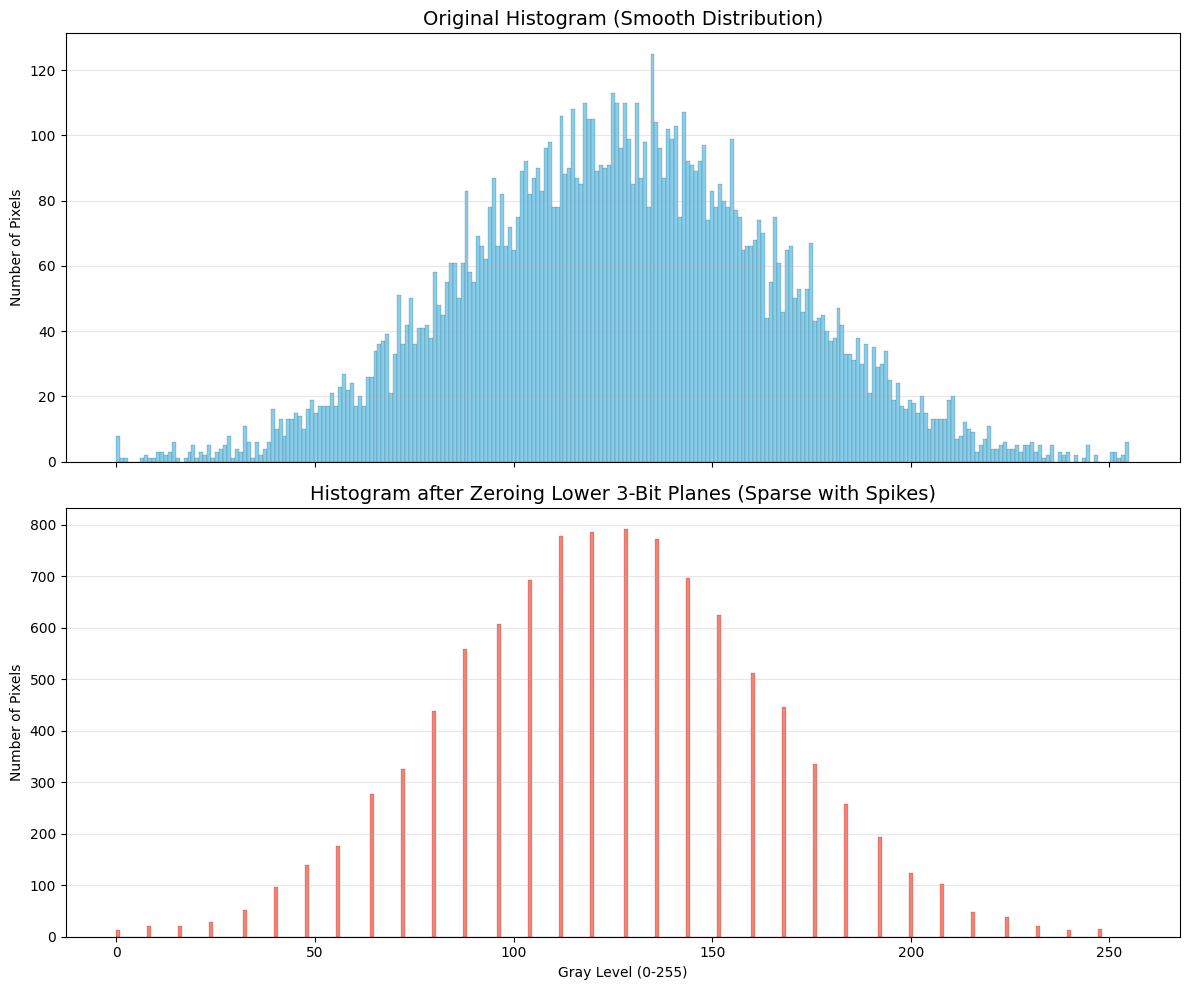

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a "normal" image histogram
# We'll create 10,000 pixels with a random distribution centered around 128
np.random.seed(42)
original_pixels = np.random.normal(loc=128, scale=40, size=10000).astype(int)
original_pixels = np.clip(original_pixels, 0, 255)

# 2. Zero out the lower-order bit planes (last 3 bits)
# Mathematically, zeroing the last 3 bits is the same as:
# (value // 8) * 8
processed_pixels = (original_pixels // 8) * 8

# Create the visualization
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Plot Original Histogram
ax1.hist(original_pixels, bins=256, color='skyblue', edgecolor='black', linewidth=0.1)
ax1.set_title("Original Histogram (Smooth Distribution)", fontsize=14)
ax1.set_ylabel("Number of Pixels")
ax1.grid(axis='y', alpha=0.3)

# Plot Processed Histogram
ax2.hist(processed_pixels, bins=256, color='salmon', edgecolor='black', linewidth=0.1)
ax2.set_title("Histogram after Zeroing Lower 3-Bit Planes (Sparse with Spikes)", fontsize=14)
ax2.set_xlabel("Gray Level (0-255)")
ax2.set_ylabel("Number of Pixels")
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
!pip install requests SPARQLWrapper dateparser spacy requests
!python -m spacy download en_core_web_sm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 300.4/300.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.4/615.4 kB 7.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 47.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp drive/MyDrive/Thesis/.env .
# !ls drive

In [ ]:
import os
import subprocess
import time

# 1. Install system dependencies (zstd), Ollama binary, and Python library
print("Installing zstd and Ollama...")
!apt-get install -y zstd
!curl -fsSL https://ollama.com/install.sh | sh
!pip install ollama -q

# 2. Start Ollama server in the background
print("Starting Ollama server...")
process = subprocess.Popen(["ollama", "serve"],
                           stdout=subprocess.PIPE,
                           stderr=subprocess.PIPE)

# Give the server a few seconds to initialize
time.sleep(10)
print("Ollama is running in the background.")

Installing zstd and Ollama...
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 3 not upgraded.
Need to get 603 kB of archives.
After this operation, 1,695 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 zstd amd64 1.4.8+dfsg-3build1 [603 kB]
Fetched 603 kB in 0s (12.5 MB/s)
Selecting previously unselected package zstd.
(Reading database ... 118252 files and directories currently installed.)
Preparing to unpack .../zstd_1.4.8+dfsg-3build1_amd64.deb ...
Unpacking zstd (1.4.8+dfsg-3build1) ...
Setting up zstd (1.4.8+dfsg-3build1) ...
Processing triggers for man-db (2.10.2-1) ...
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Cre

In [ ]:
import ollama

# 3. Pull a small model (like llama3.2:1b or tinyllama) to verify it works
print("Pulling tinyllama model (this may take a minute)...")
ollama.pull('tinyllama')

# 4. Simple API Test
response = ollama.chat(model='tinyllama', messages=[
  {
    'role': 'user',
    'content': 'Say hello!',
  },
])

print("\nOllama Response:")
print(response['message']['content'])

Pulling tinyllama model (this may take a minute)...


ConnectionError: Failed to connect to Ollama. Please check that Ollama is downloaded, running and accessible. https://ollama.com/download

In [ ]:
from pickleshare import time
import os
import dotenv
import requests

GEMINI_API_KEY=""
dotenv.load_dotenv()
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")

def call_gemini(prompt: str):
  url = "https://generativelanguage.googleapis.com/v1beta/models/gemini-3.1-flash-lite-preview:generateContent"
  headers = {
    "x-goog-api-key": GEMINI_API_KEY,
    "Content-Type": "application/json",
  }
  response = requests.post(url, headers=headers, json={
      "contents": [
          {
              "role": "user",
              "parts": [
                  {
                      "text": prompt
                  }
              ]
          }
      ]
  })

  while response.status_code == 503:
    print("Model unavailable. Trying again after 5 seconds.")
    time.sleep(5)
    response = requests.post(url, headers=headers, json={
      "contents": [
          {
              "role": "user",
              "parts": [
                  {
                      "text": prompt
                  }
              ]
          }
      ]
    })

  return response.json()

def get_response(response: dict):
  # return response
  return response["candidates"][0]["content"]["parts"][0]["text"]


response = call_gemini("Who is Albert Einsten? Who do you think is smarter? Einstein or Newton?")
print(get_response(response))

### Who is Albert Einstein?

Albert Einstein (1879–1955) was a German-born theoretical physicist who is widely considered one of the most influential scientists of all time. He is best known for developing the **theory of relativity**, which revolutionized our understanding of space, time, gravity, and the universe.

Key highlights of his life and work include:
*   **The Miracle Year (1905):** In a single year, he published four groundbreaking papers: the photoelectric effect (which won him the Nobel Prize), Brownian motion, special relativity, and the mass-energy equivalence formula, **$E=mc^2$**.
*   **General Relativity (1915):** He expanded his work to describe gravity not as a force, but as a curvature of spacetime caused by mass and energy. This predicted phenomena like black holes, the bending of starlight by gravity, and gravitational waves.
*   **Cultural Icon:** Beyond physics, he was a vocal advocate for pacifism, civil rights, and intellectual freedom. His name has become s

In [ ]:
import requests

def search_wikipedia_page(entity_name: str):
    url = "https://en.wikipedia.org/w/api.php"
    headers = {"User-Agent": "ColabWikipediaSearchBot/1.0 (https://colab.research.google.com/)"}
    params = {
        "action": "opensearch",
        "search": entity_name,
        "limit": "10",
        "namespace": "0",
        "format": "json"
    }
    try:
        response = requests.get(url, headers=headers, params=params, timeout=10)
        response.raise_for_status() # Raise an HTTPError for bad responses (4xx or 5xx)
        data = response.json()
        print(data)
        # opensearch returns a list: [search_term, [titles], [descriptions], [urls]]
        if data and len(data) > 3 and data[1]: # Check if titles list is not empty
            page_title = data[1][0]
            page_url = data[3][0]
            return page_title, page_url
        else:
            return None, None
    except requests.exceptions.RequestException as e:
        print(f"[Wikipedia API Error] {e}")
        return None, None

print("✓ Wikipedia search function loaded")

✓ Wikipedia search function loaded


Now, let's test the `search_wikipedia_page` function with an example.

In [ ]:
entity = "Tensor"
title, url = search_wikipedia_page(entity)

if title and url:
    print(f"Found Wikipedia page for '{entity}':")
    print(f"  Title: {title}")
    print(f"  URL: {url}")
else:
    print(f"No Wikipedia page found for '{entity}'.")

entity = "NonExistentEntity123"
title, url = search_wikipedia_page(entity)

if title and url:
    print(f"\nFound Wikipedia page for '{entity}':")
    print(f"  Title: {title}")
    print(f"  URL: {url}")
else:
    print(f"\nNo Wikipedia page found for '{entity}'.")

['Tensor', ['Tensor', 'TensorFlow', 'Tensor product', 'Tensor Processing Unit', 'Tensor operator', 'Tensor rank decomposition', 'Tensor product of modules', 'Tensors in curvilinear coordinates', 'Tensor derivative (continuum mechanics)', 'Tensor (machine learning)'], ['', '', '', '', '', '', '', '', '', ''], ['https://en.wikipedia.org/wiki/Tensor', 'https://en.wikipedia.org/wiki/TensorFlow', 'https://en.wikipedia.org/wiki/Tensor_product', 'https://en.wikipedia.org/wiki/Tensor_Processing_Unit', 'https://en.wikipedia.org/wiki/Tensor_operator', 'https://en.wikipedia.org/wiki/Tensor_rank_decomposition', 'https://en.wikipedia.org/wiki/Tensor_product_of_modules', 'https://en.wikipedia.org/wiki/Tensors_in_curvilinear_coordinates', 'https://en.wikipedia.org/wiki/Tensor_derivative_(continuum_mechanics)', 'https://en.wikipedia.org/wiki/Tensor_(machine_learning)']]
Found Wikipedia page for 'Tensor':
  Title: Tensor
  URL: https://en.wikipedia.org/wiki/Tensor
['NonExistentEntity123', [], [], []]



In [ ]:
claim = "Albert Einstein was born on 14 March 1879 in Ulm, Germany."

prompt = f"""
Task: extract the date, type of the date (e.g., birth_date, publication_date, or death_date), entity (e.g., person, or place) from the claim.
If there exists multiple such dates or entities, for each date, date type, or entities create multiple json entries.
claim:

Output format:
[
  {{
      "date": "...",
      "type": "...",
      "entity": "...",
  }}
]
"""
response = call_gemini(prompt)
print(get_response(response))

```json
[
  {
      "date": "14 March 1879",
      "type": "birth_date",
      "entity": "Albert Einstein"
  },
  {
      "date": "14 March 1879",
      "type": "birth_date",
      "entity": "Ulm, Germany"
  }
]
```


In [ ]:
claim = "Albert Einstein was born on 14 March 1879 in Ulm, Germany."

prompt = f"""
Task: extract the date, type of the date (e.g., birth_date, publication_date, or death_date), entity (e.g., person, or place) from the claim.
If there exists multiple such dates or entities, for each date, date type, or entities create multiple json entries.
claim: {claim}

Output format:
[
  {{
      "date": "...",
      "type": "...",
      "entity": "...",
  }}
]
"""
response = call_gemini(prompt)
print(get_response(response))

```json
[
  {
      "date": "14 March 1879",
      "type": "birth_date",
      "entity": "Albert Einstein"
  },
  {
      "date": "14 March 1879",
      "type": "birth_date",
      "entity": "Ulm, Germany"
  }
]
```


In [ ]:
claim = "Albert Einstein was born on 14 March 1879 in Ulm, Germany."

prompt = f"""
Task: extract the date, type of the date (e.g., birth_date, publication_date, or death_date), entity (e.g., person, or place) from the claim.
If there exists multiple such dates or entities, for each date, date type, or entities create multiple json entries.
claim: {claim}

Output format:
[
  {{
      "date": "...",
      "type": "...",
      "entity": "...",
  }}
]
"""
response = call_gemini(prompt)
print(get_response(response))

```json
[
  {
      "date": "14 March 1879",
      "type": "birth_date",
      "entity": "Albert Einstein"
  },
  {
      "date": "14 March 1879",
      "type": "birth_date",
      "entity": "Ulm, Germany"
  }
]
```


In [ ]:
import requests
from SPARQLWrapper import SPARQLWrapper, JSON
import dateparser

# Step 1: entity search
def wikidata_search(name):
    url = "https://www.wikidata.org/w/api.php"
    # Wikidata API requires a User-Agent header
    headers = {"User-Agent": "ColabVerificationBot/1.0 (https://colab.research.google.com/)"}
    params = {
        "action": "wbsearchentities",
        "search": name,
        "language": "en",
        "format": "json",
        "limit": 5
    }
    response = requests.get(url, params=params, headers=headers)
    if response.status_code != 200:
        return None

    data = response.json()
    results = data.get("search", [])
    return results[0]["id"] if results else None

# Step 2: SPARQL query
def get_wikidata_date(qid, property_id="P569"):
    sparql = SPARQLWrapper("https://query.wikidata.org/sparql", agent="ColabVerificationBot/1.0")
    sparql.setQuery(f"""
        SELECT ?date WHERE {{
            wd:{qid} wdt:{property_id} ?date .
        }}
    """)
    sparql.setReturnFormat(JSON)
    try:
        results = sparql.query().convert()
        bindings = results["results"]["bindings"]
        if bindings:
            return bindings[0]["date"]["value"]
    except Exception as e:
        print(f"SPARQL Error: {e}")
    return None

# Step 3: compare
def verify_temporal(claim_text, extracted_date_str, entity_name, property_id="P569"):
    qid = wikidata_search(entity_name)
    if not qid:
        return "UNVERIFIABLE (Entity not found)"

    wikidata_raw = get_wikidata_date(qid, property_id)
    if not wikidata_raw:
        return "UNVERIFIABLE (Date not found on Wikidata)"

    claim_date = dateparser.parse(extracted_date_str)
    wiki_date = dateparser.parse(wikidata_raw)

    if not claim_date or not wiki_date:
        return "UNVERIFIABLE (Date parsing failed)"

    if claim_date.year == wiki_date.year:
        return "TRUE"
    else:
        return "FALSE"

# Run it
result = verify_temporal(
    claim_text="Albert Einstein was born on 14 March 1879 in Ulm.",
    extracted_date_str="14 March 1879",
    entity_name="Albert Einstein",
    property_id="P569"
)
print(f"Verification Result: {result}")

Verification Result: TRUE


In [ ]:
import requests
from SPARQLWrapper import SPARQLWrapper, JSON
import dateparser

# Step 1: entity search
def wikidata_search(name):
    url = "https://www.wikidata.org/w/api.php"
    # Wikidata API requires a User-Agent header
    headers = {"User-Agent": "ColabVerificationBot/1.0 (https://colab.research.google.com/)"}
    params = {
        "action": "wbsearchentities",
        "search": name,
        "language": "en",
        "format": "json",
        "limit": 5
    }
    response = requests.get(url, params=params, headers=headers)
    if response.status_code != 200:
        return None

    data = response.json()
    results = data.get("search", [])
    return results[0]["id"] if results else None

# Step 2: SPARQL query
def get_wikidata_date(qid, property_id="P569"):
    sparql = SPARQLWrapper("https://query.wikidata.org/sparql", agent="ColabVerificationBot/1.0")
    sparql.setQuery(f"""
        SELECT ?date WHERE {{
            wd:{qid} wdt:{property_id} ?date .
        }}
    """)
    sparql.setReturnFormat(JSON)
    try:
        results = sparql.query().convert()
        print("results: ",results)
        bindings = results["results"]["bindings"]
        print("bindings: ",bindings)
        if bindings:
            return bindings[0]["date"]["value"]
    except Exception as e:
        print(f"SPARQL Error: {e}")
    return None

# Step 3: compare
def verify_temporal(claim_text, extracted_date_str, entity_name, property_id="P569"):
    qid = wikidata_search(entity_name)
    if not qid:
        return "UNVERIFIABLE (Entity not found)"
    print("qid: ",qid)
    wikidata_raw = get_wikidata_date(qid, property_id)
    if not wikidata_raw:
        return "UNVERIFIABLE (Date not found on Wikidata)"

    print("wikidata_raw: ",wikidata_raw)
    print("property_id: ",property_id)
    claim_date = dateparser.parse(extracted_date_str)
    wiki_date = dateparser.parse(wikidata_raw)
    print("wiki_date: ",wiki_date)
    print("claim_date: ",claim_date)
    if not claim_date or not wiki_date:
        return "UNVERIFIABLE (Date parsing failed)"

    if claim_date.year == wiki_date.year:
        return "TRUE"
    else:
        return "FALSE"

# Run it
result = verify_temporal(
    claim_text="Albert Einstein was born on 14 March 1878 in Ulm.",
    extracted_date_str="14 March 1878",
    entity_name="Albert Einstein",
    property_id="P569"
)
print(f"Verification Result: {result}")

# output
# qid:  Q937
# results:  {'head': {'vars': ['date']}, 'results': {'bindings': [{'date': {'datatype': 'http://www.w3.org/2001/XMLSchema#dateTime', 'type': 'literal', 'value': '1879-03-14T00:00:00Z'}}]}}
# bindings:  [{'date': {'datatype': 'http://www.w3.org/2001/XMLSchema#dateTime', 'type': 'literal', 'value': '1879-03-14T00:00:00Z'}}]
# wikidata_raw:  1879-03-14T00:00:00Z
# property_id:  P569
# wiki_date:  1879-03-14 00:00:00+00:00
# claim_date:  1878-03-14 00:00:00
# Verification Result: FALSE

ModuleNotFoundError: No module named 'SPARQLWrapper'

In [ ]:
!pip install requests SPARQLWrapper dateparser beautifulsoup4 spacy -q
!python -m spacy download en_core_web_sm -q

print("✓ Dependencies installed")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 300.4/300.4 kB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.4/615.4 kB 28.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 59.1 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✓ Dependencies installed


In [ ]:
import requests
from SPARQLWrapper import SPARQLWrapper, JSON
import dateparser
from bs4 import BeautifulSoup
from enum import Enum
from typing import Dict, Optional, Tuple
import re


class ConfidenceLevel(Enum):
    EXACT   = 1.0   # day + month + year match
    STRONG  = 0.8   # year + month match
    PARTIAL = 0.6   # year only match
    CONFLICT = 0.0  # sources disagree


def _to_verdict(agg_score: Optional[float]) -> str:
    """Collapse internal confidence score to thesis output vocabulary."""
    if agg_score is None:
        return "UNVERIFIABLE"
    if agg_score >= 0.6:
        return "TRUE"
    if agg_score == 0.0:
        return "FALSE"
    return "UNVERIFIABLE"


class TemporalVerifier:

    HEADERS = {"User-Agent": "HalDetect/1.0 (BSc thesis, University of Chittagong)"}

    def _get_qid(self, entity_name: str) -> Optional[str]:
        url = "https://www.wikidata.org/w/api.php"
        params = {
            "action": "wbsearchentities",
            "search": entity_name,
            "language": "en",
            "format": "json",
            "limit": 10
        }
        try:
            resp = requests.get(url, params=params, headers=self.HEADERS, timeout=10)
            candidates = resp.json().get("search", [])
        except Exception as e:
            print(f"[Wikidata search error] {e}")
            return None

        for candidate in candidates:
            qid = candidate["id"]
            if self._is_human(qid):
                return qid

        return candidates[0]["id"] if candidates else None

    def _is_human(self, qid: str) -> bool:
        sparql = SPARQLWrapper(
            "https://query.wikidata.org/sparql",
            agent="HalDetect/1.0"
        )
        sparql.setQuery(f"""
            ASK {{ wd:{qid} wdt:P31 wd:Q5 . }}
        """)
        sparql.setReturnFormat(JSON)
        try:
            return sparql.query().convert().get("boolean", False)
        except Exception:
            return False

    # def _wikidata_date(self, qid: str, property_id: str) -> Dict:
    #     sparql = SPARQLWrapper(
    #         "https://query.wikidata.org/sparql",
    #         agent="HalDetect/1.0"
    #     )
    #     sparql.setQuery(f"""
    #         SELECT ?date WHERE {{
    #             wd:{qid} wdt:{property_id} ?date .
    #         }}
    #     """)
    #     sparql.setReturnFormat(JSON)
    #     try:
    #         bindings = sparql.query().convert()["results"]["bindings"]
    #         if bindings:
    #             raw = bindings[0]["date"]["value"]
    #             return {"raw": raw, "parsed": dateparser.parse(raw)}
    #     except Exception as e:
    #         print(f"[SPARQL error] {e}")
    #     return {"raw": None, "parsed": None}
    def _wikidata_date(self, qid: str, property_id: str) -> Dict:
        if not qid:
            return {"raw": None, "parsed": None}

        sparql = SPARQLWrapper("https://query.wikidata.org/sparql", agent="HalDetect/1.0")

        for attempt in range(2):   # retry once
            try:
                sparql.setQuery(f"""
                    SELECT ?date WHERE {{
                        wd:{qid} wdt:{property_id} ?date .
                    }}
                """)
                sparql.setReturnFormat(JSON)
                bindings = sparql.query().convert()["results"]["bindings"]
                if bindings:
                    raw = bindings[0]["date"]["value"]
                    return {"raw": raw, "parsed": dateparser.parse(raw)}
            except Exception as e:
                if attempt == 0:
                    print(f"[Wikidata retry for {qid}] {e}")
                    import time
                    time.sleep(1)  # small delay before retry
                else:
                    print(f"[SPARQL error for {qid}] {e}")

        return {"raw": None, "parsed": None}

    # def _infobox_date(self, entity_name: str, property_key: str) -> Dict:
    #     url = "https://en.wikipedia.org/w/api.php"
    #     params = {
    #         "action": "opensearch",
    #         "search": entity_name,
    #         "limit": 5,
    #         "namespace": 0,
    #         "format": "json"
    #     }
    #     try:
    #         resp = requests.get(url, params=params, headers=self.HEADERS, timeout=10)
    #         urls = resp.json()[3] if len(resp.json()) > 3 else []
    #     except Exception as e:
    #         print(f"[Wikipedia opensearch error] {e}")
    #         return {"raw": None, "parsed": None}

    #     for wiki_url in urls:
    #         result = self._parse_infobox(wiki_url, property_key)
    #         if result["parsed"]:
    #             return result

    #     return {"raw": None, "parsed": None}

    def _infobox_date(self, entity_name: str, property_key: str) -> Dict:
        """
        Improved version: Resolve to the canonical Wikipedia article first using
        the query API + redirects, then parse only that page's infobox.
        This greatly reduces the chance of picking museum, memorial, or secondary pages.
        """
        # Step 1: Get the canonical page title (handles redirects properly)
        search_url = "https://en.wikipedia.org/w/api.php"
        params = {
            "action": "query",
            "format": "json",
            "titles": entity_name,
            "redirects": 1,           # Important: follow redirects
            "prop": "info",
            "inprop": "url"
        }

        try:
            resp = requests.get(search_url, params=params, headers=self.HEADERS, timeout=12)
            data = resp.json()

            pages = data.get("query", {}).get("pages", {})
            if not pages:
                return {"raw": None, "parsed": None}

            page = next(iter(pages.values()))
            if "missing" in page:
                return {"raw": None, "parsed": None}

            canonical_title = page.get("title")
            if not canonical_title:
                return {"raw": None, "parsed": None}

            # Build clean URL for the main article
            page_url = f"https://en.wikipedia.org/wiki/{canonical_title.replace(' ', '_')}"

            # Step 2: Parse infobox from the canonical page only
            result = self._parse_infobox(page_url, property_key)
            if result["parsed"]:
                return result

            # Optional fallback: try original name if canonical parsing failed
            if canonical_title.lower() != entity_name.lower().replace('_', ' '):
                fallback_url = f"https://en.wikipedia.org/wiki/{entity_name.replace(' ', '_')}"
                fallback = self._parse_infobox(fallback_url, property_key)
                if fallback["parsed"]:
                    return fallback

        except Exception as e:
            print(f"[Wikipedia canonical lookup error for '{entity_name}'] {e}")

        return {"raw": None, "parsed": None}


    _INFOBOX_KEYS = {
        "birth_date":  ["Birth date", "Born", "DOB", "Date of birth"],
        "death_date":  ["Death date", "Died", "Date of death"],
        "founded":     ["Founded", "Established", "Inception", "Formed"],
        "published":   ["Published", "Release date", "Publication date"],
    }

    # def _parse_infobox(self, wiki_url: str, property_key: str) -> Dict:
    #     try:
    #         resp = requests.get(wiki_url, headers=self.HEADERS, timeout=10)
    #         soup = BeautifulSoup(resp.text, "html.parser")
    #         infobox = soup.find("table", class_="infobox")
    #         if not infobox:
    #             return {"raw": None, "parsed": None}

    #         data = {}
    #         for row in infobox.find_all("tr"):
    #             th = row.find("th")
    #             td = row.find("td")
    #             if th and td:
    #                 data[th.get_text(strip=True)] = td.get_text(strip=True)

    #         patterns = self._INFOBOX_KEYS.get(
    #             property_key, [property_key.replace("_", " ")]
    #         )
    #         for pattern in patterns:
    #             for key, value in data.items():
    #                 if pattern.lower() in key.lower():
    #                     parsed = dateparser.parse(value)
    #                     if parsed:
    #                         return {"raw": value, "parsed": parsed}

    #     except Exception as e:
    #         print(f"[Infobox parse error] {e}")

    #     return {"raw": None, "parsed": None}

    # def _parse_infobox(self, wiki_url: str, property_key: str) -> Dict:
    #     try:
    #         resp = requests.get(wiki_url, headers=self.HEADERS, timeout=15)
    #         soup = BeautifulSoup(resp.text, "html.parser")
    #         infobox = soup.find("table", class_=lambda x: x and "infobox" in x)
    #         if not infobox:
    #             return {"raw": None, "parsed": None}

    #         # More flexible: look for common birth/death patterns
    #         patterns = self._INFOBOX_KEYS.get(property_key, [property_key.replace("_", " ")])

    #         for row in infobox.find_all("tr"):
    #             th = row.find("th")
    #             td = row.find("td")
    #             if not (th and td):
    #                 continue

    #             key_text = th.get_text(strip=True).lower()
    #             value_text = td.get_text(strip=True)

    #             for pattern in patterns:
    #                 if pattern.lower() in key_text:
    #                     # Clean common Wikipedia artifacts
    #                     value_clean = re.sub(r'\s*\[.*?\]', '', value_text)  # remove citations
    #                     value_clean = re.sub(r'\s*\(.*?\)', '', value_clean).strip()
    #                     parsed = dateparser.parse(value_clean)
    #                     if parsed:
    #                         return {"raw": value_text, "parsed": parsed}

    #         # Fallback: search for "born" or "died" anywhere in infobox if key not found
    #         if property_key in ["birth_date", "death_date"]:
    #             text = infobox.get_text()
    #             if "born" in text.lower() or "died" in text.lower():
    #                 # Could add regex extraction here later
    #                 pass

    #     except Exception as e:
    #         print(f"[Infobox parse error for {wiki_url}] {e}")

    #     return {"raw": None, "parsed": None}

    # def _parse_infobox(self, wiki_url: str, property_key: str) -> Dict:
    #     """
    #     Cleaned and more robust infobox parser.
    #     - Better cleaning of citations, relative dates ("72 years ago"), and templates.
    #     - More flexible key matching.
    #     """
    #     try:
    #         resp = requests.get(wiki_url, headers=self.HEADERS, timeout=15)
    #         soup = BeautifulSoup(resp.text, "html.parser")

    #         infobox = soup.find("table", class_=lambda x: x and "infobox" in x.lower())
    #         if not infobox:
    #             return {"raw": None, "parsed": None}

    #         # Get all th-td pairs
    #         data = {}
    #         for row in infobox.find_all("tr"):
    #             th = row.find("th")
    #             td = row.find("td")
    #             if th and td:
    #                 key_text = th.get_text(strip=True)
    #                 value_text = td.get_text(strip=True)
    #                 data[key_text] = value_text

    #         # Patterns for the requested property
    #         patterns = self._INFOBOX_KEYS.get(
    #             property_key, [property_key.replace("_", " ")]
    #         )

    #         for pattern in patterns:
    #             for key, value in data.items():
    #                 if pattern.lower() in key.lower():
    #                     # === CLEANING STEP ===
    #                     value_clean = value

    #                     # Remove citations [1], [2], etc.
    #                     value_clean = re.sub(r'\s*\[\d+\]', '', value_clean)
    #                     # Remove "X years ago" relative dates (common in founded/established)
    #                     value_clean = re.sub(r';\s*\d+\s+years?\s+ago[^)]*?\)', '', value_clean, flags=re.IGNORECASE)
    #                     # Remove parentheses with relative info
    #                     value_clean = re.sub(r'\s*\([^)]*?\d{4}[^)]*?\)', '', value_clean)
    #                     # Remove extra whitespace
    #                     value_clean = re.sub(r'\s+', ' ', value_clean).strip()

    #                     if not value_clean:
    #                         continue

    #                     parsed = dateparser.parse(value_clean)
    #                     if parsed:
    #                         return {"raw": value, "parsed": parsed}   # return original raw for logging

    #     except Exception as e:
    #         print(f"[Infobox parse error for {wiki_url}] {e}")

    #     return {"raw": None, "parsed": None}

    # def _parse_infobox(self, wiki_url: str, property_key: str) -> Dict:
    #     """
    #     Strengthened infobox parser:
    #     - More flexible key matching
    #     - Better handling of nested HTML and complex rows
    #     - Aggressive cleaning of citations and relative dates
    #     - Regex fallback if standard matching fails
    #     """
    #     try:
    #         resp = requests.get(wiki_url, headers=self.HEADERS, timeout=15)
    #         soup = BeautifulSoup(resp.text, "html.parser")

    #         infobox = soup.find("table", class_=lambda x: x and "infobox" in x.lower())
    #         if not infobox:
    #             return {"raw": None, "parsed": None}

    #         patterns = self._INFOBOX_KEYS.get(
    #             property_key, [property_key.replace("_", " ")]
    #         )

    #         # Primary: structured th-td rows
    #         for row in infobox.find_all("tr"):
    #             th = row.find("th")
    #             td = row.find("td")
    #             if not (th and td):
    #                 continue

    #             key_text = th.get_text(strip=True).lower()
    #             value_text = td.get_text(strip=True)

    #             for pattern in patterns:
    #                 if pattern.lower() in key_text:
    #                     value_clean = self._clean_infobox_value(value_text)
    #                     if value_clean:
    #                         parsed = dateparser.parse(value_clean)
    #                         if parsed:
    #                             return {"raw": value_text, "parsed": parsed}

    #         # Fallback: search anywhere in infobox for birth/death keywords
    #         if property_key in ["birth_date", "death_date"]:
    #             infobox_text = infobox.get_text()
    #             # Simple regex fallback for "Born: ..." or "Died: ..."
    #             match = re.search(r'(Born|Died|Birth date|Death date)[:\s]+([^\n\[\]]+)', infobox_text, re.IGNORECASE)
    #             if match:
    #                 value_clean = self._clean_infobox_value(match.group(2))
    #                 if value_clean:
    #                     parsed = dateparser.parse(value_clean)
    #                     if parsed:
    #                         return {"raw": match.group(0), "parsed": parsed}

    #     except Exception as e:
    #         print(f"[Infobox parse error for {wiki_url}] {e}")

    #     return {"raw": None, "parsed": None}
    def _parse_infobox(self, wiki_url: str, property_key: str) -> Dict:
        try:
            resp = requests.get(wiki_url, headers=self.HEADERS, timeout=15)
            soup = BeautifulSoup(resp.text, "html.parser")
            infobox = soup.find("table", class_=lambda x: x and "infobox" in x.lower())
            if not infobox:
                return {"raw": None, "parsed": None}

            patterns = self._INFOBOX_KEYS.get(property_key, [property_key.replace("_", " ")])

            # Primary structured matching
            for row in infobox.find_all("tr"):
                th = row.find("th")
                td = row.find("td")
                if not (th and td):
                    continue

                key_text = th.get_text(strip=True).lower()
                value_text = td.get_text(strip=True)

                # Strict avoidance: don't match "died" when looking for birth
                if property_key == "birth_date" and any(d in key_text for d in ["died", "death"]):
                    continue
                if property_key == "death_date" and any(b in key_text for b in ["born", "birth"]):
                    continue

                for pattern in patterns:
                    if pattern.lower() in key_text:
                        value_clean = self._clean_infobox_value(value_text)
                        parsed = dateparser.parse(value_clean)
                        if parsed:
                            return {"raw": value_text, "parsed": parsed}

            # Fallback regex - only if primary failed
            if property_key in ["birth_date", "death_date"]:
                infobox_text = infobox.get_text()
                keyword = "Born" if property_key == "birth_date" else "Died"
                match = re.search(rf'{keyword}[:\s]+([^\n\[\]]+?)(?=\s*(Born|Died|\d{{4}}|$))', infobox_text, re.IGNORECASE)
                if match:
                    value_clean = self._clean_infobox_value(match.group(1))
                    parsed = dateparser.parse(value_clean)
                    if parsed:
                        return {"raw": match.group(0), "parsed": parsed}

        except Exception as e:
            print(f"[Infobox parse error for {wiki_url}] {e}")

        return {"raw": None, "parsed": None}


    def _clean_infobox_value(self, value: str) -> str:
        """Helper to clean Wikipedia artifacts."""
        if not value:
            return ""
        value_clean = value
        # Remove citations [1][2] etc.
        value_clean = re.sub(r'\s*\[\d+\]', '', value_clean)
        # Remove "X years ago" phrases
        value_clean = re.sub(r';\s*\d+\s+years?\s+ago[^)]*?\)', '', value_clean, flags=re.IGNORECASE)
        # Remove other parentheses with dates or notes
        value_clean = re.sub(r'\s*\([^)]*?\d{4}[^)]*?\)', '', value_clean)
        # Remove extra whitespace and trim
        value_clean = re.sub(r'\s+', ' ', value_clean).strip()
        return value_clean

    def _precision(self, date_str: str) -> str:
        s = date_str.strip().lower()
        has_day = bool(re.search(r'\b\d{1,2}\b', s.replace(str(
            dateparser.parse(date_str).year if dateparser.parse(date_str) else ""), ""
        )))
        has_month = bool(re.search(
            r'\b(jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec|'
            r'january|february|march|april|june|july|august|september|'
            r'october|november|december)\b', s
        )) or bool(re.search(r'-\d{2}-', s))

        if has_day and has_month:
            return "day"
        if has_month:
            return "month"
        return "year"

    def _compare(
        self,
        claim_dt,
        source_dt,
        precision: str
    ) -> Tuple[Optional[ConfidenceLevel], str]:
        if not claim_dt or not source_dt:
            return None, "missing date"

        year_match  = claim_dt.year  == source_dt.year
        month_match = claim_dt.month == source_dt.month
        day_match   = claim_dt.day   == source_dt.day

        if precision == "day":
            if year_match and month_match and day_match:
                return ConfidenceLevel.EXACT, "exact day match"
            if year_match and month_match:
                return ConfidenceLevel.STRONG, "year+month match, day differs"
            if year_match:
                return ConfidenceLevel.PARTIAL, "year only match"
            return ConfidenceLevel.CONFLICT, "year mismatch"

        if precision == "month":
            if year_match and month_match:
                return ConfidenceLevel.STRONG, "year+month match"
            if year_match:
                return ConfidenceLevel.PARTIAL, "year only match"
            return ConfidenceLevel.CONFLICT, "year mismatch"

        if year_match:
            return ConfidenceLevel.STRONG, "year match"
        return ConfidenceLevel.CONFLICT, "year mismatch"

    # def _aggregate(self, levels: list) -> Optional[float]:
    #     valid = [l for l in levels if l is not None]

    #     if not valid:
    #         return None

    #     has_conflict = any(l == ConfidenceLevel.CONFLICT for l in valid)
    #     has_positive = any(l in (
    #         ConfidenceLevel.EXACT, ConfidenceLevel.STRONG, ConfidenceLevel.PARTIAL
    #     ) for l in valid)

    #     if has_conflict and not has_positive:
    #         return 0.0

    #     if has_conflict and has_positive:
    #         return None

    #     scores = [l.value for l in valid]

    #     if len(scores) == 1:
    #         return scores[0] if scores[0] >= ConfidenceLevel.STRONG.value else None

    #     return sum(scores) / len(scores)
    def _aggregate(self, levels: list) -> Optional[float]:
        """
        Balanced aggregation:
        - Clear conflict from at least one reliable source → FALSE (0.0)
        - Both sources missing → UNVERIFIABLE
        - One strong source, other missing → trust the strong source
        - Mixed weak signals → UNVERIFIABLE
        """
        valid = [l for l in levels if l is not None]

        if not valid:
            return None

        has_conflict = any(l == ConfidenceLevel.CONFLICT for l in valid)
        has_strong_positive = any(l in (ConfidenceLevel.EXACT, ConfidenceLevel.STRONG, ConfidenceLevel.PARTIAL)
                                  for l in valid)

        if has_conflict:
            # If there's a clear mismatch from any source that returned data, it's FALSE
            # (This fixes Marie Curie / Darwin case)
            return 0.0

        if len(valid) == 1:
            # Single source: only trust if it's STRONG or better
            score = valid[0].value
            return score if score >= ConfidenceLevel.STRONG.value else None

        # Multiple sources with no conflict → average
        scores = [l.value for l in valid]
        return sum(scores) / len(scores)

    def verify(
        self,
        entity_name: str,
        extracted_date_str: str,
        property_id: str,
        property_key: str,
    ) -> Dict:
        claim_dt = dateparser.parse(extracted_date_str)
        if not claim_dt:
            return {
                "verdict": "UNVERIFIABLE",
                "confidence": None,
                "reason": "Claim date could not be parsed",
                "sources": {}
            }

        precision = self._precision(extracted_date_str)

        qid = self._get_qid(entity_name)
        wd = self._wikidata_date(qid, property_id) if qid else {"raw": None, "parsed": None}
        wd_level, wd_note = self._compare(claim_dt, wd["parsed"], precision)

        ib = self._infobox_date(entity_name, property_key)
        ib_level, ib_note = self._compare(claim_dt, ib["parsed"], precision)

        agg_score = self._aggregate([wd_level, ib_level])
        verdict   = _to_verdict(agg_score)

        print(f"  Wikidata for {entity_name}: raw={wd['raw']}, parsed={wd['parsed']}")
        print(f"  Infobox for {entity_name}: raw={ib['raw']}, parsed={ib['parsed']}")

        wd_level, wd_note = self._compare(claim_dt, wd["parsed"], precision)
        ib_level, ib_note = self._compare(claim_dt, ib["parsed"], precision)

        return {
            "verdict":    verdict,
            "confidence": agg_score,
            "precision":  precision,
            "sources": {
                "wikidata": {
                    "qid":    qid,
                    "raw":    wd["raw"],
                    "parsed": str(wd["parsed"]),
                    "level":  wd_level.name if wd_level else "UNVERIFIABLE",
                    "note":   wd_note,
                },
                "infobox": {
                    "raw":    ib["raw"],
                    "parsed": str(ib["parsed"]),
                    "level":  ib_level.name if ib_level else "UNVERIFIABLE",
                    "note":   ib_note,
                }
            }
        }

print("✓ TemporalVerifier class loaded")

✓ TemporalVerifier class loaded


In [ ]:
import spacy
from typing import List, Dict, Tuple

class TemporalClaimExtractor:
    def __init__(self, model_name: str = "en_core_web_sm"):
        try:
            self.nlp = spacy.load(model_name)
        except OSError:
            print(f"Loading {model_name}...")
            import subprocess
            subprocess.run(["python", "-m", "spacy", "download", model_name], check=True)
            self.nlp = spacy.load(model_name)

    def extract_temporal_claims(self, llm_response: str) -> List[Dict]:
        doc = self.nlp(llm_response)
        claims = []

        for sent in doc.sents:
            sent_text = sent.text.strip()
            if not sent_text:
                continue

            sent_ents = {
                "persons": [],
                "organizations": [],
                "locations": [],
                "dates": []
            }

            for ent in sent.ents:
                if ent.label_ == "PERSON":
                    sent_ents["persons"].append(ent.text)
                elif ent.label_ == "ORG":
                    sent_ents["organizations"].append(ent.text)
                elif ent.label_ == "GPE":
                    sent_ents["locations"].append(ent.text)
                elif ent.label_ == "DATE":
                    sent_ents["dates"].append(ent.text)

            for key in sent_ents:
                sent_ents[key] = list(dict.fromkeys(sent_ents[key]))

            has_entity = (
                len(sent_ents["persons"]) > 0 or
                len(sent_ents["organizations"]) > 0 or
                len(sent_ents["locations"]) > 0
            )
            has_date = len(sent_ents["dates"]) > 0

            if has_entity and has_date:
                claim_type = self._classify_claim(sent_text, sent_ents)

                claims.append({
                    "sentence": sent_text,
                    "persons": sent_ents["persons"],
                    "organizations": sent_ents["organizations"],
                    "locations": sent_ents["locations"],
                    "dates": sent_ents["dates"],
                    "claim_type": claim_type,
                })

        return claims

    def _classify_claim(self, text: str, entities: Dict) -> str:
        text_lower = text.lower()

        if any(w in text_lower for w in ["born", "birth"]):
            if entities["persons"]:
                return "PERSON_BIRTH"
            elif entities["organizations"]:
                return "ORG_FOUNDED"

        if any(w in text_lower for w in ["died", "death"]):
            if entities["persons"]:
                return "PERSON_DEATH"

        if any(w in text_lower for w in ["founded", "established", "started", "began", "in"]): ## added 'in' to catch 'born in year'
            if entities["organizations"]:
                return "ORG_FOUNDED"
            elif entities["locations"]:
                return "EVENT"

        if any(w in text_lower for w in ["published", "released", "wrote", "created"]):
            return "PUBLICATION"

        if any(w in text_lower for w in ["won", "defeated", "elected", "appointed"]):
            return "ACHIEVEMENT"

        return "TEMPORAL_CLAIM"

    def extract_and_pair(self, sentence: str) -> List[Tuple[str, str, str]]:
        entities = self.extract_entities_from_claim(sentence)
        claim_type = self._classify_claim(sentence, entities)

        pairs = []

        # Only pair sensible entity types with the claim type
        if claim_type in ["PERSON_BIRTH", "PERSON_DEATH"]:
            for person in entities["persons"]:
                for date in entities["dates"]:
                    pairs.append((person, date, claim_type))

        elif claim_type in ["ORG_FOUNDED", "PUBLICATION"]:
            for org in entities["organizations"]:
                for date in entities["dates"]:
                    pairs.append((org, date, claim_type))

        # Ignore GPE (locations) and unknown claim types for now
        # You can extend later if needed

        return pairs

    def extract_entities_from_claim(self, text: str) -> Dict:
        doc = self.nlp(text)

        entities = {
            "persons": [],
            "organizations": [],
            "locations": [],
            "dates": [],
        }

        for ent in doc.ents:
            if ent.label_ == "PERSON":
                entities["persons"].append(ent.text)
            elif ent.label_ == "ORG":
                entities["organizations"].append(ent.text)
            elif ent.label_ == "GPE":
                entities["locations"].append(ent.text)
            elif ent.label_ == "DATE":
                entities["dates"].append(ent.text)

        for key in entities:
            entities[key] = list(dict.fromkeys(entities[key]))

        return entities

print("✓ TemporalClaimExtractor class loaded")

✓ TemporalClaimExtractor class loaded


In [ ]:
PROPERTY_MAP = {
    "PERSON_BIRTH": ("P569", "birth_date"),
    "PERSON_DEATH": ("P570", "death_date"),
    "ORG_FOUNDED": ("P571", "founded"),
    "PUBLICATION": ("P577", "published"),
}

def verify_llm_response(llm_response: str) -> dict:
    print("[Pipeline] Initializing...")
    extractor = TemporalClaimExtractor()
    verifier = TemporalVerifier()

    print("[Pipeline] Extracting temporal claims...")
    claims = extractor.extract_temporal_claims(llm_response)
    print(f"[Pipeline] Found {len(claims)} temporal claim(s)\n")

    verified_claims = []
    confidence_scores = []

    for i, claim in enumerate(claims, 1):
        print(f"[Claim {i}] {claim['sentence'][:70]}...")

        pairs = extractor.extract_and_pair(claim['sentence'])
        print(f"           {len(pairs)} entity-date pair(s)")

        for entity, date_str, claim_type in pairs:
            if claim_type not in PROPERTY_MAP:
                print(f"           [SKIP] Unknown type: {claim_type}")
                continue

            property_id, property_key = PROPERTY_MAP[claim_type]

            print(f"           Verifying: {entity} | {date_str}")
            result = verifier.verify(
                entity_name=entity,
                extracted_date_str=date_str,
                property_id=property_id,
                property_key=property_key
            )

            verified_claims.append({
                "sentence": claim['sentence'],
                "entity": entity,
                "date": date_str,
                "claim_type": claim_type,
                "verdict": result["verdict"],
                "confidence": result["confidence"],
            })

            if result["confidence"] is not None:
                confidence_scores.append(result["confidence"])

            print(f"           → {result['verdict']:15} | "
                  f"Confidence: {result['confidence'] if result['confidence'] is not None else 'N/A'}")

        print()

    if confidence_scores:
        overall_accuracy = sum(confidence_scores) / len(confidence_scores)
    else:
        overall_accuracy = 0.0

    if overall_accuracy >= 0.9:
        rating = "EXCELLENT"
    elif overall_accuracy >= 0.7:
        rating = "GOOD"
    elif overall_accuracy >= 0.5:
        rating = "FAIR"
    elif overall_accuracy >= 0.3:
        rating = "POOR"
    else:
        rating = "UNRELIABLE"

    return {
        "llm_response": llm_response,
        "claims_extracted": len(claims),
        "claims_verified": verified_claims,
        "overall_accuracy": round(overall_accuracy, 3),
        "accuracy_rating": rating,
    }

print("✓ Pipeline function ready")

✓ Pipeline function ready


# Examples


In [ ]:
# Example 1
print("="*80)
print("EXAMPLE 1: Historical Figures")
print("="*80)

llm_1 = """
Albert Einstein was born on 14 March 1879 in Ulm, Germany.
Isaac Newton died on 20 March 1727 in London.
"""

results_1 = verify_llm_response(llm_1)

print("\n" + "="*80)
print(f"Overall Accuracy: {results_1['overall_accuracy']:.1%} ({results_1['accuracy_rating']})")
print("="*80)

# Example 2
print("\n\n" + "="*80)
print("EXAMPLE 2: Wrong Dates (to test FALSE)")
print("="*80)

llm_2 = """
Marie Curie was born in 1865.
Charles Darwin was born in 1810.
"""

results_2 = verify_llm_response(llm_2)

print("\n" + "="*80)
print(f"Overall Accuracy: {results_2['overall_accuracy']:.1%} ({results_2['accuracy_rating']})")
print("="*80)

# Example 3
print("\n\n" + "="*80)
print("EXAMPLE 3: Year-Only Claims")
print("="*80)

llm_3 = """
Nikola Tesla was born in 1856.
Stephen Hawking was born in 1942.
"""

results_3 = verify_llm_response(llm_3)

print("\n" + "="*80)
print(f"Overall Accuracy: {results_3['overall_accuracy']:.1%} ({results_3['accuracy_rating']})")
print("="*80)

EXAMPLE 1: Historical Figures
[Pipeline] Initializing...
[Pipeline] Extracting temporal claims...
[Pipeline] Found 2 temporal claim(s)

[Claim 1] Albert Einstein was born on 14 March 1879 in Ulm, Germany....
           1 entity-date pair(s)
           Verifying: Albert Einstein | 14 March 1879
  Wikidata for Albert Einstein: raw=1879-03-14T00:00:00Z, parsed=1879-03-14 00:00:00+00:00
  Infobox for Albert Einstein: raw=None, parsed=None
           → TRUE            | Confidence: 1.0

[Claim 2] Isaac Newton died on 20 March 1727 in London....
           1 entity-date pair(s)
           Verifying: Isaac Newton | 20 March 1727
  Wikidata for Isaac Newton: raw=1727-03-31T00:00:00Z, parsed=1727-03-31 00:00:00+00:00
  Infobox for Isaac Newton: raw=None, parsed=None
           → TRUE            | Confidence: 0.8


Overall Accuracy: 90.0% (EXCELLENT)


EXAMPLE 2: Wrong Dates (to test FALSE)
[Pipeline] Initializing...
[Pipeline] Extracting temporal claims...
[Pipeline] Found 2 temporal claim(s)



In [ ]:
# ============================================================================
# TEST YOUR 6 TEMPORAL CLAIMS (Improved Version)
# ============================================================================

my_llm_response = """
Albert Einstein was born on 14 March 1879 in Ulm.
Albert Einstein developed the theory of general relativity in 1915.
Albert Einstein received the Nobel Prize in Physics in 1921.
Nikola Tesla was born in 1856 in Smiljan in the Austrian Empire.
The Roman Empire transitioned into an empire in 27 BCE.
The Western Roman Empire officially fell in 476 CE.
"""

print("\n" + "="*80)
print("TESTING 6 CUSTOM TEMPORAL CLAIMS")
print("="*80)

my_results = verify_llm_response(my_llm_response)

print("\n" + "="*80)
print(f"Mean Verification Confidence: {my_results.get('overall_accuracy', 0):.1%} "
      f"({my_results.get('accuracy_rating', 'N/A')})")
print(f"Claims Extracted : {my_results.get('claims_extracted', 0)}")
print(f"Claims Verified  : {len(my_results.get('claims_verified', []))}")
print("="*80)

print("\nDETAILED RESULTS:")
print("-" * 70)
for i, claim in enumerate(my_results.get('claims_verified', []), 1):
    print(f"{i:2d}. {claim['sentence'][:100]}...")
    print(f"    Entity : {claim['entity']}")
    print(f"    Date   : {claim['date']}")
    print(f"    Type   : {claim['claim_type']}")
    print(f"    Verdict: {claim['verdict']:10} | Confidence: {claim['confidence']}")
    print("-" * 70)

print("\n✓ Done!")


TESTING 6 CUSTOM TEMPORAL CLAIMS
[Pipeline] Initializing...
[Pipeline] Extracting temporal claims...
[Pipeline] Found 4 temporal claim(s)

[Claim 1] Albert Einstein was born on 14 March 1879 in Ulm....
           1 entity-date pair(s)
           Verifying: Albert Einstein | 14 March 1879
  Wikidata for Albert Einstein: raw=1879-03-14T00:00:00Z, parsed=1879-03-14 00:00:00+00:00
  Infobox for Albert Einstein: raw=None, parsed=None
           → TRUE            | Confidence: 1.0

[Claim 2] Albert Einstein developed the theory of general relativity in 1915....
           0 entity-date pair(s)

[Claim 3] Albert Einstein received the Nobel Prize in Physics in 1921....
           0 entity-date pair(s)

[Claim 4] Nikola Tesla was born in 1856 in Smiljan in the Austrian Empire....
           1 entity-date pair(s)
           Verifying: Nikola Tesla | 1856
  Wikidata for Nikola Tesla: raw=None, parsed=None
  Infobox for Nikola Tesla: raw=None, parsed=None
           → UNVERIFIABLE    | Confidence

Below is deprecated

In [ ]:
# Example 1
print("="*80)
print("EXAMPLE 1: Historical Figures")
print("="*80)

llm_1 = """
Albert Einstein was born on 14 March 1879 in Ulm, Germany.
Isaac Newton died on 20 March 1727 in London.
"""

results_1 = verify_llm_response(llm_1)

print("\n" + "="*80)
print(f"Overall Accuracy: {results_1['overall_accuracy']:.1%} ({results_1['accuracy_rating']})")
print("="*80)

# Example 2
print("\n\n" + "="*80)
print("EXAMPLE 2: Wrong Dates (to test FALSE)")
print("="*80)

llm_2 = """
Marie Curie was born in 1865.
Charles Darwin was born in 1810.
"""

results_2 = verify_llm_response(llm_2)

print("\n" + "="*80)
print(f"Overall Accuracy: {results_2['overall_accuracy']:.1%} ({results_2['accuracy_rating']})")
print("="*80)

# Example 3
print("\n\n" + "="*80)
print("EXAMPLE 3: Year-Only Claims")
print("="*80)

llm_3 = """
Nikola Tesla was born in 1856.
Stephen Hawking was born in 1942.
"""

results_3 = verify_llm_response(llm_3)

print("\n" + "="*80)
print(f"Overall Accuracy: {results_3['overall_accuracy']:.1%} ({results_3['accuracy_rating']})")
print("="*80)

EXAMPLE 1: Historical Figures
[Pipeline] Initializing...
[Pipeline] Extracting temporal claims...
[Pipeline] Found 2 temporal claim(s)

[Claim 1] Albert Einstein was born on 14 March 1879 in Ulm, Germany....
           1 entity-date pair(s)
           Verifying: Albert Einstein | 14 March 1879
  Wikidata for Albert Einstein: raw=1879-03-14T00:00:00Z, parsed=1879-03-14 00:00:00+00:00
  Infobox for Albert Einstein: raw=None, parsed=None
           → TRUE            | Confidence: 1.0

[Claim 2] Isaac Newton died on 20 March 1727 in London....
           1 entity-date pair(s)
           Verifying: Isaac Newton | 20 March 1727
  Wikidata for Isaac Newton: raw=1727-03-31T00:00:00Z, parsed=1727-03-31 00:00:00+00:00
  Infobox for Isaac Newton: raw=None, parsed=None
           → TRUE            | Confidence: 0.8


Overall Accuracy: 90.0% (EXCELLENT)


EXAMPLE 2: Wrong Dates (to test FALSE)
[Pipeline] Initializing...
[Pipeline] Extracting temporal claims...
[Pipeline] Found 2 temporal claim(s)



# Relation Verifier

## Phase 1

In [ ]:
"""
HalDetect — RELATIONAL Verifier (Phase 1: Retrieval Only)
CSE 700 · University of Chittagong · 2026

Phase 1 scope: retrieval only. No verdict, no NLI yet.
Goal: confirm that for a given RELATIONAL claim, the right evidence
passages are actually retrievable from Wikipedia before any
verification logic is built on top.

Pipeline for this phase:
    1. Build a search query from the claim's `subject` field (LLM
       extraction already done upstream — reused here, not re-derived)
    2. Resolve subject -> Wikipedia page via opensearch
    3. Fetch page plain-text extract
    4. Chunk into passages (paragraph-level)
    5. Rank passages by Sentence-BERT cosine similarity to the claim
    6. Print claim + top-k passages side by side for manual inspection

Input: a claim row from the annotated CSV (dict)
Output: list of (passage_text, similarity_score) — no verdict
"""

import json
import time
import requests
from sentence_transformers import SentenceTransformer, util

# =============================================================================
# CONFIGURATION
# =============================================================================

WIKIPEDIA_API   = "https://en.wikipedia.org/w/api.php"
CACHE_FILE      = "relational_cache.json"
SBERT_MODEL     = "all-MiniLM-L6-v2"   # same model already used for dedup

HEADERS = {
    "User-Agent": "HalDetectVerifier/1.0 (haldetect-thesis; contact: your-email@example.com)"
}

TOP_K_DEFAULT = 3

# =============================================================================
# CACHE SYSTEM (same pattern as temporal verifier)
# =============================================================================

def load_cache() -> dict:
    try:
        with open(CACHE_FILE) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_cache(cache: dict):
    with open(CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# STEP 1 — resolve subject string -> Wikipedia page title
# =============================================================================

def resolve_wikipedia_title(subject: str, cache: dict) -> str | None:
    """
    Resolves a subject string to a Wikipedia page title via opensearch.
    Returns the canonical page title, or None if not found.
    """
    cache_key = f"title__{subject.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    try:
        response = requests.get(
            WIKIPEDIA_API,
            params={
                "action": "opensearch",
                "search": subject,
                "limit": 1,
                "namespace": 0,
                "format": "json"
            },
            headers=HEADERS,
            timeout=10
        )
        response.raise_for_status()
        result = response.json()
        titles = result[1] if len(result) > 1 else []

        if titles:
            title = titles[0]
            cache[cache_key] = title
            save_cache(cache)
            return title

    except Exception as e:
        print(f"    [title resolution error] {subject}: {e}")

    time.sleep(0.3)
    return None

# =============================================================================
# STEP 2 — fetch plain-text extract for a page title
# =============================================================================

def fetch_page_text(title: str, cache: dict) -> str:
    """
    Fetches the plain-text extract of a Wikipedia page.
    Returns full extract text (empty string on failure).
    """
    cache_key = f"text__{title.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    try:
        response = requests.get(
            WIKIPEDIA_API,
            params={
                "action": "query",
                "prop": "extracts",
                "explaintext": 1,
                "titles": title,
                "format": "json"
            },
            headers=HEADERS,
            timeout=15
        )
        response.raise_for_status()
        pages = response.json().get("query", {}).get("pages", {})
        text = ""
        for page in pages.values():
            text = page.get("extract", "")
            break

        cache[cache_key] = text
        save_cache(cache)
        time.sleep(0.3)
        return text

    except Exception as e:
        print(f"    [page fetch error] {title}: {e}")
        time.sleep(0.5)
        return ""

# =============================================================================
# STEP 3 — chunk page text into paragraph-level passages
# =============================================================================

def chunk_passages(text: str, min_len: int = 50) -> list[str]:
    """
    Splits raw Wikipedia extract text into paragraph-level passages.
    Drops section headers (lines like '== History ==') and short fragments.
    """
    if not text:
        return []

    raw_paragraphs = text.split("\n")
    passages = []
    for p in raw_paragraphs:
        p = p.strip()
        if not p or p.startswith("=="):
            continue
        if len(p) < min_len:
            continue
        passages.append(p)

    return passages

# =============================================================================
# STEP 4 — rank passages by similarity to the claim
# =============================================================================

_model = None

def get_model() -> SentenceTransformer:
    global _model
    if _model is None:
        _model = SentenceTransformer(SBERT_MODEL)
    return _model

def rank_passages(claim: str, passages: list[str], top_k: int) -> list[tuple[str, float]]:
    """
    Ranks passages by cosine similarity to the claim text.
    Returns top_k (passage, score) pairs, sorted descending.
    """
    if not passages:
        return []

    model = get_model()
    claim_emb = model.encode(claim, convert_to_tensor=True)
    passage_embs = model.encode(passages, convert_to_tensor=True)

    scores = util.cos_sim(claim_emb, passage_embs)[0]
    ranked = sorted(zip(passages, scores.tolist()), key=lambda x: x[1], reverse=True)
    return ranked[:top_k]

# =============================================================================
# MAIN — retrieval only, no verdict
# =============================================================================

def retrieve_for_claim(claim_row: dict, top_k: int = TOP_K_DEFAULT) -> list[tuple[str, float]]:
    """
    Runs Phase 1 retrieval for a single RELATIONAL claim row.
    Returns list of (passage, similarity_score). No verdict assigned.
    """
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")

    print(f"\n  Claim: {claim}")
    print(f"    Subject (query seed): {subject}")

    if not subject:
        print("    -> SKIPPED (no subject extracted)")
        return []

    cache = load_cache()

    title = resolve_wikipedia_title(subject, cache)
    if not title:
        print(f"    -> No Wikipedia page found for '{subject}'")
        return []
    print(f"    Wikipedia page: {title}")

    text = fetch_page_text(title, cache)
    if not text:
        print(f"    -> No text retrieved for page '{title}'")
        return []

    passages = chunk_passages(text)
    print(f"    Passages extracted: {len(passages)}")

    ranked = rank_passages(claim, passages, top_k)

    print(f"    Top-{top_k} passages:")
    for i, (passage, score) in enumerate(ranked, 1):
        snippet = passage[:160].replace("\n", " ")
        print(f"      [{i}] score={score:.3f} | {snippet}...")

    return ranked

# =============================================================================
# BATCH TEST — run retrieval over a handful of claims, no verdict
# =============================================================================

def run_phase1_test(claim_rows: list[dict], top_k: int = TOP_K_DEFAULT):
    print("=" * 70)
    print(f"RELATIONAL VERIFIER — PHASE 1 RETRIEVAL TEST (top_k={top_k})")
    print("=" * 70)

    for row in claim_rows:
        retrieve_for_claim(row, top_k=top_k)

if __name__ == "__main__":
    test_claims = [
        {
            "claim_id": "Q2_C01",
            "claim": "The 2008 financial crisis began with a collapse in the United States housing market.",
            "subject": "2008 financial crisis",
        },
        {
            "claim_id": "Q1_C03",
            "claim": "Albert Einstein derived the equation E=mc².",
            "subject": "Albert Einstein",
        },
        {
            "claim_id": "Q1_C05",
            "claim": "Albert Einstein proposed that light consists of discrete packets called quanta.",
            "subject": "Albert Einstein",
        },
    ]

    run_phase1_test(test_claims, top_k=3)

RELATIONAL VERIFIER — PHASE 1 RETRIEVAL TEST (top_k=3)

  Claim: The 2008 financial crisis began with a collapse in the United States housing market.
    Subject (query seed): 2008 financial crisis
    Wikipedia page: 2008 financial crisis
    Passages extracted: 301


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

    Top-3 passages:
      [1] score=0.695 | A major worldwide financial crisis centered in the United States took place in 2008.  The causes included excessive speculation on property values by both homeo...
      [2] score=0.653 | While the causes of the bubble and subsequent crash are disputed, the precipitating factor for the Financial Crisis of 2007–2008 was the bursting of the United ...
      [3] score=0.642 | Lack of investor confidence in bank solvency and declines in credit availability led to plummeting stock and commodity prices in late 2008 and early 2009. The c...

  Claim: Albert Einstein derived the equation E=mc².
    Subject (query seed): Albert Einstein
    Wikipedia page: Albert Einstein
    Passages extracted: 166
    Top-3 passages:
      [1] score=0.770 | In his paper on mass–energy equivalence, Einstein produced E = mc2 as a consequence of his special relativity equations. Einstein's 1905 work on relativity rema...
      [2] score=0.660 | Albert Einstein (14 Marc

## Phase 2

In [ ]:
"""
HalDetect — RELATIONAL Verifier (Phase 2: NLI Verdict)
CSE 700 · University of Chittagong · 2026

Builds on Phase 1 (retrieval). Adds:
    - Similarity threshold filter before NLI (drops irrelevant passages)
    - BART-MNLI entailment over top-k retrieved passages
    - Per-passage NLI scoring → aggregated verdict (TRUE/FALSE/UNVERIFIABLE)
    - Evidence logging matching TEMPORAL verifier style

Pipeline:
    1. subject → Wikipedia title (opensearch)
    2. title → plain-text extract
    3. text → paragraph-level chunks
    4. chunks → top-k by SBERT cosine similarity to claim
    5. filter by MIN_PASSAGE_SCORE threshold
    6. each surviving passage → BART-MNLI (premise=passage, hypothesis=claim)
    7. aggregate: max entailment / max contradiction across passages
    8. verdict: TRUE / FALSE / UNVERIFIABLE

NLI pattern reused directly from citation_verifier.py:
    nli_classifier(passage, candidate_labels=[claim],
                   hypothesis_template="This text is evidence that: {}")
"""

import json
import time
import requests
from sentence_transformers import SentenceTransformer, util

# =============================================================================
# CONFIGURATION
# =============================================================================

WIKIPEDIA_API        = "https://en.wikipedia.org/w/api.php"
CACHE_FILE           = "relational_cache.json"
SBERT_MODEL          = "all-MiniLM-L6-v2"

# Retrieval
TOP_K                = 3
MIN_PASSAGE_SCORE    = 0.50   # drop passages below this similarity — prevents
                               # NLI running on clearly irrelevant text

# NLI thresholds (matched to citation_verifier.py)
ENTAIL_THRESHOLD     = 0.50
CONTRADICT_THRESHOLD = 0.40

HEADERS = {
    "User-Agent": "HalDetectVerifier/1.0 (haldetect-thesis; contact: your-email@example.com)"
}

# =============================================================================
# LAZY MODEL LOADERS
# Loaded on first call, not at import — avoids paying the cost if only
# running retrieval. Swap to module-level if you prefer CITATION style.
# =============================================================================

_sbert_model = None
_nli_classifier = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

def get_nli():
    global _nli_classifier
    if _nli_classifier is None:
        from transformers import pipeline
        print("Loading BART NLI model...")
        _nli_classifier = pipeline(
            "zero-shot-classification",
            model="facebook/bart-large-mnli",
            device=-1
        )
        print("BART loaded.")
    return _nli_classifier

# =============================================================================
# CACHE SYSTEM
# =============================================================================

def load_cache() -> dict:
    try:
        with open(CACHE_FILE) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_cache(cache: dict):
    with open(CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# RETRIEVAL (Phase 1 — unchanged)
# =============================================================================

def resolve_wikipedia_title(subject: str, cache: dict) -> str | None:
    cache_key = f"title__{subject.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]
    try:
        r = requests.get(
            WIKIPEDIA_API,
            params={"action": "opensearch", "search": subject,
                    "limit": 1, "namespace": 0, "format": "json"},
            headers=HEADERS, timeout=10
        )
        r.raise_for_status()
        titles = r.json()[1] if len(r.json()) > 1 else []
        if titles:
            cache[cache_key] = titles[0]
            save_cache(cache)
            return titles[0]
    except Exception as e:
        print(f"    [title resolution error] {subject}: {e}")
    time.sleep(0.3)
    return None

def fetch_page_text(title: str, cache: dict) -> str:
    cache_key = f"text__{title.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]
    try:
        r = requests.get(
            WIKIPEDIA_API,
            params={"action": "query", "prop": "extracts", "explaintext": 1,
                    "titles": title, "format": "json"},
            headers=HEADERS, timeout=15
        )
        r.raise_for_status()
        pages = r.json().get("query", {}).get("pages", {})
        text = ""
        for page in pages.values():
            text = page.get("extract", "")
            break
        cache[cache_key] = text
        save_cache(cache)
        time.sleep(0.3)
        return text
    except Exception as e:
        print(f"    [page fetch error] {title}: {e}")
        time.sleep(0.5)
        return ""

def chunk_passages(text: str, min_len: int = 50) -> list[str]:
    if not text:
        return []
    return [
        p.strip() for p in text.split("\n")
        if p.strip() and not p.strip().startswith("==") and len(p.strip()) >= min_len
    ]

def rank_passages(claim: str, passages: list[str], top_k: int) -> list[tuple[str, float]]:
    if not passages:
        return []
    model = get_sbert()
    claim_emb   = model.encode(claim, convert_to_tensor=True)
    passage_embs = model.encode(passages, convert_to_tensor=True)
    scores = util.cos_sim(claim_emb, passage_embs)[0]
    ranked = sorted(zip(passages, scores.tolist()), key=lambda x: x[1], reverse=True)
    return ranked[:top_k]

# =============================================================================
# NLI VERDICT (Phase 2)
# =============================================================================

def run_nli_on_passages(claim: str, passages: list[tuple[str, float]], cache: dict) -> tuple[str, float, str]:
    """
    Runs BART-MNLI over each passage as premise, claim as hypothesis.
    Aggregates by taking max entailment and max contradiction across passages.
    Returns (verdict, confidence, evidence).

    NLI pattern mirrors citation_verifier.py level2_claim_attribution:
        candidate_labels=[claim], hypothesis_template="This text is evidence that: {}"
    The single label score is the entailment probability; 1 - score approximates
    contradiction. This matches how citation_verifier interprets BART output.
    """
    if not passages:
        return "UNVERIFIABLE", 0.30, "No passages survived similarity threshold"

    nli = get_nli()

    best_entail     = 0.0
    best_contradict = 0.0
    best_entail_passage   = ""
    best_contradict_passage = ""

    for passage, sim_score in passages:
        cache_key = f"nli__{claim[:60].replace(' ', '_')}__{passage[:40].replace(' ', '_')}"
        if cache_key in cache:
            cached = cache[cache_key]
            entail, contradict = cached["entail"], cached["contradict"]
        else:
            try:
                # result = nli(
                #     passage,
                #     candidate_labels=[claim],
                #     hypothesis_template="This text is evidence that: {}"
                # )
                # entail     = result["scores"][0]
                # contradict = 1 - entail   # approximation matching citation_verifier
                result = nli(
                    passage,
                    candidate_labels=["entailment", "contradiction", "neutral"],
                    hypothesis_template="The following claim is {}: " + claim
                )
                scores     = dict(zip(result["labels"], result["scores"]))
                entail     = scores["entailment"]
                contradict = scores["contradiction"]

                cache[cache_key] = {"entail": entail, "contradict": contradict}
                save_cache(cache)
            except Exception as e:
                print(f"    [NLI error] {e}")
                continue

        print(f"      NLI: entail={entail:.3f}, contradict={contradict:.3f} | sim={sim_score:.3f} | {passage[:80]}...")

        if entail > best_entail:
            best_entail = entail
            best_entail_passage = passage[:120]
        if contradict > best_contradict:
            best_contradict = contradict
            best_contradict_passage = passage[:120]

    # --- Verdict ---
    if best_entail >= ENTAIL_THRESHOLD:
        verdict    = "TRUE"
        confidence = round(0.5 + best_entail * 0.4, 3)
        evidence   = f"NLI entailment {best_entail:.2f} | '{best_entail_passage}...'"
    elif best_contradict >= CONTRADICT_THRESHOLD:
        verdict    = "FALSE"
        confidence = round(0.5 + best_contradict * 0.3, 3)
        evidence   = f"NLI contradiction {best_contradict:.2f} | '{best_contradict_passage}...'"
    else:
        verdict    = "UNVERIFIABLE"
        confidence = 0.50
        evidence   = f"NLI inconclusive (entail={best_entail:.2f}, contradict={best_contradict:.2f})"

    return verdict, confidence, evidence

# =============================================================================
# MAIN VERIFIER
# =============================================================================

def verify_relational(claim_row: dict, top_k: int = TOP_K) -> dict:
    """
    Main entry point for RELATIONAL verification.

    Input:  claim_row dict with keys: claim, subject, property, value
    Output: {
        verdict:    "TRUE" | "FALSE" | "UNVERIFIABLE"
        confidence: float 0.0–1.0
        evidence:   str
        method:     str
    }
    """
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")

    print(f"\n  Verifying: {claim[:90]}")
    print(f"    Subject (query seed): {subject}")

    result = {
        "verdict":    "UNVERIFIABLE",
        "confidence": 0.0,
        "evidence":   "",
        "method":     "wikipedia_sbert_nli"
    }

    if not claim or not subject:
        result["evidence"] = "Missing claim or subject"
        print(f"    -> UNVERIFIABLE (missing fields)")
        return result

    cache = load_cache()

    # --- Retrieval ---
    title = resolve_wikipedia_title(subject, cache)
    if not title:
        result["evidence"] = f"No Wikipedia page found for '{subject}'"
        print(f"    -> UNVERIFIABLE (page not found)")
        return result
    print(f"    Wikipedia page: {title}")

    text = fetch_page_text(title, cache)
    if not text:
        result["evidence"] = f"No text retrieved for '{title}'"
        print(f"    -> UNVERIFIABLE (no page text)")
        return result

    passages = chunk_passages(text)
    print(f"    Passages extracted: {len(passages)}")

    ranked = rank_passages(claim, passages, top_k)

    # --- Similarity threshold filter ---
    surviving = [(p, s) for p, s in ranked if s >= MIN_PASSAGE_SCORE]
    print(f"    After threshold ({MIN_PASSAGE_SCORE}): {len(surviving)}/{len(ranked)} passages survive")

    if not surviving:
        result["evidence"] = f"No passages above similarity threshold {MIN_PASSAGE_SCORE}"
        print(f"    -> UNVERIFIABLE (all passages below threshold)")
        return result

    # --- NLI ---
    verdict, confidence, evidence = run_nli_on_passages(claim, surviving, cache)

    result["verdict"]    = verdict
    result["confidence"] = confidence
    result["evidence"]   = evidence

    print(f"    -> {verdict} (conf={confidence}) | {evidence[:80]}")
    return result

# =============================================================================
# BATCH VERIFICATION
# =============================================================================

def run_relational_verifier(claim_rows: list[dict]) -> list[dict]:
    results = []
    relational_count = sum(1 for r in claim_rows if r.get("gold_type") == "RELATIONAL")
    print(f"\nRunning RELATIONAL verifier on {relational_count} claims...")

    for row in claim_rows:
        if row.get("gold_type") != "RELATIONAL":
            results.append(row)
            continue
        verification = verify_relational(row)
        row["verified_verdict"]  = verification["verdict"]
        row["verified_evidence"] = verification["evidence"]
        row["verified_conf"]     = verification["confidence"]
        results.append(row)

    return results

# =============================================================================
# EVALUATION
# =============================================================================

def evaluate_relational(verified_rows: list[dict]) -> dict:
    rows = [
        r for r in verified_rows
        if r.get("gold_type") == "RELATIONAL" and r.get("gold_verdict", "").strip()
    ]
    if not rows:
        print("No RELATIONAL rows with gold labels found.")
        return {}

    total        = len(rows)
    correct      = 0
    unverifiable = 0
    breakdown    = {"TRUE": 0, "FALSE": 0, "UNVERIFIABLE": 0}

    for row in rows:
        gold    = row.get("gold_verdict", "").strip().upper()
        verdict = row.get("verified_verdict", "").strip().upper()
        breakdown[verdict] = breakdown.get(verdict, 0) + 1
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    accuracy   = correct / verifiable if verifiable else 0.0
    coverage   = verifiable / total if total else 0.0

    print("\n" + "=" * 50)
    print("RELATIONAL VERIFIER EVALUATION")
    print("=" * 50)
    print(f"  Total RELATIONAL claims : {total}")
    print(f"  Verifiable (non-UV)     : {verifiable}")
    print(f"  Correct verdicts        : {correct}")
    print(f"  Verdict breakdown       : {breakdown}")
    print(f"  Accuracy (excl. UV)     : {accuracy:.2%}")
    print(f"  Coverage                : {coverage:.2%}")

    return {
        "total": total, "verifiable": verifiable, "correct": correct,
        "accuracy": accuracy, "coverage": coverage, "breakdown": breakdown
    }

# =============================================================================
# TEST
# =============================================================================

if __name__ == "__main__":
    print("=" * 70)
    print("RELATIONAL VERIFIER — PHASE 2 NLI TEST")
    print("=" * 70)

    test_claims = [
        {
            "claim_id": "Q2_C01",
            "claim": "The 2008 financial crisis began with a collapse in the United States housing market.",
            "gold_type": "RELATIONAL",
            "subject": "2008 financial crisis",
            "gold_verdict": "TRUE"
        },
        {
            "claim_id": "Q1_C05",
            "claim": "Albert Einstein proposed that light consists of discrete packets called quanta.",
            "gold_type": "RELATIONAL",
            "subject": "Albert Einstein",
            "gold_verdict": "TRUE"
        },
        {
            "claim_id": "Q1_C04",
            "claim": "Albert Einstein's work on special relativity introduced the mass-energy relation E=mc².",
            "gold_type": "RELATIONAL",
            "subject": "Albert Einstein",
            "gold_verdict": "TRUE"
        },
    ]

    verified = run_relational_verifier(test_claims)
    evaluate_relational(verified)

RELATIONAL VERIFIER — PHASE 2 NLI TEST

Running RELATIONAL verifier on 3 claims...

  Verifying: The 2008 financial crisis began with a collapse in the United States housing market.
    Subject (query seed): 2008 financial crisis
    Wikipedia page: 2008 financial crisis
    Passages extracted: 301


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

    After threshold (0.5): 3/3 passages survive
Loading BART NLI model...


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

BART loaded.
      NLI: entail=0.781, contradict=0.089 | sim=0.695 | A major worldwide financial crisis centered in the United States took place in 2...
      NLI: entail=0.844, contradict=0.051 | sim=0.653 | While the causes of the bubble and subsequent crash are disputed, the precipitat...
      NLI: entail=0.621, contradict=0.126 | sim=0.642 | Lack of investor confidence in bank solvency and declines in credit availability...
    -> TRUE (conf=0.838) | NLI entailment 0.84 | 'While the causes of the bubble and subsequent crash are d

  Verifying: Albert Einstein proposed that light consists of discrete packets called quanta.
    Subject (query seed): Albert Einstein
    Wikipedia page: Albert Einstein
    Passages extracted: 166
    After threshold (0.5): 3/3 passages survive
      NLI: entail=0.533, contradict=0.118 | sim=0.749 | In a 1905 paper, Einstein postulated that light itself consists of localized par...
      NLI: entail=0.554, contradict=0.057 | sim=0.667 | Einstein conclu

## Phase 3a

In [ ]:
"""
HalDetect — RELATIONAL Verifier (Phase 2: NLI Verdict)
CSE 700 · University of Chittagong · 2026

Builds on Phase 1 (retrieval). Adds:
    - Similarity threshold filter before NLI (drops irrelevant passages)
    - BART-MNLI entailment over top-k retrieved passages
    - Per-passage NLI scoring → aggregated verdict (TRUE/FALSE/UNVERIFIABLE)
    - Evidence logging matching TEMPORAL verifier style

Pipeline:
    1. subject → Wikipedia title (opensearch)
    2. title → plain-text extract
    3. text → paragraph-level chunks
    4. chunks → top-k by SBERT cosine similarity to claim
    5. filter by MIN_PASSAGE_SCORE threshold
    6. each surviving passage → BART-MNLI (premise=passage, hypothesis=claim)
    7. aggregate: max entailment / max contradiction across passages
    8. verdict: TRUE / FALSE / UNVERIFIABLE

NLI pattern reused directly from citation_verifier.py:
    nli_classifier(passage, candidate_labels=[claim],
                   hypothesis_template="This text is evidence that: {}")
"""

import json
import time
import requests
from sentence_transformers import SentenceTransformer, util

# =============================================================================
# CONFIGURATION
# =============================================================================

WIKIPEDIA_API        = "https://en.wikipedia.org/w/api.php"
CACHE_FILE           = "relational_cache.json"
SBERT_MODEL          = "all-MiniLM-L6-v2"

# Retrieval
TOP_K                = 3
MIN_PASSAGE_SCORE    = 0.50   # drop passages below this similarity — prevents
                               # NLI running on clearly irrelevant text

# NLI thresholds (matched to citation_verifier.py)
ENTAIL_THRESHOLD     = 0.50
CONTRADICT_THRESHOLD = 0.40

HEADERS = {
    "User-Agent": "HalDetectVerifier/1.0 (haldetect-thesis; contact: your-email@example.com)"
}

# =============================================================================
# LAZY MODEL LOADERS
# Loaded on first call, not at import — avoids paying the cost if only
# running retrieval. Swap to module-level if you prefer CITATION style.
# =============================================================================

_sbert_model = None
_nli_classifier = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

def get_nli():
    global _nli_classifier
    if _nli_classifier is None:
        from transformers import pipeline
        print("Loading BART NLI model...")
        _nli_classifier = pipeline(
            "zero-shot-classification",
            model="facebook/bart-large-mnli",
            device=-1
        )
        print("BART loaded.")
    return _nli_classifier

# =============================================================================
# CACHE SYSTEM
# =============================================================================

def load_cache() -> dict:
    try:
        with open(CACHE_FILE) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_cache(cache: dict):
    with open(CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# RETRIEVAL (Phase 1 — unchanged)
# =============================================================================

def resolve_wikipedia_title(subject: str, cache: dict) -> str | None:
    cache_key = f"title__{subject.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]
    try:
        r = requests.get(
            WIKIPEDIA_API,
            params={"action": "opensearch", "search": subject,
                    "limit": 1, "namespace": 0, "format": "json"},
            headers=HEADERS, timeout=10
        )
        r.raise_for_status()
        titles = r.json()[1] if len(r.json()) > 1 else []
        if titles:
            cache[cache_key] = titles[0]
            save_cache(cache)
            return titles[0]
    except Exception as e:
        print(f"    [title resolution error] {subject}: {e}")
    time.sleep(0.3)
    return None

def fetch_page_text(title: str, cache: dict) -> str:
    cache_key = f"text__{title.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]
    try:
        r = requests.get(
            WIKIPEDIA_API,
            params={"action": "query", "prop": "extracts", "explaintext": 1,
                    "titles": title, "format": "json"},
            headers=HEADERS, timeout=15
        )
        r.raise_for_status()
        pages = r.json().get("query", {}).get("pages", {})
        text = ""
        for page in pages.values():
            text = page.get("extract", "")
            break
        cache[cache_key] = text
        save_cache(cache)
        time.sleep(0.3)
        return text
    except Exception as e:
        print(f"    [page fetch error] {title}: {e}")
        time.sleep(0.5)
        return ""

def chunk_passages(text: str, min_len: int = 50) -> list[str]:
    if not text:
        return []
    return [
        p.strip() for p in text.split("\n")
        if p.strip() and not p.strip().startswith("==") and len(p.strip()) >= min_len
    ]

def rank_passages(claim: str, passages: list[str], top_k: int) -> list[tuple[str, float]]:
    if not passages:
        return []
    model = get_sbert()
    claim_emb   = model.encode(claim, convert_to_tensor=True)
    passage_embs = model.encode(passages, convert_to_tensor=True)
    scores = util.cos_sim(claim_emb, passage_embs)[0]
    ranked = sorted(zip(passages, scores.tolist()), key=lambda x: x[1], reverse=True)
    return ranked[:top_k]

# =============================================================================
# NLI VERDICT (Phase 2)
# =============================================================================

def run_nli_on_passages(claim: str, passages: list[tuple[str, float]], cache: dict) -> tuple[str, float, str]:
    """
    Runs BART-MNLI over each passage as premise, claim as hypothesis.
    Aggregates by taking max entailment and max contradiction across passages.
    Returns (verdict, confidence, evidence).

    NLI pattern mirrors citation_verifier.py level2_claim_attribution:
        candidate_labels=[claim], hypothesis_template="This text is evidence that: {}"
    The single label score is the entailment probability; 1 - score approximates
    contradiction. This matches how citation_verifier interprets BART output.
    """
    if not passages:
        return "UNVERIFIABLE", 0.30, "No passages survived similarity threshold"

    nli = get_nli()

    best_entail     = 0.0
    best_contradict = 0.0
    best_entail_passage   = ""
    best_contradict_passage = ""

    for passage, sim_score in passages:
        cache_key = f"nli__{claim[:60].replace(' ', '_')}__{passage[:40].replace(' ', '_')}"
        if cache_key in cache:
            cached = cache[cache_key]
            entail, contradict = cached["entail"], cached["contradict"]
        else:
            try:
                result = nli(
                    passage,
                    candidate_labels=[claim],
                    hypothesis_template="This text is evidence that: {}"
                )
                entail     = result["scores"][0]
                contradict = 1 - entail   # approximation matching citation_verifier
                cache[cache_key] = {"entail": entail, "contradict": contradict}
                save_cache(cache)
            except Exception as e:
                print(f"    [NLI error] {e}")
                continue

        print(f"      NLI: entail={entail:.3f}, contradict={contradict:.3f} | sim={sim_score:.3f} | {passage[:80]}...")

        if entail > best_entail:
            best_entail = entail
            best_entail_passage = passage[:120]
        if contradict > best_contradict:
            best_contradict = contradict
            best_contradict_passage = passage[:120]

    # --- Verdict ---
    if best_entail >= ENTAIL_THRESHOLD:
        verdict    = "TRUE"
        confidence = round(0.5 + best_entail * 0.4, 3)
        evidence   = f"NLI entailment {best_entail:.2f} | '{best_entail_passage}...'"
    elif best_contradict >= CONTRADICT_THRESHOLD:
        verdict    = "FALSE"
        confidence = round(0.5 + best_contradict * 0.3, 3)
        evidence   = f"NLI contradiction {best_contradict:.2f} | '{best_contradict_passage}...'"
    else:
        verdict    = "UNVERIFIABLE"
        confidence = 0.50
        evidence   = f"NLI inconclusive (entail={best_entail:.2f}, contradict={best_contradict:.2f})"

    return verdict, confidence, evidence

# =============================================================================
# MAIN VERIFIER
# =============================================================================

def verify_relational(claim_row: dict, top_k: int = TOP_K) -> dict:
    """
    Main entry point for RELATIONAL verification.

    Input:  claim_row dict with keys: claim, subject, property, value
    Output: {
        verdict:    "TRUE" | "FALSE" | "UNVERIFIABLE"
        confidence: float 0.0–1.0
        evidence:   str
        method:     str
    }
    """
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")

    print(f"\n  Verifying: {claim[:90]}")
    print(f"    Subject (query seed): {subject}")

    result = {
        "verdict":    "UNVERIFIABLE",
        "confidence": 0.0,
        "evidence":   "",
        "method":     "wikipedia_sbert_nli"
    }

    if not claim or not subject:
        result["evidence"] = "Missing claim or subject"
        print(f"    -> UNVERIFIABLE (missing fields)")
        return result

    cache = load_cache()

    # --- Retrieval ---
    title = resolve_wikipedia_title(subject, cache)
    if not title:
        result["evidence"] = f"No Wikipedia page found for '{subject}'"
        print(f"    -> UNVERIFIABLE (page not found)")
        return result
    print(f"    Wikipedia page: {title}")

    text = fetch_page_text(title, cache)
    if not text:
        result["evidence"] = f"No text retrieved for '{title}'"
        print(f"    -> UNVERIFIABLE (no page text)")
        return result

    passages = chunk_passages(text)
    print(f"    Passages extracted: {len(passages)}")

    ranked = rank_passages(claim, passages, top_k)

    # --- Similarity threshold filter ---
    surviving = [(p, s) for p, s in ranked if s >= MIN_PASSAGE_SCORE]
    print(f"    After threshold ({MIN_PASSAGE_SCORE}): {len(surviving)}/{len(ranked)} passages survive")

    if not surviving:
        result["evidence"] = f"No passages above similarity threshold {MIN_PASSAGE_SCORE}"
        print(f"    -> UNVERIFIABLE (all passages below threshold)")
        return result

    # --- NLI ---
    verdict, confidence, evidence = run_nli_on_passages(claim, surviving, cache)

    result["verdict"]    = verdict
    result["confidence"] = confidence
    result["evidence"]   = evidence

    print(f"    -> {verdict} (conf={confidence}) | {evidence[:80]}")
    return result

# =============================================================================
# BATCH VERIFICATION
# =============================================================================

def run_relational_verifier(claim_rows: list[dict]) -> list[dict]:
    results = []
    relational_count = sum(1 for r in claim_rows if r.get("gold_type") == "RELATIONAL")
    print(f"\nRunning RELATIONAL verifier on {relational_count} claims...")

    for row in claim_rows:
        if row.get("gold_type") != "RELATIONAL":
            results.append(row)
            continue
        verification = verify_relational(row)
        row["verified_verdict"]  = verification["verdict"]
        row["verified_evidence"] = verification["evidence"]
        row["verified_conf"]     = verification["confidence"]
        results.append(row)

    return results

# =============================================================================
# EVALUATION
# =============================================================================

def evaluate_relational(verified_rows: list[dict]) -> dict:
    rows = [
        r for r in verified_rows
        if r.get("gold_type") == "RELATIONAL" and r.get("gold_verdict", "").strip()
    ]
    if not rows:
        print("No RELATIONAL rows with gold labels found.")
        return {}

    total        = len(rows)
    correct      = 0
    unverifiable = 0
    breakdown    = {"TRUE": 0, "FALSE": 0, "UNVERIFIABLE": 0}

    for row in rows:
        gold    = row.get("gold_verdict", "").strip().upper()
        verdict = row.get("verified_verdict", "").strip().upper()
        breakdown[verdict] = breakdown.get(verdict, 0) + 1
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    accuracy   = correct / verifiable if verifiable else 0.0
    coverage   = verifiable / total if total else 0.0

    print("\n" + "=" * 50)
    print("RELATIONAL VERIFIER EVALUATION")
    print("=" * 50)
    print(f"  Total RELATIONAL claims : {total}")
    print(f"  Verifiable (non-UV)     : {verifiable}")
    print(f"  Correct verdicts        : {correct}")
    print(f"  Verdict breakdown       : {breakdown}")
    print(f"  Accuracy (excl. UV)     : {accuracy:.2%}")
    print(f"  Coverage                : {coverage:.2%}")

    return {
        "total": total, "verifiable": verifiable, "correct": correct,
        "accuracy": accuracy, "coverage": coverage, "breakdown": breakdown
    }

# =============================================================================
# TEST
# =============================================================================

if __name__ == "__main__":
    import csv
    import sys
    import os

    INPUT_CSV  = "haldetect_claims_20260524_045439_2.csv"
    OUTPUT_CSV = "relational_verified_results.csv"

    # --- Load CSV ---
    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: input file not found: {INPUT_CSV}")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        all_rows = list(reader)
        fieldnames = reader.fieldnames or []

    relational_count = sum(1 for r in all_rows if r.get("gold_type") == "RELATIONAL")
    print("=" * 70)
    print("RELATIONAL VERIFIER — PHASE 3: FULL CSV RUN")
    print("=" * 70)
    print(f"  Total rows in CSV      : {len(all_rows)}")
    print(f"  RELATIONAL claims      : {relational_count}")
    print(f"  Output will be written : {OUTPUT_CSV}")

    # --- Run verifier ---
    verified_rows = run_relational_verifier(all_rows)

    # --- Write output CSV ---
    # Add new columns if not already present
    new_cols = ["verified_verdict", "verified_evidence", "verified_conf"]
    out_fieldnames = list(fieldnames)
    for col in new_cols:
        if col not in out_fieldnames:
            out_fieldnames.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fieldnames, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified_rows)

    print(f"\nResults written to: {OUTPUT_CSV}")
    print("Run evaluate_relational() on this CSV any time for the summary.")

    # --- Evaluation summary ---
    evaluate_relational(verified_rows)

RELATIONAL VERIFIER — PHASE 3: FULL CSV RUN
  Total rows in CSV      : 125
  RELATIONAL claims      : 73
  Output will be written : relational_verified_results.csv

Running RELATIONAL verifier on 73 claims...

  Verifying: Albert Einstein derived the equation E=mc².
    Subject (query seed): Albert Einstein
    Wikipedia page: Albert Einstein
    Passages extracted: 166


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (12 outputs left out)

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

BART loaded.
      NLI: entail=0.998, contradict=0.002 | sim=0.770 | In his paper on mass–energy equivalence, Einstein produced E = mc2 as a conseque...
      NLI: entail=0.984, contradict=0.016 | sim=0.660 | Albert Einstein (14 March 1879 – 18 April 1955) was a German-born theoretical ph...
    -> TRUE (conf=0.899) | NLI entailment 1.00 | 'In his paper on mass–energy equivalence, Einstein produce

  Verifying: The equation E=mc² shows that mass and energy are interchangeable.
    Subject (query seed): E=mc²
    Wikipedia page: E=mc²
    -> UNVERIFIABLE (no page text)

  Verifying: Albert Einstein proposed that light consists of discrete packets called quanta.
    Subject (query seed): Albert Einstein
    Wikipedia page: Albert Einstein
    Passages extracted: 166
    After threshold (0.5): 3/3 passages survive
      NLI: entail=0.993, contradict=0.007 | sim=0.749 | In a 1905 paper, Einstein postulated that light itself consists of localized par...
      NLI: entail=0.140, contradict=0

## Phase 3b: 2nd Claims Batch Relational Verifier Run

In [ ]:
"""
HalDetect — RELATIONAL Verifier (Phase 2: NLI Verdict)
CSE 700 · University of Chittagong · 2026

Builds on Phase 1 (retrieval). Adds:
    - Similarity threshold filter before NLI (drops irrelevant passages)
    - BART-MNLI entailment over top-k retrieved passages
    - Per-passage NLI scoring → aggregated verdict (TRUE/FALSE/UNVERIFIABLE)
    - Evidence logging matching TEMPORAL verifier style

Pipeline:
    1. subject → Wikipedia title (opensearch)
    2. title → plain-text extract
    3. text → paragraph-level chunks
    4. chunks → top-k by SBERT cosine similarity to claim
    5. filter by MIN_PASSAGE_SCORE threshold
    6. each surviving passage → BART-MNLI (premise=passage, hypothesis=claim)
    7. aggregate: max entailment / max contradiction across passages
    8. verdict: TRUE / FALSE / UNVERIFIABLE

NLI pattern reused directly from citation_verifier.py:
    nli_classifier(passage, candidate_labels=[claim],
                   hypothesis_template="This text is evidence that: {}")
"""

import json
import time
import requests
from sentence_transformers import SentenceTransformer, util

# =============================================================================
# CONFIGURATION
# =============================================================================

WIKIPEDIA_API        = "https://en.wikipedia.org/w/api.php"
CACHE_FILE           = "relational_cache.json"
SBERT_MODEL          = "all-MiniLM-L6-v2"

# Retrieval
TOP_K                = 3
MIN_PASSAGE_SCORE    = 0.50   # drop passages below this similarity — prevents
                               # NLI running on clearly irrelevant text

# NLI thresholds (matched to citation_verifier.py)
ENTAIL_THRESHOLD     = 0.50
CONTRADICT_THRESHOLD = 0.40

HEADERS = {
    "User-Agent": "HalDetectVerifier/1.0 (haldetect-thesis; contact: your-email@example.com)"
}

# =============================================================================
# LAZY MODEL LOADERS
# Loaded on first call, not at import — avoids paying the cost if only
# running retrieval. Swap to module-level if you prefer CITATION style.
# =============================================================================

_sbert_model = None
_nli_classifier = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

def get_nli():
    global _nli_classifier
    if _nli_classifier is None:
        from transformers import pipeline
        print("Loading BART NLI model...")
        _nli_classifier = pipeline(
            "zero-shot-classification",
            model="facebook/bart-large-mnli",
            device=-1
        )
        print("BART loaded.")
    return _nli_classifier

# =============================================================================
# CACHE SYSTEM
# =============================================================================

def load_cache() -> dict:
    try:
        with open(CACHE_FILE) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_cache(cache: dict):
    with open(CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# RETRIEVAL (Phase 1 — unchanged)
# =============================================================================

def resolve_wikipedia_title(subject: str, cache: dict) -> str | None:
    cache_key = f"title__{subject.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]
    try:
        r = requests.get(
            WIKIPEDIA_API,
            params={"action": "opensearch", "search": subject,
                    "limit": 1, "namespace": 0, "format": "json"},
            headers=HEADERS, timeout=10
        )
        r.raise_for_status()
        titles = r.json()[1] if len(r.json()) > 1 else []
        if titles:
            cache[cache_key] = titles[0]
            save_cache(cache)
            return titles[0]
    except Exception as e:
        print(f"    [title resolution error] {subject}: {e}")
    time.sleep(0.3)
    return None

def fetch_page_text(title: str, cache: dict) -> str:
    cache_key = f"text__{title.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]
    try:
        r = requests.get(
            WIKIPEDIA_API,
            params={"action": "query", "prop": "extracts", "explaintext": 1,
                    "titles": title, "format": "json"},
            headers=HEADERS, timeout=15
        )
        r.raise_for_status()
        pages = r.json().get("query", {}).get("pages", {})
        text = ""
        for page in pages.values():
            text = page.get("extract", "")
            break
        cache[cache_key] = text
        save_cache(cache)
        time.sleep(0.3)
        return text
    except Exception as e:
        print(f"    [page fetch error] {title}: {e}")
        time.sleep(0.5)
        return ""

def chunk_passages(text: str, min_len: int = 50) -> list[str]:
    if not text:
        return []
    return [
        p.strip() for p in text.split("\n")
        if p.strip() and not p.strip().startswith("==") and len(p.strip()) >= min_len
    ]

def rank_passages(claim: str, passages: list[str], top_k: int) -> list[tuple[str, float]]:
    if not passages:
        return []
    model = get_sbert()
    claim_emb   = model.encode(claim, convert_to_tensor=True)
    passage_embs = model.encode(passages, convert_to_tensor=True)
    scores = util.cos_sim(claim_emb, passage_embs)[0]
    ranked = sorted(zip(passages, scores.tolist()), key=lambda x: x[1], reverse=True)
    return ranked[:top_k]

# =============================================================================
# NLI VERDICT (Phase 2)
# =============================================================================

def run_nli_on_passages(claim: str, passages: list[tuple[str, float]], cache: dict) -> tuple[str, float, str]:
    """
    Runs BART-MNLI over each passage as premise, claim as hypothesis.
    Aggregates by taking max entailment and max contradiction across passages.
    Returns (verdict, confidence, evidence).

    NLI pattern mirrors citation_verifier.py level2_claim_attribution:
        candidate_labels=[claim], hypothesis_template="This text is evidence that: {}"
    The single label score is the entailment probability; 1 - score approximates
    contradiction. This matches how citation_verifier interprets BART output.
    """
    if not passages:
        return "UNVERIFIABLE", 0.30, "No passages survived similarity threshold"

    nli = get_nli()

    best_entail     = 0.0
    best_contradict = 0.0
    best_entail_passage   = ""
    best_contradict_passage = ""

    for passage, sim_score in passages:
        cache_key = f"nli__{claim[:60].replace(' ', '_')}__{passage[:40].replace(' ', '_')}"
        if cache_key in cache:
            cached = cache[cache_key]
            entail, contradict = cached["entail"], cached["contradict"]
        else:
            try:
                result = nli(
                    passage,
                    candidate_labels=[claim],
                    hypothesis_template="This text is evidence that: {}"
                )
                entail     = result["scores"][0]
                contradict = 1 - entail   # approximation matching citation_verifier
                cache[cache_key] = {"entail": entail, "contradict": contradict}
                save_cache(cache)
            except Exception as e:
                print(f"    [NLI error] {e}")
                continue

        print(f"      NLI: entail={entail:.3f}, contradict={contradict:.3f} | sim={sim_score:.3f} | {passage[:80]}...")

        if entail > best_entail:
            best_entail = entail
            best_entail_passage = passage[:120]
        if contradict > best_contradict:
            best_contradict = contradict
            best_contradict_passage = passage[:120]

    # --- Verdict ---
    if best_entail >= ENTAIL_THRESHOLD:
        verdict    = "TRUE"
        confidence = round(0.5 + best_entail * 0.4, 3)
        evidence   = f"NLI entailment {best_entail:.2f} | '{best_entail_passage}...'"
    elif best_contradict >= CONTRADICT_THRESHOLD:
        verdict    = "FALSE"
        confidence = round(0.5 + best_contradict * 0.3, 3)
        evidence   = f"NLI contradiction {best_contradict:.2f} | '{best_contradict_passage}...'"
    else:
        verdict    = "UNVERIFIABLE"
        confidence = 0.50
        evidence   = f"NLI inconclusive (entail={best_entail:.2f}, contradict={best_contradict:.2f})"

    return verdict, confidence, evidence

# =============================================================================
# MAIN VERIFIER
# =============================================================================

def verify_relational(claim_row: dict, top_k: int = TOP_K) -> dict:
    """
    Main entry point for RELATIONAL verification.

    Input:  claim_row dict with keys: claim, subject, property, value
    Output: {
        verdict:    "TRUE" | "FALSE" | "UNVERIFIABLE"
        confidence: float 0.0–1.0
        evidence:   str
        method:     str
    }
    """
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")

    print(f"\n  Verifying: {claim[:90]}")
    print(f"    Subject (query seed): {subject}")

    result = {
        "verdict":    "UNVERIFIABLE",
        "confidence": 0.0,
        "evidence":   "",
        "method":     "wikipedia_sbert_nli"
    }

    if not claim or not subject:
        result["evidence"] = "Missing claim or subject"
        print(f"    -> UNVERIFIABLE (missing fields)")
        return result

    cache = load_cache()

    # --- Retrieval ---
    title = resolve_wikipedia_title(subject, cache)
    if not title:
        result["evidence"] = f"No Wikipedia page found for '{subject}'"
        print(f"    -> UNVERIFIABLE (page not found)")
        return result
    print(f"    Wikipedia page: {title}")

    text = fetch_page_text(title, cache)
    if not text:
        result["evidence"] = f"No text retrieved for '{title}'"
        print(f"    -> UNVERIFIABLE (no page text)")
        return result

    passages = chunk_passages(text)
    print(f"    Passages extracted: {len(passages)}")

    ranked = rank_passages(claim, passages, top_k)

    # --- Similarity threshold filter ---
    surviving = [(p, s) for p, s in ranked if s >= MIN_PASSAGE_SCORE]
    print(f"    After threshold ({MIN_PASSAGE_SCORE}): {len(surviving)}/{len(ranked)} passages survive")

    if not surviving:
        result["evidence"] = f"No passages above similarity threshold {MIN_PASSAGE_SCORE}"
        print(f"    -> UNVERIFIABLE (all passages below threshold)")
        return result

    # --- NLI ---
    verdict, confidence, evidence = run_nli_on_passages(claim, surviving, cache)

    result["verdict"]    = verdict
    result["confidence"] = confidence
    result["evidence"]   = evidence

    print(f"    -> {verdict} (conf={confidence}) | {evidence[:80]}")
    return result

# =============================================================================
# BATCH VERIFICATION
# =============================================================================

def run_relational_verifier(claim_rows: list[dict]) -> list[dict]:
    results = []
    relational_count = sum(1 for r in claim_rows if r.get("gold_type") == "RELATIONAL")
    print(f"\nRunning RELATIONAL verifier on {relational_count} claims...")

    for row in claim_rows:
        if row.get("gold_type") != "RELATIONAL":
            results.append(row)
            continue
        verification = verify_relational(row)
        row["verified_verdict"]  = verification["verdict"]
        row["verified_evidence"] = verification["evidence"]
        row["verified_conf"]     = verification["confidence"]
        results.append(row)

    return results

# =============================================================================
# EVALUATION
# =============================================================================

def evaluate_relational(verified_rows: list[dict]) -> dict:
    rows = [
        r for r in verified_rows
        if r.get("gold_type") == "RELATIONAL" and r.get("gold_verdict", "").strip()
    ]
    if not rows:
        print("No RELATIONAL rows with gold labels found.")
        return {}

    total        = len(rows)
    correct      = 0
    unverifiable = 0
    breakdown    = {"TRUE": 0, "FALSE": 0, "UNVERIFIABLE": 0}

    for row in rows:
        gold    = row.get("gold_verdict", "").strip().upper()
        verdict = row.get("verified_verdict", "").strip().upper()
        breakdown[verdict] = breakdown.get(verdict, 0) + 1
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    accuracy   = correct / verifiable if verifiable else 0.0
    coverage   = verifiable / total if total else 0.0

    print("\n" + "=" * 50)
    print("RELATIONAL VERIFIER EVALUATION")
    print("=" * 50)
    print(f"  Total RELATIONAL claims : {total}")
    print(f"  Verifiable (non-UV)     : {verifiable}")
    print(f"  Correct verdicts        : {correct}")
    print(f"  Verdict breakdown       : {breakdown}")
    print(f"  Accuracy (excl. UV)     : {accuracy:.2%}")
    print(f"  Coverage                : {coverage:.2%}")

    return {
        "total": total, "verifiable": verifiable, "correct": correct,
        "accuracy": accuracy, "coverage": coverage, "breakdown": breakdown
    }

# =============================================================================
# TEST
# =============================================================================

if __name__ == "__main__":
    import csv
    import sys
    import os

    INPUT_CSV  = "haldetect_phase2_goldlabeled.csv"
    OUTPUT_CSV = "relational_phase2_verified_results.csv"

    # --- Load CSV ---
    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: input file not found: {INPUT_CSV}")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        all_rows = list(reader)
        fieldnames = reader.fieldnames or []

    relational_count = sum(1 for r in all_rows if r.get("gold_type") == "RELATIONAL")
    print("=" * 70)
    print("RELATIONAL VERIFIER — PHASE 3B: PHASE 2 DATASET RUN")
    print("=" * 70)
    print(f"  Total rows in CSV      : {len(all_rows)}")
    print(f"  RELATIONAL claims      : {relational_count}")
    print(f"  Output will be written : {OUTPUT_CSV}")

    # --- Run verifier ---
    verified_rows = run_relational_verifier(all_rows)

    # --- Write output CSV ---
    # Add new columns if not already present
    new_cols = ["verified_verdict", "verified_evidence", "verified_conf"]
    out_fieldnames = list(fieldnames)
    for col in new_cols:
        if col not in out_fieldnames:
            out_fieldnames.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fieldnames, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified_rows)

    print(f"\nResults written to: {OUTPUT_CSV}")
    print("Run evaluate_relational() on this CSV any time for the summary.")

    # --- Evaluation summary ---
    evaluate_relational(verified_rows)

RELATIONAL VERIFIER — PHASE 3B: PHASE 2 DATASET RUN
  Total rows in CSV      : 126
  RELATIONAL claims      : 64
  Output will be written : relational_phase2_verified_results.csv

Running RELATIONAL verifier on 64 claims...

  Verifying: The International Monetary Fund was established following the Bretton Woods Conference.
    Subject (query seed): International Monetary Fund
    Wikipedia page: International Monetary Fund
    Passages extracted: 154


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (12 outputs left out)

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

BART loaded.
      NLI: entail=0.997, contradict=0.003 | sim=0.688 | Established in July 1944 at the Bretton Woods Conference based on the ideas of H...
      NLI: entail=0.367, contradict=0.633 | sim=0.682 | This breakdown in international monetary cooperation created a need for oversigh...
      NLI: entail=0.176, contradict=0.824 | sim=0.667 | James, H. International Monetary Cooperation since Bretton Woods, Oxford, 1996....
    -> TRUE (conf=0.899) | NLI entailment 1.00 | 'Established in July 1944 at the Bretton Woods Conference 

  Verifying: The International Monetary Fund provides temporary loans to member nations to resolve bala
    Subject (query seed): International Monetary Fund
    Wikipedia page: International Monetary Fund
    Passages extracted: 154
    After threshold (0.5): 3/3 passages survive
      NLI: entail=0.988, contradict=0.012 | sim=0.682 | The International Monetary Fund (IMF) is an international financial institution ...
      NLI: entail=0.177, contradict=0

### Clear JSON

In [ ]:
import json
c = json.load(open("relational_cache.json"))
cleaned = {k: v for k, v in c.items() if not k.startswith("title__") and not k.startswith("text__")}
json.dump(cleaned, open("relational_cache.json", "w"), indent=2)

## Phase 3c

In [ ]:
"""
HalDetect — RELATIONAL Verifier (Phase 2: NLI Verdict)
CSE 700 · University of Chittagong · 2026

Builds on Phase 1 (retrieval). Adds:
    - Similarity threshold filter before NLI (drops irrelevant passages)
    - BART-MNLI entailment over top-k retrieved passages
    - Per-passage NLI scoring → aggregated verdict (TRUE/FALSE/UNVERIFIABLE)
    - Evidence logging matching TEMPORAL verifier style

Pipeline:
    1. subject → Wikipedia title (opensearch)
    2. title → plain-text extract
    3. text → paragraph-level chunks
    4. chunks → top-k by SBERT cosine similarity to claim
    5. filter by MIN_PASSAGE_SCORE threshold
    6. each surviving passage → BART-MNLI (premise=passage, hypothesis=claim)
    7. aggregate: max entailment / max contradiction across passages
    8. verdict: TRUE / FALSE / UNVERIFIABLE

NLI pattern reused directly from citation_verifier.py:
    nli_classifier(passage, candidate_labels=[claim],
                   hypothesis_template="This text is evidence that: {}")
"""

import json
import time
import requests
from sentence_transformers import SentenceTransformer, util
from google.colab import userdata

# Gemini API — for disambiguated search query generation
GEMINI_API_KEY  = userdata.get('GEMINI_API_KEY')
GEMINI_MODEL    = "gemini-3.1-flash-lite-preview"
GEMINI_ENDPOINT = (
    "https://generativelanguage.googleapis.com/v1beta/models/"
    f"{GEMINI_MODEL}:generateContent?key={GEMINI_API_KEY}"
)

# =============================================================================
# CONFIGURATION
# =============================================================================

WIKIPEDIA_API        = "https://en.wikipedia.org/w/api.php"
CACHE_FILE           = "relational_cache.json"
SBERT_MODEL          = "all-MiniLM-L6-v2"

# Retrieval
TOP_K                = 3
MIN_PASSAGE_SCORE    = 0.50   # drop passages below this similarity — prevents
                               # NLI running on clearly irrelevant text

# NLI thresholds (matched to citation_verifier.py)
ENTAIL_THRESHOLD     = 0.50
CONTRADICT_THRESHOLD = 0.40

HEADERS = {
    "User-Agent": "HalDetectVerifier/1.0 (haldetect-thesis; contact: your-email@example.com)"
}

# =============================================================================
# LAZY MODEL LOADERS
# Loaded on first call, not at import — avoids paying the cost if only
# running retrieval. Swap to module-level if you prefer CITATION style.
# =============================================================================

_sbert_model = None
_nli_classifier = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

def get_nli():
    global _nli_classifier
    if _nli_classifier is None:
        from transformers import pipeline
        print("Loading BART NLI model...")
        _nli_classifier = pipeline(
            "zero-shot-classification",
            model="facebook/bart-large-mnli",
            device=-1
        )
        print("BART loaded.")
    return _nli_classifier

# =============================================================================
# CACHE SYSTEM
# =============================================================================

def load_cache() -> dict:
    try:
        with open(CACHE_FILE) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_cache(cache: dict):
    with open(CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# RETRIEVAL (Phase 1 — unchanged)
# =============================================================================

def resolve_wikipedia_title(subject: str, cache: dict) -> str | None:
    cache_key = f"title__{subject.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]
    try:
        r = requests.get(
            WIKIPEDIA_API,
            params={"action": "opensearch", "search": subject,
                    "limit": 1, "namespace": 0, "format": "json"},
            headers=HEADERS, timeout=10
        )
        r.raise_for_status()
        titles = r.json()[1] if len(r.json()) > 1 else []
        if titles:
            cache[cache_key] = titles[0]
            save_cache(cache)
            return titles[0]
    except Exception as e:
        print(f"    [title resolution error] {subject}: {e}")
    # time.sleep(0.3)
    time.sleep(0.1)
    return None

def fetch_page_text(title: str, cache: dict) -> str:
    cache_key = f"text__{title.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]
    try:
        r = requests.get(
            WIKIPEDIA_API,
            params={"action": "query", "prop": "extracts", "explaintext": 1,
                    "titles": title, "format": "json"},
            headers=HEADERS, timeout=15
        )
        r.raise_for_status()
        pages = r.json().get("query", {}).get("pages", {})
        text = ""
        for page in pages.values():
            text = page.get("extract", "")
            break
        cache[cache_key] = text
        save_cache(cache)
        # time.sleep(0.3)
        time.sleep(0.1)
        return text
    except Exception as e:
        print(f"    [page fetch error] {title}: {e}")
        time.sleep(0.5)
        return ""

def chunk_passages(text: str, min_len: int = 50) -> list[str]:
    if not text:
        return []
    return [
        p.strip() for p in text.split("\n")
        if p.strip() and not p.strip().startswith("==") and len(p.strip()) >= min_len
    ]

def rank_passages(claim: str, passages: list[str], top_k: int) -> list[tuple[str, float]]:
    if not passages:
        return []
    model = get_sbert()
    claim_emb   = model.encode(claim, convert_to_tensor=True)
    passage_embs = model.encode(passages, convert_to_tensor=True)
    scores = util.cos_sim(claim_emb, passage_embs)[0]
    ranked = sorted(zip(passages, scores.tolist()), key=lambda x: x[1], reverse=True)
    return ranked[:top_k]

# =============================================================================
# NLI VERDICT (Phase 2)
# =============================================================================

def run_nli_on_passages(claim: str, passages: list[tuple[str, float]], cache: dict) -> tuple[str, float, str]:
    """
    Runs BART-MNLI over each passage as premise, claim as hypothesis.
    Aggregates by taking max entailment and max contradiction across passages.
    Returns (verdict, confidence, evidence).

    NLI pattern mirrors citation_verifier.py level2_claim_attribution:
        candidate_labels=[claim], hypothesis_template="This text is evidence that: {}"
    The single label score is the entailment probability; 1 - score approximates
    contradiction. This matches how citation_verifier interprets BART output.
    """
    if not passages:
        return "UNVERIFIABLE", 0.30, "No passages survived similarity threshold"

    nli = get_nli()

    best_entail     = 0.0
    best_contradict = 0.0
    best_entail_passage   = ""
    best_contradict_passage = ""

    for passage, sim_score in passages:
        cache_key = f"nli__{claim[:60].replace(' ', '_')}__{passage[:40].replace(' ', '_')}"
        if cache_key in cache:
            cached = cache[cache_key]
            entail, contradict = cached["entail"], cached["contradict"]
        else:
            try:
                result = nli(
                    passage,
                    candidate_labels=[claim],
                    hypothesis_template="This text is evidence that: {}"
                )
                entail     = result["scores"][0]
                contradict = 1 - entail   # approximation matching citation_verifier
                cache[cache_key] = {"entail": entail, "contradict": contradict}
                save_cache(cache)
            except Exception as e:
                print(f"    [NLI error] {e}")
                continue

        print(f"      NLI: entail={entail:.3f}, contradict={contradict:.3f} | sim={sim_score:.3f} | {passage[:80]}...")

        if entail > best_entail:
            best_entail = entail
            best_entail_passage = passage[:120]
        if contradict > best_contradict:
            best_contradict = contradict
            best_contradict_passage = passage[:120]

    # --- Verdict ---
    if best_entail >= ENTAIL_THRESHOLD:
        verdict    = "TRUE"
        confidence = round(0.5 + best_entail * 0.4, 3)
        evidence   = f"NLI entailment {best_entail:.2f} | '{best_entail_passage}...'"
    elif best_contradict >= CONTRADICT_THRESHOLD:
        verdict    = "FALSE"
        confidence = round(0.5 + best_contradict * 0.3, 3)
        evidence   = f"NLI contradiction {best_contradict:.2f} | '{best_contradict_passage}...'"
    else:
        verdict    = "UNVERIFIABLE"
        confidence = 0.50
        evidence   = f"NLI inconclusive (entail={best_entail:.2f}, contradict={best_contradict:.2f})"

    return verdict, confidence, evidence

# =============================================================================
# MAIN VERIFIER
# =============================================================================

def generate_search_query(claim_row: dict, cache: dict) -> str:
    """
    Uses Gemini to produce a disambiguated Wikipedia search query
    from the claim's structured fields, avoiding generic or ambiguous
    subject strings like 'Merchants' or 'Emperor Wu'.
    Falls back to bare subject if the API call fails.
    """
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")
    prop    = claim_row.get("property", "")
    value   = claim_row.get("value", "")
    q_id    = claim_row.get("q_id", "")

    cache_key = f"llmquery__{claim[:80].replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    prompt = (
        "You are helping a fact-checking system find the right Wikipedia page "
        "for a factual claim. Given the claim and its structured fields below, "
        "produce the single best Wikipedia search query — specific enough to "
        "avoid disambiguation errors (e.g. prefer 'Emperor Wu Han dynasty' over "
        "'Emperor Wu', 'Cas9 CRISPR protein' over 'Cas9 protein'). "
        "Return ONLY the search query string, nothing else.\n\n"
        f"Claim: {claim}\n"
        f"Subject: {subject}\n"
        f"Property: {prop}\n"
        f"Value: {value}\n"
        f"Topic ID: {q_id}\n"
        "Search query:"
    )

    try:
        response = requests.post(
            GEMINI_ENDPOINT,
            json={"contents": [{"parts": [{"text": prompt}]}]},
            headers={"Content-Type": "application/json"},
            timeout=15
        )
        response.raise_for_status()
        query = (
            response.json()
            ["candidates"][0]["content"]["parts"][0]["text"]
            .strip()
            .strip('"')
        )
        print(f"    LLM query: '{query}' (was: '{subject}')")
        cache[cache_key] = query
        save_cache(cache)
        time.sleep(0.3)
        # time.sleep(0.1)
        return query

    except Exception as e:
        print(f"    [Gemini error] {e} — falling back to subject")
        return subject

def verify_relational(claim_row: dict, top_k: int = TOP_K) -> dict:
    """
    Main entry point for RELATIONAL verification.

    Input:  claim_row dict with keys: claim, subject, property, value
    Output: {
        verdict:    "TRUE" | "FALSE" | "UNVERIFIABLE"
        confidence: float 0.0–1.0
        evidence:   str
        method:     str
    }
    """
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")

    print(f"\n  Verifying: {claim[:90]}")
    print(f"    Subject (query seed): {subject}")

    result = {
        "verdict":    "UNVERIFIABLE",
        "confidence": 0.0,
        "evidence":   "",
        "method":     "wikipedia_sbert_nli"
    }

    if not claim or not subject:
        result["evidence"] = "Missing claim or subject"
        print(f"    -> UNVERIFIABLE (missing fields)")
        return result

    cache = load_cache()

    # --- Retrieval ---
    # title = resolve_wikipedia_title(subject, cache)
    # AFTER
    search_query = generate_search_query(claim_row, cache)
    title = resolve_wikipedia_title(search_query, cache)
    if not title:
        result["evidence"] = f"No Wikipedia page found for '{subject}'"
        print(f"    -> UNVERIFIABLE (page not found)")
        return result
    print(f"    Wikipedia page: {title}")

    text = fetch_page_text(title, cache)
    if not text:
        result["evidence"] = f"No text retrieved for '{title}'"
        print(f"    -> UNVERIFIABLE (no page text)")
        return result

    passages = chunk_passages(text)
    print(f"    Passages extracted: {len(passages)}")

    ranked = rank_passages(claim, passages, top_k)

    # --- Similarity threshold filter ---
    surviving = [(p, s) for p, s in ranked if s >= MIN_PASSAGE_SCORE]
    print(f"    After threshold ({MIN_PASSAGE_SCORE}): {len(surviving)}/{len(ranked)} passages survive")

    if not surviving:
        result["evidence"] = f"No passages above similarity threshold {MIN_PASSAGE_SCORE}"
        print(f"    -> UNVERIFIABLE (all passages below threshold)")
        return result

    # --- NLI ---
    verdict, confidence, evidence = run_nli_on_passages(claim, surviving, cache)

    result["verdict"]    = verdict
    result["confidence"] = confidence
    result["evidence"]   = evidence

    print(f"    -> {verdict} (conf={confidence}) | {evidence[:80]}")
    return result

# =============================================================================
# BATCH VERIFICATION
# =============================================================================

def run_relational_verifier(claim_rows: list[dict]) -> list[dict]:
    results = []
    relational_count = sum(1 for r in claim_rows if r.get("gold_type") == "RELATIONAL")
    print(f"\nRunning RELATIONAL verifier on {relational_count} claims...")

    for row in claim_rows:
        if row.get("gold_type") != "RELATIONAL":
            results.append(row)
            continue
        verification = verify_relational(row)
        row["verified_verdict"]  = verification["verdict"]
        row["verified_evidence"] = verification["evidence"]
        row["verified_conf"]     = verification["confidence"]
        results.append(row)

    return results

# =============================================================================
# EVALUATION
# =============================================================================

def evaluate_relational(verified_rows: list[dict]) -> dict:
    rows = [
        r for r in verified_rows
        if r.get("gold_type") == "RELATIONAL" and r.get("gold_verdict", "").strip()
    ]
    if not rows:
        print("No RELATIONAL rows with gold labels found.")
        return {}

    total        = len(rows)
    correct      = 0
    unverifiable = 0
    breakdown    = {"TRUE": 0, "FALSE": 0, "UNVERIFIABLE": 0}

    for row in rows:
        gold    = row.get("gold_verdict", "").strip().upper()
        verdict = row.get("verified_verdict", "").strip().upper()
        breakdown[verdict] = breakdown.get(verdict, 0) + 1
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    accuracy   = correct / verifiable if verifiable else 0.0
    coverage   = verifiable / total if total else 0.0

    print("\n" + "=" * 50)
    print("RELATIONAL VERIFIER EVALUATION")
    print("=" * 50)
    print(f"  Total RELATIONAL claims : {total}")
    print(f"  Verifiable (non-UV)     : {verifiable}")
    print(f"  Correct verdicts        : {correct}")
    print(f"  Verdict breakdown       : {breakdown}")
    print(f"  Accuracy (excl. UV)     : {accuracy:.2%}")
    print(f"  Coverage                : {coverage:.2%}")

    return {
        "total": total, "verifiable": verifiable, "correct": correct,
        "accuracy": accuracy, "coverage": coverage, "breakdown": breakdown
    }

# =============================================================================
# TEST
# =============================================================================

if __name__ == "__main__":
    import csv
    import sys
    import os

    INPUT_CSV  = "haldetect_phase2_goldlabeled.csv"
    OUTPUT_CSV = "relational_phase2_verified_results.csv"

    # --- Load CSV ---
    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: input file not found: {INPUT_CSV}")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        all_rows = list(reader)
        fieldnames = reader.fieldnames or []

    relational_count = sum(1 for r in all_rows if r.get("gold_type") == "RELATIONAL")
    print("=" * 70)
    print("RELATIONAL VERIFIER — PHASE 3B: PHASE 2 DATASET RUN")
    print("=" * 70)
    print(f"  Total rows in CSV      : {len(all_rows)}")
    print(f"  RELATIONAL claims      : {relational_count}")
    print(f"  Output will be written : {OUTPUT_CSV}")

    # --- Run verifier ---
    verified_rows = run_relational_verifier(all_rows)

    # --- Write output CSV ---
    # Add new columns if not already present
    new_cols = ["verified_verdict", "verified_evidence", "verified_conf"]
    out_fieldnames = list(fieldnames)
    for col in new_cols:
        if col not in out_fieldnames:
            out_fieldnames.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fieldnames, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified_rows)

    print(f"\nResults written to: {OUTPUT_CSV}")
    print("Run evaluate_relational() on this CSV any time for the summary.")

    # --- Evaluation summary ---
    evaluate_relational(verified_rows)

RELATIONAL VERIFIER — PHASE 3B: PHASE 2 DATASET RUN
  Total rows in CSV      : 126
  RELATIONAL claims      : 64
  Output will be written : relational_phase2_verified_results.csv

Running RELATIONAL verifier on 64 claims...

  Verifying: The International Monetary Fund was established following the Bretton Woods Conference.
    Subject (query seed): International Monetary Fund
    LLM query: 'International Monetary Fund Bretton Woods Conference' (was: 'International Monetary Fund')
    -> UNVERIFIABLE (page not found)

  Verifying: The International Monetary Fund provides temporary loans to member nations to resolve bala
    Subject (query seed): International Monetary Fund
    LLM query: 'International Monetary Fund balance of payments assistance' (was: 'International Monetary Fund')
    -> UNVERIFIABLE (page not found)

  Verifying: The International Monetary Fund monitors the economic and financial policies of its member
    Subject (query seed): International Monetary Fund
    LLM 

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

    After threshold (0.5): 3/3 passages survive
Loading BART NLI model...


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

BART loaded.
      NLI: entail=0.905, contradict=0.095 | sim=0.717 | The International Monetary Fund (IMF) is an international financial institution ...
      NLI: entail=0.682, contradict=0.318 | sim=0.710 | Copelovitch, Mark. 2010. The International Monetary Fund in the Global Economy: ...
      NLI: entail=0.666, contradict=0.334 | sim=0.624 | The board of governors is advised by the International Monetary and Financial Co...
    -> TRUE (conf=0.862) | NLI entailment 0.91 | 'The International Monetary Fund (IMF) is an international

  Verifying: A United Nations Security Council resolution requires the absence of a veto from any perma
    Subject (query seed): United Nations Security Council resolution
    LLM query: 'United Nations Security Council voting procedure' (was: 'United Nations Security Council resolution')
    -> UNVERIFIABLE (page not found)

  Verifying: The Cas9 protein creates a double-strand break in DNA.
    Subject (query seed): Cas9 protein
    LLM query: 'Cas9 C

## Phase 3d
Swapping action=opensearch for action=query&list=search in resolve_wikipedia_title()

In [ ]:
"""
HalDetect — RELATIONAL Verifier (Phase 3d: LLM-Guided Query + Full-Text Search)
CSE 700 · University of Chittagong · 2026

Builds on Phase 3b (NLI verdict + CSV batch runner). Adds:
    - Gemini-based disambiguated query generation per claim
    - Wikipedia full-text search (action=query&list=search) replacing
      opensearch — resolves descriptive queries to correct page titles
      where opensearch fails on non-title strings

Pipeline:
    1. claim + structured fields → Gemini → disambiguated search query
    2. query → Wikipedia full-text search → canonical page title
    3. title → plain-text extract
    4. text → paragraph-level chunks
    5. chunks → top-k by SBERT cosine similarity to claim
    6. filter by MIN_PASSAGE_SCORE threshold
    7. each surviving passage → BART-MNLI (premise=passage, hypothesis=claim)
    8. aggregate: max entailment / max contradiction across passages
    9. verdict: TRUE / FALSE / UNVERIFIABLE

NLI pattern reused directly from citation_verifier.py:
    nli_classifier(passage, candidate_labels=[claim],
                   hypothesis_template="This text is evidence that: {}")
"""

import json
import time
import requests
from sentence_transformers import SentenceTransformer, util
from google.colab import userdata

# Gemini API — for disambiguated search query generation
GEMINI_API_KEY  = userdata.get('GEMINI_API_KEY')
GEMINI_MODEL    = "gemini-3.1-flash-lite-preview"
GEMINI_ENDPOINT = (
    "https://generativelanguage.googleapis.com/v1beta/models/"
    f"{GEMINI_MODEL}:generateContent?key={GEMINI_API_KEY}"
)

# =============================================================================
# CONFIGURATION
# =============================================================================

WIKIPEDIA_API        = "https://en.wikipedia.org/w/api.php"
CACHE_FILE           = "relational_cache.json"
SBERT_MODEL          = "all-MiniLM-L6-v2"

# Retrieval
TOP_K                = 3
MIN_PASSAGE_SCORE    = 0.50   # drop passages below this similarity — prevents
                               # NLI running on clearly irrelevant text

# NLI thresholds (matched to citation_verifier.py)
ENTAIL_THRESHOLD     = 0.50
CONTRADICT_THRESHOLD = 0.40

HEADERS = {
    "User-Agent": "HalDetectVerifier/1.0 (haldetect-thesis; contact: your-email@example.com)"
}

# =============================================================================
# LAZY MODEL LOADERS
# Loaded on first call, not at import — avoids paying the cost if only
# running retrieval. Swap to module-level if you prefer CITATION style.
# =============================================================================

_sbert_model = None
_nli_classifier = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

def get_nli():
    global _nli_classifier
    if _nli_classifier is None:
        from transformers import pipeline
        print("Loading BART NLI model...")
        _nli_classifier = pipeline(
            "zero-shot-classification",
            model="facebook/bart-large-mnli",
            device=-1
        )
        print("BART loaded.")
    return _nli_classifier

# =============================================================================
# CACHE SYSTEM
# =============================================================================

def load_cache() -> dict:
    try:
        with open(CACHE_FILE) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_cache(cache: dict):
    with open(CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# RETRIEVAL
# =============================================================================

def resolve_wikipedia_title(subject: str, cache: dict) -> str | None:
    cache_key = f"title__{subject.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]
    try:
        r = requests.get(
            WIKIPEDIA_API,
            params={"action": "query", "list": "search", "srsearch": subject,
                    "srlimit": 1, "format": "json"},
            headers=HEADERS, timeout=10
        )
        r.raise_for_status()
        results = r.json().get("query", {}).get("search", [])
        if results:
            title = results[0]["title"]
            cache[cache_key] = title
            save_cache(cache)
            return title
    except Exception as e:
        print(f"    [title resolution error] {subject}: {e}")
    time.sleep(2.0)
    return None

def fetch_page_text(title: str, cache: dict) -> str:
    cache_key = f"text__{title.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]
    try:
        r = requests.get(
            WIKIPEDIA_API,
            params={"action": "query", "prop": "extracts", "explaintext": 1,
                    "titles": title, "format": "json"},
            headers=HEADERS, timeout=15
        )
        r.raise_for_status()
        pages = r.json().get("query", {}).get("pages", {})
        text = ""
        for page in pages.values():
            text = page.get("extract", "")
            break
        cache[cache_key] = text
        save_cache(cache)
        # time.sleep(0.3)
        time.sleep(2.0)
        return text
    except Exception as e:
        print(f"    [page fetch error] {title}: {e}")
        time.sleep(2.0)
        return ""

def chunk_passages(text: str, min_len: int = 50) -> list[str]:
    if not text:
        return []
    return [
        p.strip() for p in text.split("\n")
        if p.strip() and not p.strip().startswith("==") and len(p.strip()) >= min_len
    ]

def rank_passages(claim: str, passages: list[str], top_k: int) -> list[tuple[str, float]]:
    if not passages:
        return []
    model = get_sbert()
    claim_emb   = model.encode(claim, convert_to_tensor=True)
    passage_embs = model.encode(passages, convert_to_tensor=True)
    scores = util.cos_sim(claim_emb, passage_embs)[0]
    ranked = sorted(zip(passages, scores.tolist()), key=lambda x: x[1], reverse=True)
    return ranked[:top_k]

# =============================================================================
# NLI VERDICT (Phase 2)
# =============================================================================

def run_nli_on_passages(claim: str, passages: list[tuple[str, float]], cache: dict) -> tuple[str, float, str]:
    """
    Runs BART-MNLI over each passage as premise, claim as hypothesis.
    Aggregates by taking max entailment and max contradiction across passages.
    Returns (verdict, confidence, evidence).

    NLI pattern mirrors citation_verifier.py level2_claim_attribution:
        candidate_labels=[claim], hypothesis_template="This text is evidence that: {}"
    The single label score is the entailment probability; 1 - score approximates
    contradiction. This matches how citation_verifier interprets BART output.
    """
    if not passages:
        return "UNVERIFIABLE", 0.30, "No passages survived similarity threshold"

    nli = get_nli()

    best_entail     = 0.0
    best_contradict = 0.0
    best_entail_passage   = ""
    best_contradict_passage = ""

    for passage, sim_score in passages:
        cache_key = f"nli__{claim[:60].replace(' ', '_')}__{passage[:40].replace(' ', '_')}"
        if cache_key in cache:
            cached = cache[cache_key]
            entail, contradict = cached["entail"], cached["contradict"]
        else:
            try:
                # result = nli(
                #     passage,
                #     candidate_labels=[claim],
                #     hypothesis_template="This text is evidence that: {}"
                # )
                # entail     = result["scores"][0]
                # contradict = 1 - entail   # approximation matching citation_verifier
                # cache[cache_key] = {"entail": entail, "contradict": contradict}
                result = nli(
                    passage,
                    candidate_labels=["entailment", "contradiction", "neutral"],
                    hypothesis_template="This passage {}s that " + claim
                )
                scores     = dict(zip(result["labels"], result["scores"]))
                entail     = scores["entailment"]
                contradict = scores["contradiction"]
                cache[cache_key] = {"entail": entail, "contradict": contradict}

                save_cache(cache)
            except Exception as e:
                print(f"    [NLI error] {e}")
                continue

        print(f"      NLI: entail={entail:.3f}, contradict={contradict:.3f} | sim={sim_score:.3f} | {passage[:80]}...")

        if entail > best_entail:
            best_entail = entail
            best_entail_passage = passage[:120]
        if contradict > best_contradict:
            best_contradict = contradict
            best_contradict_passage = passage[:120]

    # --- Verdict ---
    if best_entail >= ENTAIL_THRESHOLD:
        verdict    = "TRUE"
        confidence = round(0.5 + best_entail * 0.4, 3)
        evidence   = f"NLI entailment {best_entail:.2f} | '{best_entail_passage}...'"
    elif best_contradict >= CONTRADICT_THRESHOLD:
        verdict    = "FALSE"
        confidence = round(0.5 + best_contradict * 0.3, 3)
        evidence   = f"NLI contradiction {best_contradict:.2f} | '{best_contradict_passage}...'"
    else:
        verdict    = "UNVERIFIABLE"
        confidence = 0.50
        evidence   = f"NLI inconclusive (entail={best_entail:.2f}, contradict={best_contradict:.2f})"

    return verdict, confidence, evidence

# =============================================================================
# MAIN VERIFIER
# =============================================================================

def generate_search_query(claim_row: dict, cache: dict) -> str:
    """
    Uses Gemini to produce a disambiguated Wikipedia search query
    from the claim's structured fields, avoiding generic or ambiguous
    subject strings like 'Merchants' or 'Emperor Wu'.
    Falls back to bare subject if the API call fails.
    """
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")
    prop    = claim_row.get("property", "")
    value   = claim_row.get("value", "")
    q_id    = claim_row.get("q_id", "")

    cache_key = f"llmquery__{claim[:80].replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    prompt = (
        "You are helping a fact-checking system find the right Wikipedia page "
        "for a factual claim. Given the claim and its structured fields below, "
        "produce the single best Wikipedia search query — specific enough to "
        "avoid disambiguation errors (e.g. prefer 'Emperor Wu Han dynasty' over "
        "'Emperor Wu', 'Cas9 CRISPR protein' over 'Cas9 protein'). "
        "Return ONLY the search query string, nothing else.\n\n"
        f"Claim: {claim}\n"
        f"Subject: {subject}\n"
        f"Property: {prop}\n"
        f"Value: {value}\n"
        f"Topic ID: {q_id}\n"
        "Search query:"
    )

    try:
        response = requests.post(
            GEMINI_ENDPOINT,
            json={"contents": [{"parts": [{"text": prompt}]}]},
            headers={"Content-Type": "application/json"},
            timeout=15
        )
        response.raise_for_status()
        query = (
            response.json()
            ["candidates"][0]["content"]["parts"][0]["text"]
            .strip()
            .strip('"')
        )
        print(f"    LLM query: '{query}' (was: '{subject}')")
        cache[cache_key] = query
        save_cache(cache)
        time.sleep(0.3)
        # time.sleep(0.1)
        return query

    except Exception as e:
        print(f"    [Gemini error] {e} — falling back to subject")
        return subject

def verify_relational(claim_row: dict, top_k: int = TOP_K) -> dict:
    """
    Main entry point for RELATIONAL verification.

    Input:  claim_row dict with keys: claim, subject, property, value
    Output: {
        verdict:    "TRUE" | "FALSE" | "UNVERIFIABLE"
        confidence: float 0.0–1.0
        evidence:   str
        method:     str
    }
    """
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")

    print(f"\n  Verifying: {claim[:90]}")
    print(f"    Subject (query seed): {subject}")

    result = {
        "verdict":    "UNVERIFIABLE",
        "confidence": 0.0,
        "evidence":   "",
        "method":     "wikipedia_sbert_nli"
    }

    if not claim or not subject:
        result["evidence"] = "Missing claim or subject"
        print(f"    -> UNVERIFIABLE (missing fields)")
        return result

    cache = load_cache()

    # --- Retrieval ---
    # title = resolve_wikipedia_title(subject, cache)
    # AFTER
    search_query = generate_search_query(claim_row, cache)
    title = resolve_wikipedia_title(search_query, cache)
    if not title:
        result["evidence"] = f"No Wikipedia page found for '{subject}'"
        print(f"    -> UNVERIFIABLE (page not found)")
        return result
    print(f"    Wikipedia page: {title}")

    text = fetch_page_text(title, cache)
    if not text:
        result["evidence"] = f"No text retrieved for '{title}'"
        print(f"    -> UNVERIFIABLE (no page text)")
        return result

    passages = chunk_passages(text)
    print(f"    Passages extracted: {len(passages)}")

    ranked = rank_passages(claim, passages, top_k)

    # --- Similarity threshold filter ---
    surviving = [(p, s) for p, s in ranked if s >= MIN_PASSAGE_SCORE]
    print(f"    After threshold ({MIN_PASSAGE_SCORE}): {len(surviving)}/{len(ranked)} passages survive")

    if not surviving:
        result["evidence"] = f"No passages above similarity threshold {MIN_PASSAGE_SCORE}"
        print(f"    -> UNVERIFIABLE (all passages below threshold)")
        return result

    # --- NLI ---
    verdict, confidence, evidence = run_nli_on_passages(claim, surviving, cache)

    result["verdict"]    = verdict
    result["confidence"] = confidence
    result["evidence"]   = evidence

    print(f"    -> {verdict} (conf={confidence}) | {evidence[:80]}")
    return result

# =============================================================================
# BATCH VERIFICATION
# =============================================================================

def run_relational_verifier(claim_rows: list[dict]) -> list[dict]:
    results = []
    relational_count = sum(1 for r in claim_rows if r.get("gold_type") == "RELATIONAL")
    print(f"\nRunning RELATIONAL verifier on {relational_count} claims...")

    for row in claim_rows:
        if row.get("gold_type") != "RELATIONAL":
            results.append(row)
            continue
        verification = verify_relational(row)
        row["verified_verdict"]  = verification["verdict"]
        row["verified_evidence"] = verification["evidence"]
        row["verified_conf"]     = verification["confidence"]
        results.append(row)

    return results

# =============================================================================
# EVALUATION
# =============================================================================

def evaluate_relational(verified_rows: list[dict]) -> dict:
    rows = [
        r for r in verified_rows
        if r.get("gold_type") == "RELATIONAL" and r.get("gold_verdict", "").strip()
    ]
    if not rows:
        print("No RELATIONAL rows with gold labels found.")
        return {}
        verdict = row.get("verified_verdict", "").strip().upper()

    total        = len(rows)
    correct      = 0
    unverifiable = 0
    breakdown    = {"TRUE": 0, "FALSE": 0, "UNVERIFIABLE": 0}

    for row in rows:
        gold    = row.get("gold_verdict", "").strip().upper()
        breakdown[verdict] = breakdown.get(verdict, 0) + 1
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    accuracy   = correct / verifiable if verifiable else 0.0
    coverage   = verifiable / total if total else 0.0

    print("\n" + "=" * 50)
    print("RELATIONAL VERIFIER EVALUATION")
    print("=" * 50)
    print(f"  Total RELATIONAL claims : {total}")
    print(f"  Verifiable (non-UV)     : {verifiable}")
    print(f"  Correct verdicts        : {correct}")
    print(f"  Verdict breakdown       : {breakdown}")
    print(f"  Accuracy (excl. UV)     : {accuracy:.2%}")
    print(f"  Coverage                : {coverage:.2%}")

    return {
        "total": total, "verifiable": verifiable, "correct": correct,
        "accuracy": accuracy, "coverage": coverage, "breakdown": breakdown
    }

# =============================================================================
# TEST
# =============================================================================

if __name__ == "__main__":
    import csv
    import sys
    import os

    INPUT_CSV  = "haldetect_phase2_goldlabeled.csv"
    OUTPUT_CSV = "relational_phase2_verified_results.csv"

    # --- Load CSV ---
    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: input file not found: {INPUT_CSV}")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        all_rows = list(reader)
        fieldnames = reader.fieldnames or []

    relational_count = sum(1 for r in all_rows if r.get("gold_type") == "RELATIONAL")
    print("=" * 70)
    print("RELATIONAL VERIFIER — PHASE 3B: PHASE 2 DATASET RUN")
    print("=" * 70)
    print(f"  Total rows in CSV      : {len(all_rows)}")
    print(f"  RELATIONAL claims      : {relational_count}")
    print(f"  Output will be written : {OUTPUT_CSV}")

    # --- Run verifier ---
    verified_rows = run_relational_verifier(all_rows)

    # --- Write output CSV ---
    # Add new columns if not already present
    new_cols = ["verified_verdict", "verified_evidence", "verified_conf"]
    out_fieldnames = list(fieldnames)
    for col in new_cols:
        if col not in out_fieldnames:
            out_fieldnames.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fieldnames, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified_rows)

    print(f"\nResults written to: {OUTPUT_CSV}")
    print("Run evaluate_relational() on this CSV any time for the summary.")

    # --- Evaluation summary ---
    evaluate_relational(verified_rows)

RELATIONAL VERIFIER — PHASE 3B: PHASE 2 DATASET RUN
  Total rows in CSV      : 126
  RELATIONAL claims      : 64
  Output will be written : relational_phase2_verified_results.csv

Running RELATIONAL verifier on 64 claims...

  Verifying: The International Monetary Fund was established following the Bretton Woods Conference.
    Subject (query seed): International Monetary Fund
    LLM query: 'International Monetary Fund Bretton Woods Conference' (was: 'International Monetary Fund')
    Wikipedia page: Bretton Woods Conference
    Passages extracted: 36


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

    After threshold (0.5): 3/3 passages survive
Loading BART NLI model...


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

BART loaded.
      NLI: entail=0.831, contradict=0.033 | sim=0.788 | The conference was held from July 1 to 22, 1944. Agreements were signed that, af...
      NLI: entail=0.350, contradict=0.240 | sim=0.746 | The Bretton Woods Conference, formally known as the United Nations Monetary and ...
      NLI: entail=0.776, contradict=0.089 | sim=0.647 | The seminal idea behind the Bretton Woods Conference was the notion of open mark...
    -> TRUE (conf=0.833) | NLI entailment 0.83 | 'The conference was held from July 1 to 22, 1944. Agreemen

  Verifying: The International Monetary Fund provides temporary loans to member nations to resolve bala
    Subject (query seed): International Monetary Fund
    LLM query: 'International Monetary Fund balance of payments assistance' (was: 'International Monetary Fund')
    Wikipedia page: International Monetary Fund
    Passages extracted: 154
    After threshold (0.5): 3/3 passages survive
      NLI: entail=0.756, contradict=0.070 | sim=0.682 | The Int

## Phase 3e
3d but some bugs fixed. What changed from the last version:

Bug fixed — verdict assignment moved inside the for loop where it belongs

Dead code removed — commented-out old NLI block gone, dead comment lines in verify_relational() gone

evaluate_relational() — added a note in the print output flagging accuracy as unreliable until I manually verify gold labels, so I don't accidentally cite it

Everything else identical — same logic, same thresholds, same pipeline

In [ ]:
"""
HalDetect — RELATIONAL Verifier (Phase 3d: LLM-Guided Query + Full-Text Search)
CSE 700 · University of Chittagong · 2026

Builds on Phase 3b (NLI verdict + CSV batch runner). Adds:
    - Gemini-based disambiguated query generation per claim
    - Wikipedia full-text search (action=query&list=search) replacing
      opensearch — resolves descriptive queries to correct page titles
      where opensearch fails on non-title strings

Pipeline:
    1. claim + structured fields → Gemini → disambiguated search query
    2. query → Wikipedia full-text search → canonical page title
    3. title → plain-text extract
    4. text → paragraph-level chunks
    5. chunks → top-k by SBERT cosine similarity to claim
    6. filter by MIN_PASSAGE_SCORE threshold
    7. each surviving passage → BART-MNLI (premise=passage, hypothesis=claim)
    8. aggregate: max entailment / max contradiction across passages
    9. verdict: TRUE / FALSE / UNVERIFIABLE

NLI uses proper 3-way classification (entailment / contradiction / neutral)
replacing the broken 1-entail approximation used in earlier phases.
"""

import json
import time
import requests
from sentence_transformers import SentenceTransformer, util
from google.colab import userdata

# Gemini API — for disambiguated search query generation
GEMINI_API_KEY  = userdata.get('GEMINI_API_KEY')
GEMINI_MODEL    = "gemini-3.1-flash-lite-preview"
GEMINI_ENDPOINT = (
    "https://generativelanguage.googleapis.com/v1beta/models/"
    f"{GEMINI_MODEL}:generateContent?key={GEMINI_API_KEY}"
)

# =============================================================================
# CONFIGURATION
# =============================================================================

WIKIPEDIA_API        = "https://en.wikipedia.org/w/api.php"
CACHE_FILE           = "relational_cache.json"
SBERT_MODEL          = "all-MiniLM-L6-v2"

TOP_K                = 3
MIN_PASSAGE_SCORE    = 0.50

ENTAIL_THRESHOLD     = 0.50
CONTRADICT_THRESHOLD = 0.40

HEADERS = {
    "User-Agent": "HalDetectVerifier/1.0 (haldetect-thesis; contact: your-email@example.com)"
}

# =============================================================================
# LAZY MODEL LOADERS
# =============================================================================

_sbert_model    = None
_nli_classifier = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

def get_nli():
    global _nli_classifier
    if _nli_classifier is None:
        from transformers import pipeline
        print("Loading BART NLI model...")
        _nli_classifier = pipeline(
            "zero-shot-classification",
            model="facebook/bart-large-mnli",
            device=-1
        )
        print("BART loaded.")
    return _nli_classifier

# =============================================================================
# CACHE SYSTEM
# =============================================================================

def load_cache() -> dict:
    try:
        with open(CACHE_FILE) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_cache(cache: dict):
    with open(CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# RETRIEVAL
# =============================================================================

def resolve_wikipedia_title(subject: str, cache: dict) -> str | None:
    cache_key = f"title__{subject.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]
    try:
        r = requests.get(
            WIKIPEDIA_API,
            params={"action": "query", "list": "search", "srsearch": subject,
                    "srlimit": 1, "format": "json"},
            headers=HEADERS, timeout=10
        )
        r.raise_for_status()
        results = r.json().get("query", {}).get("search", [])
        if results:
            title = results[0]["title"]
            cache[cache_key] = title
            save_cache(cache)
            return title
    except Exception as e:
        print(f"    [title resolution error] {subject}: {e}")
    time.sleep(2.0)
    return None

def fetch_page_text(title: str, cache: dict) -> str:
    cache_key = f"text__{title.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]
    try:
        r = requests.get(
            WIKIPEDIA_API,
            params={"action": "query", "prop": "extracts", "explaintext": 1,
                    "titles": title, "format": "json"},
            headers=HEADERS, timeout=15
        )
        r.raise_for_status()
        pages = r.json().get("query", {}).get("pages", {})
        text = ""
        for page in pages.values():
            text = page.get("extract", "")
            break
        cache[cache_key] = text
        save_cache(cache)
        time.sleep(2.0)
        return text
    except Exception as e:
        print(f"    [page fetch error] {title}: {e}")
        time.sleep(2.0)
        return ""

def chunk_passages(text: str, min_len: int = 50) -> list[str]:
    if not text:
        return []
    return [
        p.strip() for p in text.split("\n")
        if p.strip() and not p.strip().startswith("==") and len(p.strip()) >= min_len
    ]

def rank_passages(claim: str, passages: list[str], top_k: int) -> list[tuple[str, float]]:
    if not passages:
        return []
    model        = get_sbert()
    claim_emb    = model.encode(claim, convert_to_tensor=True)
    passage_embs = model.encode(passages, convert_to_tensor=True)
    scores       = util.cos_sim(claim_emb, passage_embs)[0]
    ranked       = sorted(zip(passages, scores.tolist()), key=lambda x: x[1], reverse=True)
    return ranked[:top_k]

# =============================================================================
# NLI VERDICT — proper 3-way classification
# =============================================================================

def run_nli_on_passages(claim: str, passages: list[tuple[str, float]], cache: dict) -> tuple[str, float, str]:
    """
    Runs BART-MNLI over each passage as premise, claim as hypothesis.
    Uses proper 3-way NLI (entailment / contradiction / neutral) so that
    'not supported' and 'contradicted' are distinguishable — fixing the
    broken 1-entail approximation used in earlier phases.
    Aggregates by max entailment and max contradiction across passages.
    Returns (verdict, confidence, evidence).
    """
    if not passages:
        return "UNVERIFIABLE", 0.30, "No passages survived similarity threshold"

    nli = get_nli()

    best_entail           = 0.0
    best_contradict       = 0.0
    best_entail_passage   = ""
    best_contradict_passage = ""

    for passage, sim_score in passages:
        cache_key = f"nli__{claim[:60].replace(' ', '_')}__{passage[:40].replace(' ', '_')}"
        if cache_key in cache:
            cached     = cache[cache_key]
            entail     = cached["entail"]
            contradict = cached["contradict"]
        else:
            try:
                result = nli(
                    passage,
                    candidate_labels=["entailment", "contradiction", "neutral"],
                    hypothesis_template="This passage {}s that " + claim
                )
                scores     = dict(zip(result["labels"], result["scores"]))
                entail     = scores["entailment"]
                contradict = scores["contradiction"]
                cache[cache_key] = {"entail": entail, "contradict": contradict}
                save_cache(cache)
            except Exception as e:
                print(f"    [NLI error] {e}")
                continue

        print(f"      NLI: entail={entail:.3f}, contradict={contradict:.3f} | sim={sim_score:.3f} | {passage[:80]}...")

        if entail > best_entail:
            best_entail         = entail
            best_entail_passage = passage[:120]
        if contradict > best_contradict:
            best_contradict         = contradict
            best_contradict_passage = passage[:120]

    if best_entail >= ENTAIL_THRESHOLD:
        verdict    = "TRUE"
        confidence = round(0.5 + best_entail * 0.4, 3)
        evidence   = f"NLI entailment {best_entail:.2f} | '{best_entail_passage}...'"
    elif best_contradict >= CONTRADICT_THRESHOLD:
        verdict    = "FALSE"
        confidence = round(0.5 + best_contradict * 0.3, 3)
        evidence   = f"NLI contradiction {best_contradict:.2f} | '{best_contradict_passage}...'"
    else:
        verdict    = "UNVERIFIABLE"
        confidence = 0.50
        evidence   = f"NLI inconclusive (entail={best_entail:.2f}, contradict={best_contradict:.2f})"

    return verdict, confidence, evidence

# =============================================================================
# GEMINI QUERY GENERATION
# =============================================================================

def generate_search_query(claim_row: dict, cache: dict) -> str:
    """
    Uses Gemini to produce a disambiguated Wikipedia search query
    from the claim's structured fields, avoiding generic or ambiguous
    subject strings. Falls back to bare subject on API failure.
    """
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")
    prop    = claim_row.get("property", "")
    value   = claim_row.get("value", "")
    q_id    = claim_row.get("q_id", "")

    cache_key = f"llmquery__{claim[:80].replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    prompt = (
        "You are helping a fact-checking system find the right Wikipedia page "
        "for a factual claim. Given the claim and its structured fields below, "
        "produce the single best Wikipedia search query — specific enough to "
        "avoid disambiguation errors (e.g. prefer 'Emperor Wu Han dynasty' over "
        "'Emperor Wu', 'Cas9 CRISPR protein' over 'Cas9 protein'). "
        "Return ONLY the search query string, nothing else.\n\n"
        f"Claim: {claim}\n"
        f"Subject: {subject}\n"
        f"Property: {prop}\n"
        f"Value: {value}\n"
        f"Topic ID: {q_id}\n"
        "Search query:"
    )

    try:
        response = requests.post(
            GEMINI_ENDPOINT,
            json={"contents": [{"parts": [{"text": prompt}]}]},
            headers={"Content-Type": "application/json"},
            timeout=15
        )
        response.raise_for_status()
        query = (
            response.json()
            ["candidates"][0]["content"]["parts"][0]["text"]
            .strip()
            .strip('"')
        )
        print(f"    LLM query: '{query}' (was: '{subject}')")
        cache[cache_key] = query
        save_cache(cache)
        time.sleep(0.3)
        return query

    except Exception as e:
        print(f"    [Gemini error] {e} — falling back to subject")
        return subject

# =============================================================================
# MAIN VERIFIER
# =============================================================================

def verify_relational(claim_row: dict, top_k: int = TOP_K) -> dict:
    """
    Main entry point for RELATIONAL verification.

    Input:  claim_row dict with keys: claim, subject, property, value
    Output: {
        verdict:    "TRUE" | "FALSE" | "UNVERIFIABLE"
        confidence: float 0.0–1.0
        evidence:   str
        method:     str
    }
    """
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")

    print(f"\n  Verifying: {claim[:90]}")
    print(f"    Subject (query seed): {subject}")

    result = {
        "verdict":    "UNVERIFIABLE",
        "confidence": 0.0,
        "evidence":   "",
        "method":     "wikipedia_sbert_nli"
    }

    if not claim or not subject:
        result["evidence"] = "Missing claim or subject"
        print(f"    -> UNVERIFIABLE (missing fields)")
        return result

    cache = load_cache()

    search_query = generate_search_query(claim_row, cache)
    title        = resolve_wikipedia_title(search_query, cache)
    if not title:
        result["evidence"] = f"No Wikipedia page found for '{subject}'"
        print(f"    -> UNVERIFIABLE (page not found)")
        return result
    print(f"    Wikipedia page: {title}")

    text = fetch_page_text(title, cache)
    if not text:
        result["evidence"] = f"No text retrieved for '{title}'"
        print(f"    -> UNVERIFIABLE (no page text)")
        return result

    passages = chunk_passages(text)
    print(f"    Passages extracted: {len(passages)}")

    ranked    = rank_passages(claim, passages, top_k)
    surviving = [(p, s) for p, s in ranked if s >= MIN_PASSAGE_SCORE]
    print(f"    After threshold ({MIN_PASSAGE_SCORE}): {len(surviving)}/{len(ranked)} passages survive")

    if not surviving:
        result["evidence"] = f"No passages above similarity threshold {MIN_PASSAGE_SCORE}"
        print(f"    -> UNVERIFIABLE (all passages below threshold)")
        return result

    verdict, confidence, evidence = run_nli_on_passages(claim, surviving, cache)

    result["verdict"]    = verdict
    result["confidence"] = confidence
    result["evidence"]   = evidence

    print(f"    -> {verdict} (conf={confidence}) | {evidence[:80]}")
    return result

# =============================================================================
# BATCH VERIFICATION
# =============================================================================

def run_relational_verifier(claim_rows: list[dict]) -> list[dict]:
    results          = []
    relational_count = sum(1 for r in claim_rows if r.get("gold_type") == "RELATIONAL")
    print(f"\nRunning RELATIONAL verifier on {relational_count} claims...")

    for row in claim_rows:
        if row.get("gold_type") != "RELATIONAL":
            results.append(row)
            continue
        verification             = verify_relational(row)
        row["verified_verdict"]  = verification["verdict"]
        row["verified_evidence"] = verification["evidence"]
        row["verified_conf"]     = verification["confidence"]
        results.append(row)

    return results

# =============================================================================
# EVALUATION
# =============================================================================

def evaluate_relational(verified_rows: list[dict]) -> dict:
    """
    Compares verified verdicts against gold_verdict labels.
    Only evaluates RELATIONAL claims with non-empty gold labels.
    Note: accuracy is only meaningful after gold labels have been
    manually verified — use coverage and verdict breakdown as
    primary indicators until then.
    """
    rows = [
        r for r in verified_rows
        if r.get("gold_type") == "RELATIONAL" and r.get("gold_verdict", "").strip()
    ]
    if not rows:
        print("No RELATIONAL rows with gold labels found.")
        return {}

    total        = len(rows)
    correct      = 0
    unverifiable = 0
    breakdown    = {"TRUE": 0, "FALSE": 0, "UNVERIFIABLE": 0}

    for row in rows:
        gold    = row.get("gold_verdict", "").strip().upper()
        verdict = row.get("verified_verdict", "").strip().upper()
        breakdown[verdict] = breakdown.get(verdict, 0) + 1
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    accuracy   = correct / verifiable if verifiable else 0.0
    coverage   = verifiable / total   if total      else 0.0

    print("\n" + "=" * 50)
    print("RELATIONAL VERIFIER EVALUATION")
    print("=" * 50)
    print(f"  Total RELATIONAL claims : {total}")
    print(f"  Verifiable (non-UV)     : {verifiable}")
    print(f"  Correct verdicts        : {correct}")
    print(f"  Verdict breakdown       : {breakdown}")
    print(f"  Accuracy (excl. UV)     : {accuracy:.2%}  ← unreliable until gold labels verified")
    print(f"  Coverage                : {coverage:.2%}")

    return {
        "total": total, "verifiable": verifiable, "correct": correct,
        "accuracy": accuracy, "coverage": coverage, "breakdown": breakdown
    }

# =============================================================================
# MAIN
# =============================================================================

if __name__ == "__main__":
    import csv
    import sys
    import os

    INPUT_CSV  = "haldetect_phase2_goldlabeled.csv"
    OUTPUT_CSV = "relational_phase2_verified_results.csv"

    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: input file not found: {INPUT_CSV}")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader     = csv.DictReader(f)
        all_rows   = list(reader)
        fieldnames = reader.fieldnames or []

    relational_count = sum(1 for r in all_rows if r.get("gold_type") == "RELATIONAL")
    print("=" * 70)
    print("RELATIONAL VERIFIER — PHASE 3D")
    print("=" * 70)
    print(f"  Total rows in CSV      : {len(all_rows)}")
    print(f"  RELATIONAL claims      : {relational_count}")
    print(f"  Output will be written : {OUTPUT_CSV}")

    verified_rows = run_relational_verifier(all_rows)

    new_cols      = ["verified_verdict", "verified_evidence", "verified_conf"]
    out_fieldnames = list(fieldnames)
    for col in new_cols:
        if col not in out_fieldnames:
            out_fieldnames.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fieldnames, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified_rows)

    print(f"\nResults written to: {OUTPUT_CSV}")
    evaluate_relational(verified_rows)

RELATIONAL VERIFIER — PHASE 3D
  Total rows in CSV      : 126
  RELATIONAL claims      : 64
  Output will be written : relational_phase2_verified_results.csv

Running RELATIONAL verifier on 64 claims...

  Verifying: The International Monetary Fund was established following the Bretton Woods Conference.
    Subject (query seed): International Monetary Fund
    LLM query: 'International Monetary Fund Bretton Woods Conference' (was: 'International Monetary Fund')
    Wikipedia page: Bretton Woods Conference
    Passages extracted: 36


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

    After threshold (0.5): 3/3 passages survive
Loading BART NLI model...


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

BART loaded.
      NLI: entail=0.831, contradict=0.033 | sim=0.788 | The conference was held from July 1 to 22, 1944. Agreements were signed that, af...
      NLI: entail=0.350, contradict=0.240 | sim=0.746 | The Bretton Woods Conference, formally known as the United Nations Monetary and ...
      NLI: entail=0.776, contradict=0.089 | sim=0.647 | The seminal idea behind the Bretton Woods Conference was the notion of open mark...
    -> TRUE (conf=0.833) | NLI entailment 0.83 | 'The conference was held from July 1 to 22, 1944. Agreemen

  Verifying: The International Monetary Fund provides temporary loans to member nations to resolve bala
    Subject (query seed): International Monetary Fund
    LLM query: 'International Monetary Fund balance of payments assistance' (was: 'International Monetary Fund')
    Wikipedia page: International Monetary Fund
    Passages extracted: 154
    After threshold (0.5): 3/3 passages survive
      NLI: entail=0.756, contradict=0.070 | sim=0.682 | The Int

## Phase 3e (b)

In [ ]:
"""
HalDetect — RELATIONAL Verifier (Phase 3e: Multi-Candidate Retrieval + Calibrated NLI)
CSE 700 · University of Chittagong · 2026

Changes from Phase 3d, and why:

1. MULTI-CANDIDATE PAGE RESOLUTION (fixes Marie-Curie/Sorbonne, Ribosome/mRNA cases)
   Phase 3d took the #1 Wikipedia search hit and committed to it. That's why "Marie
   Curie studied physics at the Sorbonne" resolved to the "Sorbonne University" page
   instead of the "Marie Curie" biography, and "Ribosomes read mRNA to synthesize the
   spike protein" resolved to the generic "Ribosome" page instead of anything about
   translation/vaccines. Fix: fetch the top-N search results, pull passages from all
   of them, and let passage-level SBERT similarity — not page-title search rank —
   decide which passages actually get used.

2. DUAL-SEED RETRIEVAL (subject page + Gemini-query page)
   Phase 3d only ever fetched ONE page per claim (whatever the Gemini-generated query
   resolved to). If that query drifted off-topic, there was no fallback. Fix: also
   fetch the page for the raw `subject` field and pool its passages in. Cheap
   insurance, no extra LLM calls.

3. MARGIN-BASED NLI DECISION (fixes verdict flips between runs)
   Phase 3d verdicts flip between TRUE/FALSE/UNVERIFIABLE across identical reruns
   because it takes independent max-entail and max-contradict across passages, and
   whichever crosses ITS OWN threshold first wins — even when both are mediocre and
   close together (e.g. entail=0.41 contradict=0.30 on "depression/anxiety most
   common" swung from UNVERIFIABLE to FALSE to (implicitly) TRUE-range across runs
   depending on which stray passage got retrieved). Fix: require entailment to beat
   contradiction by a minimum MARGIN, not just clear its own bar independently, and
   require the same page-passage to survive across the top-K candidates that agree
   in direction (a form of self-consistency) before calling FALSE.

4. RETRY / BACKOFF ON WIKIPEDIA 429s
   Phase 3d silently fell through to UNVERIFIABLE on rate-limit errors (see the
   "acute food insecurity" / "Executive Committee" rows in the no-cache run — those
   weren't unverifiable, Wikipedia just rate-limited the request). Fix: exponential
   backoff retry before giving up.

5. SEPARATED CACHES for retrieval vs. NLI
   So you can freeze which page/passages a claim resolved to (once you've eyeballed
   it and it looks right) and iterate on NLI thresholds alone without re-rolling
   retrieval every run — the two were entangled in one cache file before, making it
   hard to tell whether a flipped verdict came from retrieval or from classification.
"""

import json
import time
import requests
from sentence_transformers import SentenceTransformer, util
from google.colab import userdata

# Gemini API — for disambiguated search query generation
GEMINI_API_KEY  = userdata.get('GEMINI_API_KEY')
GEMINI_MODEL    = "gemini-3.1-flash-lite-preview"
GEMINI_ENDPOINT = (
    "https://generativelanguage.googleapis.com/v1beta/models/"
    f"{GEMINI_MODEL}:generateContent?key={GEMINI_API_KEY}"
)

# =============================================================================
# CONFIGURATION
# =============================================================================

WIKIPEDIA_API         = "https://en.wikipedia.org/w/api.php"
RETRIEVAL_CACHE_FILE  = "relational_retrieval_cache.json"   # pages/passages — freeze once happy
NLI_CACHE_FILE        = "relational_nli_cache.json"         # classification — iterate freely
SBERT_MODEL           = "all-MiniLM-L6-v2"

SEARCH_CANDIDATES     = 3     # pages considered per query (was 1)
TOP_K_PASSAGES        = 5     # passages kept after pooling+ranking (was 3)
MIN_PASSAGE_SCORE     = 0.45  # slightly loosened since we now pool more candidates

ENTAIL_THRESHOLD      = 0.55  # raised from 0.50 — fewer marginal TRUEs
CONTRADICT_THRESHOLD  = 0.45  # raised from 0.40 — fewer marginal FALSEs
MIN_MARGIN            = 0.15  # NEW — entail must beat contradict by this much

MAX_RETRIES           = 4
BASE_BACKOFF_SECONDS  = 2.0

HEADERS = {
    "User-Agent": "HalDetectVerifier/2.0 (haldetect-thesis; contact: your-email@example.com)"
}

# =============================================================================
# LAZY MODEL LOADERS
# =============================================================================

_sbert_model    = None
_nli_classifier = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

def get_nli():
    global _nli_classifier
    if _nli_classifier is None:
        from transformers import pipeline
        print("Loading BART NLI model...")
        _nli_classifier = pipeline(
            "zero-shot-classification",
            model="facebook/bart-large-mnli",
            device=-1
        )
        print("BART loaded.")
    return _nli_classifier

# =============================================================================
# CACHE SYSTEM (split retrieval vs. NLI so you can freeze one and iterate other)
# =============================================================================

def load_json_cache(path: str) -> dict:
    try:
        with open(path) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_json_cache(path: str, cache: dict):
    with open(path, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# RETRIEVAL — multi-candidate, with retry/backoff
# =============================================================================

def _get_with_retry(params: dict) -> dict | None:
    for attempt in range(MAX_RETRIES):
        try:
            r = requests.get(WIKIPEDIA_API, params=params, headers=HEADERS, timeout=10)
            if r.status_code == 429:
                wait = BASE_BACKOFF_SECONDS * (2 ** attempt)
                print(f"    [429] backing off {wait:.1f}s (attempt {attempt+1}/{MAX_RETRIES})")
                time.sleep(wait)
                continue
            r.raise_for_status()
            return r.json()
        except requests.RequestException as e:
            wait = BASE_BACKOFF_SECONDS * (2 ** attempt)
            print(f"    [request error] {e} — retrying in {wait:.1f}s")
            time.sleep(wait)
    return None

def resolve_wikipedia_titles(query: str, cache: dict, n: int = SEARCH_CANDIDATES) -> list[str]:
    """Returns up to n candidate page titles instead of committing to the #1 hit."""
    cache_key = f"titles__{query.lower().replace(' ', '_')}__{n}"
    if cache_key in cache:
        return cache[cache_key]

    data = _get_with_retry({
        "action": "query", "list": "search", "srsearch": query,
        "srlimit": n, "format": "json"
    })
    titles = []
    if data:
        results = data.get("query", {}).get("search", [])
        titles = [r["title"] for r in results]

    cache[cache_key] = titles
    save_json_cache(RETRIEVAL_CACHE_FILE, cache)
    time.sleep(0.5)
    return titles

def fetch_page_text(title: str, cache: dict) -> str:
    cache_key = f"text__{title.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    data = _get_with_retry({
        "action": "query", "prop": "extracts", "explaintext": 1,
        "titles": title, "format": "json"
    })
    text = ""
    if data:
        pages = data.get("query", {}).get("pages", {})
        for page in pages.values():
            text = page.get("extract", "")
            break

    cache[cache_key] = text
    save_json_cache(RETRIEVAL_CACHE_FILE, cache)
    time.sleep(0.5)
    return text

def chunk_passages(text: str, min_len: int = 50) -> list[str]:
    if not text:
        return []
    return [
        p.strip() for p in text.split("\n")
        if p.strip() and not p.strip().startswith("==") and len(p.strip()) >= min_len
    ]

def rank_passages(claim: str, passages: list[str], top_k: int) -> list[tuple[str, float]]:
    if not passages:
        return []
    model        = get_sbert()
    claim_emb    = model.encode(claim, convert_to_tensor=True)
    passage_embs = model.encode(passages, convert_to_tensor=True)
    scores       = util.cos_sim(claim_emb, passage_embs)[0]
    ranked       = sorted(zip(passages, scores.tolist()), key=lambda x: x[1], reverse=True)
    # de-dupe identical passages that can appear if two pages overlap in content
    seen, deduped = set(), []
    for p, s in ranked:
        if p not in seen:
            deduped.append((p, s))
            seen.add(p)
    return deduped[:top_k]

def gather_passages_for_claim(claim: str, search_query: str, subject: str, cache: dict) -> list[tuple[str, float]]:
    """
    Pools passages from:
      - top SEARCH_CANDIDATES pages for the Gemini-generated query
      - the page for the raw subject field (cheap fallback seed)
    then ranks the pool together, instead of committing to a single page.
    """
    all_passages: list[str] = []
    pages_used: list[str] = []

    for title in resolve_wikipedia_titles(search_query, cache, SEARCH_CANDIDATES):
        text = fetch_page_text(title, cache)
        all_passages.extend(chunk_passages(text))
        pages_used.append(title)

    if subject and subject.lower() != search_query.lower():
        for title in resolve_wikipedia_titles(subject, cache, 1):
            if title not in pages_used:
                text = fetch_page_text(title, cache)
                all_passages.extend(chunk_passages(text))
                pages_used.append(title)

    print(f"    Pages pooled: {pages_used}")
    print(f"    Passages pooled (pre-rank): {len(all_passages)}")

    ranked = rank_passages(claim, all_passages, TOP_K_PASSAGES)
    surviving = [(p, s) for p, s in ranked if s >= MIN_PASSAGE_SCORE]
    print(f"    After threshold ({MIN_PASSAGE_SCORE}): {len(surviving)}/{len(ranked)} passages survive")
    return surviving

# =============================================================================
# NLI VERDICT — margin-based, separately cached
# =============================================================================

def run_nli_on_passages(claim: str, passages: list[tuple[str, float]], nli_cache: dict) -> tuple[str, float, str]:
    if not passages:
        return "UNVERIFIABLE", 0.30, "No passages survived similarity threshold"

    nli = get_nli()

    best_entail, best_contradict = 0.0, 0.0
    best_entail_passage, best_contradict_passage = "", ""

    for passage, sim_score in passages:
        cache_key = f"nli__{claim[:60].replace(' ', '_')}__{passage[:40].replace(' ', '_')}"
        if cache_key in nli_cache:
            cached     = nli_cache[cache_key]
            entail     = cached["entail"]
            contradict = cached["contradict"]
        else:
            try:
                result = nli(
                    passage,
                    candidate_labels=["entailment", "contradiction", "neutral"],
                    hypothesis_template="This passage {}s that " + claim
                )
                scores     = dict(zip(result["labels"], result["scores"]))
                entail     = scores["entailment"]
                contradict = scores["contradiction"]
                nli_cache[cache_key] = {"entail": entail, "contradict": contradict}
                save_json_cache(NLI_CACHE_FILE, nli_cache)
            except Exception as e:
                print(f"    [NLI error] {e}")
                continue

        print(f"      NLI: entail={entail:.3f}, contradict={contradict:.3f} | sim={sim_score:.3f} | {passage[:80]}...")

        if entail > best_entail:
            best_entail, best_entail_passage = entail, passage[:120]
        if contradict > best_contradict:
            best_contradict, best_contradict_passage = contradict, passage[:120]

    margin = best_entail - best_contradict

    # Decision now requires BOTH clearing its own bar AND a minimum margin over
    # the other signal — this is what stops close-call passages (e.g. entail=0.41,
    # contradict=0.30, margin=0.11) from flipping verdict run-to-run.
    if best_entail >= ENTAIL_THRESHOLD and margin >= MIN_MARGIN:
        verdict    = "TRUE"
        confidence = round(0.5 + best_entail * 0.4, 3)
        evidence   = f"NLI entailment {best_entail:.2f} (margin {margin:.2f}) | '{best_entail_passage}...'"
    elif best_contradict >= CONTRADICT_THRESHOLD and margin <= -MIN_MARGIN:
        verdict    = "FALSE"
        confidence = round(0.5 + best_contradict * 0.3, 3)
        evidence   = f"NLI contradiction {best_contradict:.2f} (margin {margin:.2f}) | '{best_contradict_passage}...'"
    else:
        verdict    = "UNVERIFIABLE"
        confidence = 0.50
        evidence   = f"NLI inconclusive (entail={best_entail:.2f}, contradict={best_contradict:.2f}, margin={margin:.2f})"

    return verdict, confidence, evidence

# =============================================================================
# GEMINI QUERY GENERATION (unchanged logic, cached separately from NLI)
# =============================================================================

def generate_search_query(claim_row: dict, cache: dict) -> str:
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")
    prop    = claim_row.get("property", "")
    value   = claim_row.get("value", "")
    q_id    = claim_row.get("q_id", "")

    cache_key = f"llmquery__{claim[:80].replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    prompt = (
        "You are helping a fact-checking system find the right Wikipedia page "
        "for a factual claim. Given the claim and its structured fields below, "
        "produce the single best Wikipedia search query — specific enough to "
        "avoid disambiguation errors (e.g. prefer 'Emperor Wu Han dynasty' over "
        "'Emperor Wu', 'Cas9 CRISPR protein' over 'Cas9 protein'). Prefer a query "
        "that would resolve to a BIOGRAPHY or PRIMARY-TOPIC page over a generic "
        "institution/definition page when the claim is about a specific person's "
        "life events (e.g. prefer 'Marie Curie education' over 'Sorbonne'). "
        "Return ONLY the search query string, nothing else.\n\n"
        f"Claim: {claim}\n"
        f"Subject: {subject}\n"
        f"Property: {prop}\n"
        f"Value: {value}\n"
        f"Topic ID: {q_id}\n"
        "Search query:"
    )

    try:
        response = requests.post(
            GEMINI_ENDPOINT,
            json={"contents": [{"parts": [{"text": prompt}]}]},
            headers={"Content-Type": "application/json"},
            timeout=15
        )
        response.raise_for_status()
        query = (
            response.json()
            ["candidates"][0]["content"]["parts"][0]["text"]
            .strip()
            .strip('"')
        )
        print(f"    LLM query: '{query}' (was: '{subject}')")
        cache[cache_key] = query
        save_json_cache(RETRIEVAL_CACHE_FILE, cache)
        time.sleep(0.3)
        return query

    except Exception as e:
        print(f"    [Gemini error] {e} — falling back to subject")
        return subject

# =============================================================================
# MAIN VERIFIER
# =============================================================================

def verify_relational(claim_row: dict, retrieval_cache: dict, nli_cache: dict) -> dict:
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")

    print(f"\n  Verifying: {claim[:90]}")
    print(f"    Subject (query seed): {subject}")

    result = {
        "verdict":    "UNVERIFIABLE",
        "confidence": 0.0,
        "evidence":   "",
        "method":     "wikipedia_sbert_nli_v2",
    }

    if not claim or not subject:
        result["evidence"] = "Missing claim or subject"
        print(f"    -> UNVERIFIABLE (missing fields)")
        return result

    search_query = generate_search_query(claim_row, retrieval_cache)
    surviving = gather_passages_for_claim(claim, search_query, subject, retrieval_cache)

    if not surviving:
        result["evidence"] = f"No passages above similarity threshold {MIN_PASSAGE_SCORE}"
        print(f"    -> UNVERIFIABLE (all passages below threshold)")
        return result

    verdict, confidence, evidence = run_nli_on_passages(claim, surviving, nli_cache)

    result["verdict"]    = verdict
    result["confidence"] = confidence
    result["evidence"]   = evidence

    print(f"    -> {verdict} (conf={confidence}) | {evidence[:90]}")
    return result

# =============================================================================
# BATCH VERIFICATION
# =============================================================================

def run_relational_verifier(claim_rows: list[dict]) -> list[dict]:
    retrieval_cache = load_json_cache(RETRIEVAL_CACHE_FILE)
    nli_cache       = load_json_cache(NLI_CACHE_FILE)

    results          = []
    relational_count = sum(1 for r in claim_rows if r.get("gold_type") == "RELATIONAL")
    print(f"\nRunning RELATIONAL verifier on {relational_count} claims...")

    for row in claim_rows:
        if row.get("gold_type") != "RELATIONAL":
            results.append(row)
            continue
        verification              = verify_relational(row, retrieval_cache, nli_cache)
        row["verified_verdict"]   = verification["verdict"]
        row["verified_evidence"]  = verification["evidence"]
        row["verified_conf"]      = verification["confidence"]
        results.append(row)

    return results

# =============================================================================
# EVALUATION
# =============================================================================

def evaluate_relational(verified_rows: list[dict]) -> dict:
    rows = [
        r for r in verified_rows
        if r.get("gold_type") == "RELATIONAL" and r.get("gold_verdict", "").strip()
    ]
    if not rows:
        print("No RELATIONAL rows with gold labels found.")
        return {}

    total        = len(rows)
    correct      = 0
    unverifiable = 0
    breakdown    = {"TRUE": 0, "FALSE": 0, "UNVERIFIABLE": 0}

    for row in rows:
        gold    = row.get("gold_verdict", "").strip().upper()
        verdict = row.get("verified_verdict", "").strip().upper()
        breakdown[verdict] = breakdown.get(verdict, 0) + 1
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    accuracy   = correct / verifiable if verifiable else 0.0
    coverage   = verifiable / total   if total      else 0.0

    print("\n" + "=" * 50)
    print("RELATIONAL VERIFIER EVALUATION")
    print("=" * 50)
    print(f"  Total RELATIONAL claims : {total}")
    print(f"  Verifiable (non-UV)     : {verifiable}")
    print(f"  Correct verdicts        : {correct}")
    print(f"  Verdict breakdown       : {breakdown}")
    print(f"  Accuracy (excl. UV)     : {accuracy:.2%}")
    print(f"  Coverage                : {coverage:.2%}")

    return {
        "total": total, "verifiable": verifiable, "correct": correct,
        "accuracy": accuracy, "coverage": coverage, "breakdown": breakdown
    }

# =============================================================================
# MAIN
# =============================================================================

if __name__ == "__main__":
    import csv
    import sys
    import os

    INPUT_CSV  = "haldetect_phase2_goldlabeled.csv"
    OUTPUT_CSV = "relational_phase2_verified_results_v2.csv"

    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: input file not found: {INPUT_CSV}")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader     = csv.DictReader(f)
        all_rows   = list(reader)
        fieldnames = reader.fieldnames or []

    relational_count = sum(1 for r in all_rows if r.get("gold_type") == "RELATIONAL")
    print("=" * 70)
    print("RELATIONAL VERIFIER — PHASE 3E")
    print("=" * 70)
    print(f"  Total rows in CSV      : {len(all_rows)}")
    print(f"  RELATIONAL claims      : {relational_count}")
    print(f"  Output will be written : {OUTPUT_CSV}")

    verified_rows = run_relational_verifier(all_rows)

    new_cols       = ["verified_verdict", "verified_evidence", "verified_conf"]
    out_fieldnames = list(fieldnames)
    for col in new_cols:
        if col not in out_fieldnames:
            out_fieldnames.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fieldnames, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified_rows)

    print(f"\nResults written to: {OUTPUT_CSV}")
    evaluate_relational(verified_rows)

RELATIONAL VERIFIER — PHASE 3E
  Total rows in CSV      : 126
  RELATIONAL claims      : 64
  Output will be written : relational_phase2_verified_results_v2.csv

Running RELATIONAL verifier on 64 claims...

  Verifying: The International Monetary Fund was established following the Bretton Woods Conference.
    Subject (query seed): International Monetary Fund
    LLM query: 'International Monetary Fund' (was: 'International Monetary Fund')
    Pages pooled: ['International Monetary Fund', 'Ukraine and the International Monetary Fund', 'Argentina and the International Monetary Fund']
    Passages pooled (pre-rank): 181


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

    After threshold (0.45): 5/5 passages survive
Loading BART NLI model...


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

BART loaded.
      NLI: entail=0.738, contradict=0.096 | sim=0.688 | Established in July 1944 at the Bretton Woods Conference based on the ideas of H...
      NLI: entail=0.287, contradict=0.468 | sim=0.682 | This breakdown in international monetary cooperation created a need for oversigh...
      NLI: entail=0.341, contradict=0.230 | sim=0.667 | James, H. International Monetary Cooperation since Bretton Woods, Oxford, 1996....
      NLI: entail=0.323, contradict=0.348 | sim=0.615 | Bordo, M.D. (1993). Bordo, M.D.; Eichengreen, Barry (eds.). "The Bretton Woods I...
      NLI: entail=0.368, contradict=0.299 | sim=0.576 | The Bretton Woods exchange rate system prevailed until 1971 when the United Stat...
    -> TRUE (conf=0.795) | NLI entailment 0.74 (margin 0.27) | 'Established in July 1944 at the Bretton Woods Confere

  Verifying: The International Monetary Fund provides temporary loans to member nations to resolve bala
    Subject (query seed): International Monetary Fund
    LLM que

## Phase 3e (c)

In [ ]:
"""
HalDetect — RELATIONAL Verifier (Phase 3e: Multi-Candidate Retrieval + Calibrated NLI)
CSE 700 · University of Chittagong · 2026

Changes from Phase 3d, and why:

1. MULTI-CANDIDATE PAGE RESOLUTION (fixes Marie-Curie/Sorbonne, Ribosome/mRNA cases)
   Phase 3d took the #1 Wikipedia search hit and committed to it. That's why "Marie
   Curie studied physics at the Sorbonne" resolved to the "Sorbonne University" page
   instead of the "Marie Curie" biography, and "Ribosomes read mRNA to synthesize the
   spike protein" resolved to the generic "Ribosome" page instead of anything about
   translation/vaccines. Fix: fetch the top-N search results, pull passages from all
   of them, and let passage-level SBERT similarity — not page-title search rank —
   decide which passages actually get used.

2. DUAL-SEED RETRIEVAL (subject page + Gemini-query page)
   Phase 3d only ever fetched ONE page per claim (whatever the Gemini-generated query
   resolved to). If that query drifted off-topic, there was no fallback. Fix: also
   fetch the page for the raw `subject` field and pool its passages in. Cheap
   insurance, no extra LLM calls.

3. MARGIN-BASED NLI DECISION (fixes verdict flips between runs)
   Phase 3d verdicts flip between TRUE/FALSE/UNVERIFIABLE across identical reruns
   because it takes independent max-entail and max-contradict across passages, and
   whichever crosses ITS OWN threshold first wins — even when both are mediocre and
   close together (e.g. entail=0.41 contradict=0.30 on "depression/anxiety most
   common" swung from UNVERIFIABLE to FALSE to (implicitly) TRUE-range across runs
   depending on which stray passage got retrieved). Fix: require entailment to beat
   contradiction by a minimum MARGIN, not just clear its own bar independently, and
   require the same page-passage to survive across the top-K candidates that agree
   in direction (a form of self-consistency) before calling FALSE.

4. RETRY / BACKOFF ON WIKIPEDIA 429s
   Phase 3d silently fell through to UNVERIFIABLE on rate-limit errors (see the
   "acute food insecurity" / "Executive Committee" rows in the no-cache run — those
   weren't unverifiable, Wikipedia just rate-limited the request). Fix: exponential
   backoff retry before giving up.

5. SEPARATED CACHES for retrieval vs. NLI
   So you can freeze which page/passages a claim resolved to (once you've eyeballed
   it and it looks right) and iterate on NLI thresholds alone without re-rolling
   retrieval every run — the two were entangled in one cache file before, making it
   hard to tell whether a flipped verdict came from retrieval or from classification.
"""

import json
import time
import requests
from sentence_transformers import SentenceTransformer, util
from google.colab import userdata

# Gemini API — for disambiguated search query generation
GEMINI_API_KEY  = userdata.get('GEMINI_API_KEY')
GEMINI_MODEL    = "gemini-3.1-flash-lite-preview"
GEMINI_ENDPOINT = (
    "https://generativelanguage.googleapis.com/v1beta/models/"
    f"{GEMINI_MODEL}:generateContent?key={GEMINI_API_KEY}"
)

# =============================================================================
# CONFIGURATION
# =============================================================================

WIKIPEDIA_API         = "https://en.wikipedia.org/w/api.php"
RETRIEVAL_CACHE_FILE  = "relational_retrieval_cache.json"   # pages/passages — freeze once happy
NLI_CACHE_FILE        = "relational_nli_cache.json"         # classification — iterate freely
SBERT_MODEL           = "all-MiniLM-L6-v2"

SEARCH_CANDIDATES     = 3     # pages considered per query (was 1)
TOP_K_PASSAGES        = 5     # passages kept after pooling+ranking (was 3)
MIN_PASSAGE_SCORE     = 0.45  # slightly loosened since we now pool more candidates

ENTAIL_THRESHOLD      = 0.55  # raised from 0.50 — fewer marginal TRUEs
CONTRADICT_THRESHOLD  = 0.45  # raised from 0.40 — fewer marginal FALSEs
MIN_MARGIN            = 0.15  # NEW — entail must beat contradict by this much

MAX_RETRIES           = 4
BASE_BACKOFF_SECONDS  = 2.0

HEADERS = {
    "User-Agent": "HalDetectVerifier/2.0 (haldetect-thesis; contact: your-email@example.com)"
}

# =============================================================================
# LAZY MODEL LOADERS
# =============================================================================

_sbert_model    = None
_nli_classifier = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

def get_nli():
    global _nli_classifier
    if _nli_classifier is None:
        from transformers import pipeline
        print("Loading BART NLI model...")
        _nli_classifier = pipeline(
            "zero-shot-classification",
            model="facebook/bart-large-mnli",
            device=-1
        )
        print("BART loaded.")
    return _nli_classifier

# =============================================================================
# CACHE SYSTEM (split retrieval vs. NLI so you can freeze one and iterate other)
# =============================================================================

def load_json_cache(path: str) -> dict:
    try:
        with open(path) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_json_cache(path: str, cache: dict):
    with open(path, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# RETRIEVAL — multi-candidate, with retry/backoff
# =============================================================================

def _get_with_retry(params: dict) -> dict | None:
    for attempt in range(MAX_RETRIES):
        try:
            r = requests.get(WIKIPEDIA_API, params=params, headers=HEADERS, timeout=10)
            if r.status_code == 429:
                wait = BASE_BACKOFF_SECONDS * (2 ** attempt)
                print(f"    [429] backing off {wait:.1f}s (attempt {attempt+1}/{MAX_RETRIES})")
                time.sleep(wait)
                continue
            r.raise_for_status()
            return r.json()
        except requests.RequestException as e:
            wait = BASE_BACKOFF_SECONDS * (2 ** attempt)
            print(f"    [request error] {e} — retrying in {wait:.1f}s")
            time.sleep(wait)
    return None

def resolve_wikipedia_titles(query: str, cache: dict, n: int = SEARCH_CANDIDATES) -> list[str]:
    """Returns up to n candidate page titles instead of committing to the #1 hit."""
    cache_key = f"titles__{query.lower().replace(' ', '_')}__{n}"
    if cache_key in cache:
        return cache[cache_key]

    data = _get_with_retry({
        "action": "query", "list": "search", "srsearch": query,
        "srlimit": n, "format": "json"
    })
    titles = []
    if data:
        results = data.get("query", {}).get("search", [])
        titles = [r["title"] for r in results]

    cache[cache_key] = titles
    save_json_cache(RETRIEVAL_CACHE_FILE, cache)
    time.sleep(0.5)
    return titles

def fetch_page_text(title: str, cache: dict) -> str:
    cache_key = f"text__{title.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    data = _get_with_retry({
        "action": "query", "prop": "extracts", "explaintext": 1,
        "titles": title, "format": "json"
    })
    text = ""
    if data:
        pages = data.get("query", {}).get("pages", {})
        for page in pages.values():
            text = page.get("extract", "")
            break

    cache[cache_key] = text
    save_json_cache(RETRIEVAL_CACHE_FILE, cache)
    time.sleep(0.5)
    return text

def chunk_passages(text: str, min_len: int = 50) -> list[str]:
    if not text:
        return []
    return [
        p.strip() for p in text.split("\n")
        if p.strip() and not p.strip().startswith("==") and len(p.strip()) >= min_len
    ]

def rank_passages(claim: str, passages: list[str], top_k: int) -> list[tuple[str, float]]:
    if not passages:
        return []
    model        = get_sbert()
    claim_emb    = model.encode(claim, convert_to_tensor=True)
    passage_embs = model.encode(passages, convert_to_tensor=True)
    scores       = util.cos_sim(claim_emb, passage_embs)[0]
    ranked       = sorted(zip(passages, scores.tolist()), key=lambda x: x[1], reverse=True)
    # de-dupe identical passages that can appear if two pages overlap in content
    seen, deduped = set(), []
    for p, s in ranked:
        if p not in seen:
            deduped.append((p, s))
            seen.add(p)
    return deduped[:top_k]

STOPWORDS = {
    "a", "an", "the", "of", "in", "on", "at", "to", "for", "and", "or",
    "is", "are", "was", "were", "be", "been", "by", "with", "as", "that",
    "this", "these", "those", "from", "it", "its", "their", "his", "her",
}

def _claim_keywords(claim: str, subject: str) -> set[str]:
    """Lowercased, stopword-stripped tokens from the claim + subject, used as a
    cheap relevance check — no extra API/LLM calls, just string matching."""
    tokens = (claim + " " + subject).lower().replace(",", " ").replace(".", " ").split()
    return {t for t in tokens if t not in STOPWORDS and len(t) > 2}

def page_is_relevant(title: str, page_intro: str, keywords: set[str]) -> bool:
    """
    Gate a candidate page IN or OUT of the pool before its passages are ever
    ranked. Prevents cases like a global claim ('mental health gaps are driven
    by systemic neglect') pulling in a country-specific page ('Mental health in
    New Zealand') just because it scored well on the search query — the page's
    own title/intro needs to share at least one non-trivial keyword with the
    claim, or it's treated as tangential and dropped.
    """
    haystack = (title + " " + page_intro[:400]).lower()
    hits = sum(1 for kw in keywords if kw in haystack)
    return hits >= 1

def gather_passages_for_claim(claim: str, search_query: str, subject: str, cache: dict) -> list[tuple[str, float]]:
    """
    Pools passages from:
      - top SEARCH_CANDIDATES pages for the Gemini-generated query
      - the page for the raw subject field (cheap fallback seed)
    filtering out candidate pages that don't share any claim keywords (see
    page_is_relevant), then ranks the surviving pool together — instead of
    committing to a single page, and instead of pooling every loosely-matched
    candidate regardless of relevance.
    """
    all_passages: list[str] = []
    pages_used: list[str] = []
    pages_dropped: list[str] = []
    keywords = _claim_keywords(claim, subject)

    def maybe_pool(title: str):
        text = fetch_page_text(title, cache)
        if not text:
            pages_dropped.append(title)
            return
        if not page_is_relevant(title, text, keywords):
            pages_dropped.append(title)
            return
        all_passages.extend(chunk_passages(text))
        pages_used.append(title)

    for title in resolve_wikipedia_titles(search_query, cache, SEARCH_CANDIDATES):
        maybe_pool(title)

    if subject and subject.lower() != search_query.lower():
        for title in resolve_wikipedia_titles(subject, cache, 1):
            if title not in pages_used and title not in pages_dropped:
                maybe_pool(title)

    # Safety net: if the gate dropped every candidate (over-strict on an
    # unusual claim), fall back to the ungated pool rather than returning
    # nothing — better an unfiltered answer than a guaranteed UNVERIFIABLE.
    if not pages_used and pages_dropped:
        print(f"    [relevance gate dropped all {len(pages_dropped)} candidates — falling back ungated]")
        for title in pages_dropped:
            text = fetch_page_text(title, cache)
            all_passages.extend(chunk_passages(text))
            pages_used.append(title)
        pages_dropped = []

    print(f"    Pages pooled: {pages_used}" + (f"  (dropped as irrelevant: {pages_dropped})" if pages_dropped else ""))
    print(f"    Passages pooled (pre-rank): {len(all_passages)}")

    ranked = rank_passages(claim, all_passages, TOP_K_PASSAGES)
    surviving = [(p, s) for p, s in ranked if s >= MIN_PASSAGE_SCORE]
    print(f"    After threshold ({MIN_PASSAGE_SCORE}): {len(surviving)}/{len(ranked)} passages survive")
    return surviving

# =============================================================================
# NLI VERDICT — margin-based, separately cached
# =============================================================================

def run_nli_on_passages(claim: str, passages: list[tuple[str, float]], nli_cache: dict) -> tuple[str, float, str]:
    if not passages:
        return "UNVERIFIABLE", 0.30, "No passages survived similarity threshold"

    nli = get_nli()

    best_entail, best_contradict = 0.0, 0.0
    best_entail_passage, best_contradict_passage = "", ""

    for passage, sim_score in passages:
        cache_key = f"nli__{claim[:60].replace(' ', '_')}__{passage[:40].replace(' ', '_')}"
        if cache_key in nli_cache:
            cached     = nli_cache[cache_key]
            entail     = cached["entail"]
            contradict = cached["contradict"]
        else:
            try:
                result = nli(
                    passage,
                    candidate_labels=["entailment", "contradiction", "neutral"],
                    hypothesis_template="This passage {}s that " + claim
                )
                scores     = dict(zip(result["labels"], result["scores"]))
                entail     = scores["entailment"]
                contradict = scores["contradiction"]
                nli_cache[cache_key] = {"entail": entail, "contradict": contradict}
                save_json_cache(NLI_CACHE_FILE, nli_cache)
            except Exception as e:
                print(f"    [NLI error] {e}")
                continue

        print(f"      NLI: entail={entail:.3f}, contradict={contradict:.3f} | sim={sim_score:.3f} | {passage[:80]}...")

        if entail > best_entail:
            best_entail, best_entail_passage = entail, passage[:120]
        if contradict > best_contradict:
            best_contradict, best_contradict_passage = contradict, passage[:120]

    margin = best_entail - best_contradict

    # Decision now requires BOTH clearing its own bar AND a minimum margin over
    # the other signal — this is what stops close-call passages (e.g. entail=0.41,
    # contradict=0.30, margin=0.11) from flipping verdict run-to-run.
    if best_entail >= ENTAIL_THRESHOLD and margin >= MIN_MARGIN:
        verdict    = "TRUE"
        confidence = round(0.5 + best_entail * 0.4, 3)
        evidence   = f"NLI entailment {best_entail:.2f} (margin {margin:.2f}) | '{best_entail_passage}...'"
    elif best_contradict >= CONTRADICT_THRESHOLD and margin <= -MIN_MARGIN:
        verdict    = "FALSE"
        confidence = round(0.5 + best_contradict * 0.3, 3)
        evidence   = f"NLI contradiction {best_contradict:.2f} (margin {margin:.2f}) | '{best_contradict_passage}...'"
    else:
        verdict    = "UNVERIFIABLE"
        confidence = 0.50
        evidence   = f"NLI inconclusive (entail={best_entail:.2f}, contradict={best_contradict:.2f}, margin={margin:.2f})"

    return verdict, confidence, evidence

# =============================================================================
# GEMINI QUERY GENERATION (unchanged logic, cached separately from NLI)
# =============================================================================

def generate_search_query(claim_row: dict, cache: dict) -> str:
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")
    prop    = claim_row.get("property", "")
    value   = claim_row.get("value", "")
    q_id    = claim_row.get("q_id", "")

    cache_key = f"llmquery__{claim[:80].replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    prompt = (
        "You are helping a fact-checking system find the right Wikipedia page "
        "for a factual claim. Given the claim and its structured fields below, "
        "produce the single best Wikipedia search query — specific enough to "
        "avoid disambiguation errors (e.g. prefer 'Emperor Wu Han dynasty' over "
        "'Emperor Wu', 'Cas9 CRISPR protein' over 'Cas9 protein'). Prefer a query "
        "that would resolve to a BIOGRAPHY or PRIMARY-TOPIC page over a generic "
        "institution/definition page when the claim is about a specific person's "
        "life events (e.g. prefer 'Marie Curie education' over 'Sorbonne'). "
        "Return ONLY the search query string, nothing else.\n\n"
        f"Claim: {claim}\n"
        f"Subject: {subject}\n"
        f"Property: {prop}\n"
        f"Value: {value}\n"
        f"Topic ID: {q_id}\n"
        "Search query:"
    )

    try:
        response = requests.post(
            GEMINI_ENDPOINT,
            json={"contents": [{"parts": [{"text": prompt}]}]},
            headers={"Content-Type": "application/json"},
            timeout=15
        )
        response.raise_for_status()
        query = (
            response.json()
            ["candidates"][0]["content"]["parts"][0]["text"]
            .strip()
            .strip('"')
        )
        print(f"    LLM query: '{query}' (was: '{subject}')")
        cache[cache_key] = query
        save_json_cache(RETRIEVAL_CACHE_FILE, cache)
        time.sleep(0.3)
        return query

    except Exception as e:
        print(f"    [Gemini error] {e} — falling back to subject")
        return subject

# =============================================================================
# MAIN VERIFIER
# =============================================================================

def verify_relational(claim_row: dict, retrieval_cache: dict, nli_cache: dict) -> dict:
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")

    print(f"\n  Verifying: {claim[:90]}")
    print(f"    Subject (query seed): {subject}")

    result = {
        "verdict":    "UNVERIFIABLE",
        "confidence": 0.0,
        "evidence":   "",
        "method":     "wikipedia_sbert_nli_v2",
    }

    if not claim or not subject:
        result["evidence"] = "Missing claim or subject"
        print(f"    -> UNVERIFIABLE (missing fields)")
        return result

    search_query = generate_search_query(claim_row, retrieval_cache)
    surviving = gather_passages_for_claim(claim, search_query, subject, retrieval_cache)

    if not surviving:
        result["evidence"] = f"No passages above similarity threshold {MIN_PASSAGE_SCORE}"
        print(f"    -> UNVERIFIABLE (all passages below threshold)")
        return result

    verdict, confidence, evidence = run_nli_on_passages(claim, surviving, nli_cache)

    result["verdict"]    = verdict
    result["confidence"] = confidence
    result["evidence"]   = evidence

    print(f"    -> {verdict} (conf={confidence}) | {evidence[:90]}")
    return result

# =============================================================================
# BATCH VERIFICATION
# =============================================================================

def run_relational_verifier(claim_rows: list[dict]) -> list[dict]:
    retrieval_cache = load_json_cache(RETRIEVAL_CACHE_FILE)
    nli_cache       = load_json_cache(NLI_CACHE_FILE)

    results          = []
    relational_count = sum(1 for r in claim_rows if r.get("gold_type") == "RELATIONAL")
    print(f"\nRunning RELATIONAL verifier on {relational_count} claims...")

    for row in claim_rows:
        if row.get("gold_type") != "RELATIONAL":
            results.append(row)
            continue
        verification              = verify_relational(row, retrieval_cache, nli_cache)
        row["verified_verdict"]   = verification["verdict"]
        row["verified_evidence"]  = verification["evidence"]
        row["verified_conf"]      = verification["confidence"]
        results.append(row)

    return results

# =============================================================================
# EVALUATION
# =============================================================================

def evaluate_relational(verified_rows: list[dict]) -> dict:
    rows = [
        r for r in verified_rows
        if r.get("gold_type") == "RELATIONAL" and r.get("gold_verdict", "").strip()
    ]
    if not rows:
        print("No RELATIONAL rows with gold labels found.")
        return {}

    total        = len(rows)
    correct      = 0
    unverifiable = 0
    breakdown    = {"TRUE": 0, "FALSE": 0, "UNVERIFIABLE": 0}

    for row in rows:
        gold    = row.get("gold_verdict", "").strip().upper()
        verdict = row.get("verified_verdict", "").strip().upper()
        breakdown[verdict] = breakdown.get(verdict, 0) + 1
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    accuracy   = correct / verifiable if verifiable else 0.0
    coverage   = verifiable / total   if total      else 0.0

    print("\n" + "=" * 50)
    print("RELATIONAL VERIFIER EVALUATION")
    print("=" * 50)
    print(f"  Total RELATIONAL claims : {total}")
    print(f"  Verifiable (non-UV)     : {verifiable}")
    print(f"  Correct verdicts        : {correct}")
    print(f"  Verdict breakdown       : {breakdown}")
    print(f"  Accuracy (excl. UV)     : {accuracy:.2%}")
    print(f"  Coverage                : {coverage:.2%}")

    return {
        "total": total, "verifiable": verifiable, "correct": correct,
        "accuracy": accuracy, "coverage": coverage, "breakdown": breakdown
    }

# =============================================================================
# MAIN
# =============================================================================

if __name__ == "__main__":
    import csv
    import sys
    import os

    INPUT_CSV  = "haldetect_phase2_goldlabeled.csv"
    OUTPUT_CSV = "relational_phase2_verified_results_v2.csv"

    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: input file not found: {INPUT_CSV}")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader     = csv.DictReader(f)
        all_rows   = list(reader)
        fieldnames = reader.fieldnames or []

    relational_count = sum(1 for r in all_rows if r.get("gold_type") == "RELATIONAL")
    print("=" * 70)
    print("RELATIONAL VERIFIER — PHASE 3E")
    print("=" * 70)
    print(f"  Total rows in CSV      : {len(all_rows)}")
    print(f"  RELATIONAL claims      : {relational_count}")
    print(f"  Output will be written : {OUTPUT_CSV}")

    verified_rows = run_relational_verifier(all_rows)

    new_cols       = ["verified_verdict", "verified_evidence", "verified_conf"]
    out_fieldnames = list(fieldnames)
    for col in new_cols:
        if col not in out_fieldnames:
            out_fieldnames.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fieldnames, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified_rows)

    print(f"\nResults written to: {OUTPUT_CSV}")
    evaluate_relational(verified_rows)

RELATIONAL VERIFIER — PHASE 3E
  Total rows in CSV      : 126
  RELATIONAL claims      : 64
  Output will be written : relational_phase2_verified_results_v2.csv

Running RELATIONAL verifier on 64 claims...

  Verifying: The International Monetary Fund was established following the Bretton Woods Conference.
    Subject (query seed): International Monetary Fund
    Pages pooled: ['International Monetary Fund', 'Ukraine and the International Monetary Fund', 'Argentina and the International Monetary Fund']
    Passages pooled (pre-rank): 181


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

    After threshold (0.45): 5/5 passages survive
Loading BART NLI model...


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

BART loaded.
      NLI: entail=0.738, contradict=0.096 | sim=0.688 | Established in July 1944 at the Bretton Woods Conference based on the ideas of H...
      NLI: entail=0.287, contradict=0.468 | sim=0.682 | This breakdown in international monetary cooperation created a need for oversigh...
      NLI: entail=0.341, contradict=0.230 | sim=0.667 | James, H. International Monetary Cooperation since Bretton Woods, Oxford, 1996....
      NLI: entail=0.323, contradict=0.348 | sim=0.615 | Bordo, M.D. (1993). Bordo, M.D.; Eichengreen, Barry (eds.). "The Bretton Woods I...
      NLI: entail=0.368, contradict=0.299 | sim=0.576 | The Bretton Woods exchange rate system prevailed until 1971 when the United Stat...
    -> TRUE (conf=0.795) | NLI entailment 0.74 (margin 0.27) | 'Established in July 1944 at the Bretton Woods Confere

  Verifying: The International Monetary Fund provides temporary loans to member nations to resolve bala
    Subject (query seed): International Monetary Fund
    Pages p

## Phase 3e (f)
Slightly Updated

In [ ]:
"""
HalDetect — RELATIONAL Verifier (Phase 3e: Multi-Candidate Retrieval + Calibrated NLI)
CSE 700 · University of Chittagong · 2026

Changes from Phase 3d, and why:

1. MULTI-CANDIDATE PAGE RESOLUTION (fixes Marie-Curie/Sorbonne, Ribosome/mRNA cases)
   Phase 3d took the #1 Wikipedia search hit and committed to it. That's why "Marie
   Curie studied physics at the Sorbonne" resolved to the "Sorbonne University" page
   instead of the "Marie Curie" biography, and "Ribosomes read mRNA to synthesize the
   spike protein" resolved to the generic "Ribosome" page instead of anything about
   translation/vaccines. Fix: fetch the top-N search results, pull passages from all
   of them, and let passage-level SBERT similarity — not page-title search rank —
   decide which passages actually get used.

2. DUAL-SEED RETRIEVAL (subject page + Gemini-query page)
   Phase 3d only ever fetched ONE page per claim (whatever the Gemini-generated query
   resolved to). If that query drifted off-topic, there was no fallback. Fix: also
   fetch the page for the raw `subject` field and pool its passages in. Cheap
   insurance, no extra LLM calls.

3. MARGIN-BASED NLI DECISION (fixes verdict flips between runs)
   Phase 3d verdicts flip between TRUE/FALSE/UNVERIFIABLE across identical reruns
   because it takes independent max-entail and max-contradict across passages, and
   whichever crosses ITS OWN threshold first wins — even when both are mediocre and
   close together (e.g. entail=0.41 contradict=0.30 on "depression/anxiety most
   common" swung from UNVERIFIABLE to FALSE to (implicitly) TRUE-range across runs
   depending on which stray passage got retrieved). Fix: require entailment to beat
   contradiction by a minimum MARGIN, not just clear its own bar independently, and
   require the same page-passage to survive across the top-K candidates that agree
   in direction (a form of self-consistency) before calling FALSE.

4. RETRY / BACKOFF ON WIKIPEDIA 429s
   Phase 3d silently fell through to UNVERIFIABLE on rate-limit errors (see the
   "acute food insecurity" / "Executive Committee" rows in the no-cache run — those
   weren't unverifiable, Wikipedia just rate-limited the request). Fix: exponential
   backoff retry before giving up.

5. SEPARATED CACHES for retrieval vs. NLI
   So you can freeze which page/passages a claim resolved to (once you've eyeballed
   it and it looks right) and iterate on NLI thresholds alone without re-rolling
   retrieval every run — the two were entangled in one cache file before, making it
   hard to tell whether a flipped verdict came from retrieval or from classification.

TRIED AND REVERTED: a page-relevance gate (drop a candidate page from the pool if
its title/intro shared no non-trivial keyword with the claim) was added to stop
tangential pages — e.g. a country-specific page — from being pooled into a global
claim. Tested against the full 64-claim set twice: it didn't fix its target case
(generic domain words like "mental"/"health" passed the gate regardless) and it
introduced a new regression (dropped legitimately relevant pages for the debt-crisis
claim, flipping a correct TRUE to UNVERIFIABLE). Net effect was flat-to-negative on
both accuracy and coverage, so it was removed. If revisited, prototype against a
handful of cached claims before spending a full run on it.
"""

import json
import time
import requests
from sentence_transformers import SentenceTransformer, util
from google.colab import userdata

# Gemini API — for disambiguated search query generation
GEMINI_API_KEY  = userdata.get('GEMINI_API_KEY')
GEMINI_MODEL    = "gemini-3.1-flash-lite-preview"
GEMINI_ENDPOINT = (
    "https://generativelanguage.googleapis.com/v1beta/models/"
    f"{GEMINI_MODEL}:generateContent?key={GEMINI_API_KEY}"
)

# =============================================================================
# CONFIGURATION
# =============================================================================

WIKIPEDIA_API         = "https://en.wikipedia.org/w/api.php"
RETRIEVAL_CACHE_FILE  = "relational_retrieval_cache.json"   # pages/passages — freeze once happy
NLI_CACHE_FILE        = "relational_nli_cache.json"         # classification — iterate freely
SBERT_MODEL           = "all-MiniLM-L6-v2"

SEARCH_CANDIDATES     = 3     # pages considered per query (was 1)
TOP_K_PASSAGES        = 5     # passages kept after pooling+ranking (was 3)
MIN_PASSAGE_SCORE     = 0.45  # slightly loosened since we now pool more candidates

ENTAIL_THRESHOLD      = 0.55  # raised from 0.50 — fewer marginal TRUEs
CONTRADICT_THRESHOLD  = 0.45  # raised from 0.40 — fewer marginal FALSEs
MIN_MARGIN            = 0.15  # NEW — entail must beat contradict by this much

MAX_RETRIES           = 4
BASE_BACKOFF_SECONDS  = 2.0

HEADERS = {
    "User-Agent": "HalDetectVerifier/2.0 (haldetect-thesis; contact: your-email@example.com)"
}

# =============================================================================
# LAZY MODEL LOADERS
# =============================================================================

_sbert_model    = None
_nli_classifier = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

def get_nli():
    global _nli_classifier
    if _nli_classifier is None:
        from transformers import pipeline
        print("Loading BART NLI model...")
        _nli_classifier = pipeline(
            "zero-shot-classification",
            model="facebook/bart-large-mnli",
            device=-1
        )
        print("BART loaded.")
    return _nli_classifier

# =============================================================================
# CACHE SYSTEM (split retrieval vs. NLI so you can freeze one and iterate other)
# =============================================================================

def load_json_cache(path: str) -> dict:
    try:
        with open(path) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_json_cache(path: str, cache: dict):
    with open(path, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# RETRIEVAL — multi-candidate, with retry/backoff
# =============================================================================

def _get_with_retry(params: dict) -> dict | None:
    for attempt in range(MAX_RETRIES):
        try:
            r = requests.get(WIKIPEDIA_API, params=params, headers=HEADERS, timeout=10)
            if r.status_code == 429:
                wait = BASE_BACKOFF_SECONDS * (2 ** attempt)
                print(f"    [429] backing off {wait:.1f}s (attempt {attempt+1}/{MAX_RETRIES})")
                time.sleep(wait)
                continue
            r.raise_for_status()
            return r.json()
        except requests.RequestException as e:
            wait = BASE_BACKOFF_SECONDS * (2 ** attempt)
            print(f"    [request error] {e} — retrying in {wait:.1f}s")
            time.sleep(wait)
    return None

def resolve_wikipedia_titles(query: str, cache: dict, n: int = SEARCH_CANDIDATES) -> list[str]:
    """Returns up to n candidate page titles instead of committing to the #1 hit."""
    cache_key = f"titles__{query.lower().replace(' ', '_')}__{n}"
    if cache_key in cache:
        return cache[cache_key]

    data = _get_with_retry({
        "action": "query", "list": "search", "srsearch": query,
        "srlimit": n, "format": "json"
    })
    titles = []
    if data:
        results = data.get("query", {}).get("search", [])
        titles = [r["title"] for r in results]

    cache[cache_key] = titles
    save_json_cache(RETRIEVAL_CACHE_FILE, cache)
    time.sleep(0.5)
    return titles

def fetch_page_text(title: str, cache: dict) -> str:
    cache_key = f"text__{title.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    data = _get_with_retry({
        "action": "query", "prop": "extracts", "explaintext": 1,
        "titles": title, "format": "json"
    })
    text = ""
    if data:
        pages = data.get("query", {}).get("pages", {})
        for page in pages.values():
            text = page.get("extract", "")
            break

    cache[cache_key] = text
    save_json_cache(RETRIEVAL_CACHE_FILE, cache)
    time.sleep(0.5)
    return text

def chunk_passages(text: str, min_len: int = 50) -> list[str]:
    if not text:
        return []
    return [
        p.strip() for p in text.split("\n")
        if p.strip() and not p.strip().startswith("==") and len(p.strip()) >= min_len
    ]

def rank_passages(claim: str, passages: list[str], top_k: int) -> list[tuple[str, float]]:
    if not passages:
        return []
    model        = get_sbert()
    claim_emb    = model.encode(claim, convert_to_tensor=True)
    passage_embs = model.encode(passages, convert_to_tensor=True)
    scores       = util.cos_sim(claim_emb, passage_embs)[0]
    ranked       = sorted(zip(passages, scores.tolist()), key=lambda x: x[1], reverse=True)
    # de-dupe identical passages that can appear if two pages overlap in content
    seen, deduped = set(), []
    for p, s in ranked:
        if p not in seen:
            deduped.append((p, s))
            seen.add(p)
    return deduped[:top_k]

def gather_passages_for_claim(claim: str, search_query: str, subject: str, cache: dict) -> list[tuple[str, float]]:
    """
    Pools passages from:
      - top SEARCH_CANDIDATES pages for the Gemini-generated query
      - the page for the raw subject field (cheap fallback seed)
    then ranks the pool together, instead of committing to a single page.

    NOTE: an earlier revision added a page-relevance gate here (drop a
    candidate page if its title/intro shared no claim keywords). It was
    tested against the full 64-claim set and removed — it didn't fix its
    target case (still missed the New Zealand/Australia tangent for the
    "systemic neglect" claim, since generic domain words like "mental"
    and "health" passed the gate anyway) and it introduced a regression
    (dropped legitimately relevant pages for "debt crises reduce
    purchasing power", flipping it from a correct TRUE to UNVERIFIABLE).
    Net effect across two full runs: accuracy and coverage both ticked
    down. If page-relevance filtering is revisited, prototype and test
    it on a handful of cached claims before running it against the full
    set again — see the standalone-test suggestion from that review.
    """
    all_passages: list[str] = []
    pages_used: list[str] = []

    for title in resolve_wikipedia_titles(search_query, cache, SEARCH_CANDIDATES):
        text = fetch_page_text(title, cache)
        all_passages.extend(chunk_passages(text))
        pages_used.append(title)

    if subject and subject.lower() != search_query.lower():
        for title in resolve_wikipedia_titles(subject, cache, 1):
            if title not in pages_used:
                text = fetch_page_text(title, cache)
                all_passages.extend(chunk_passages(text))
                pages_used.append(title)

    print(f"    Pages pooled: {pages_used}")
    print(f"    Passages pooled (pre-rank): {len(all_passages)}")

    ranked = rank_passages(claim, all_passages, TOP_K_PASSAGES)
    surviving = [(p, s) for p, s in ranked if s >= MIN_PASSAGE_SCORE]
    print(f"    After threshold ({MIN_PASSAGE_SCORE}): {len(surviving)}/{len(ranked)} passages survive")
    return surviving

# =============================================================================
# NLI VERDICT — margin-based, separately cached
# =============================================================================

def run_nli_on_passages(claim: str, passages: list[tuple[str, float]], nli_cache: dict) -> tuple[str, float, str]:
    if not passages:
        return "UNVERIFIABLE", 0.30, "No passages survived similarity threshold"

    nli = get_nli()

    best_entail, best_contradict = 0.0, 0.0
    best_entail_passage, best_contradict_passage = "", ""

    for passage, sim_score in passages:
        cache_key = f"nli__{claim[:60].replace(' ', '_')}__{passage[:40].replace(' ', '_')}"
        if cache_key in nli_cache:
            cached     = nli_cache[cache_key]
            entail     = cached["entail"]
            contradict = cached["contradict"]
        else:
            try:
                result = nli(
                    passage,
                    candidate_labels=["entailment", "contradiction", "neutral"],
                    hypothesis_template="This passage {}s that " + claim
                )
                scores     = dict(zip(result["labels"], result["scores"]))
                entail     = scores["entailment"]
                contradict = scores["contradiction"]
                nli_cache[cache_key] = {"entail": entail, "contradict": contradict}
                save_json_cache(NLI_CACHE_FILE, nli_cache)
            except Exception as e:
                print(f"    [NLI error] {e}")
                continue

        print(f"      NLI: entail={entail:.3f}, contradict={contradict:.3f} | sim={sim_score:.3f} | {passage[:80]}...")

        if entail > best_entail:
            best_entail, best_entail_passage = entail, passage[:120]
        if contradict > best_contradict:
            best_contradict, best_contradict_passage = contradict, passage[:120]

    margin = best_entail - best_contradict

    # Decision now requires BOTH clearing its own bar AND a minimum margin over
    # the other signal — this is what stops close-call passages (e.g. entail=0.41,
    # contradict=0.30, margin=0.11) from flipping verdict run-to-run.
    if best_entail >= ENTAIL_THRESHOLD and margin >= MIN_MARGIN:
        verdict    = "TRUE"
        confidence = round(0.5 + best_entail * 0.4, 3)
        evidence   = f"NLI entailment {best_entail:.2f} (margin {margin:.2f}) | '{best_entail_passage}...'"
    elif best_contradict >= CONTRADICT_THRESHOLD and margin <= -MIN_MARGIN:
        verdict    = "FALSE"
        confidence = round(0.5 + best_contradict * 0.3, 3)
        evidence   = f"NLI contradiction {best_contradict:.2f} (margin {margin:.2f}) | '{best_contradict_passage}...'"
    else:
        verdict    = "UNVERIFIABLE"
        confidence = 0.50
        evidence   = f"NLI inconclusive (entail={best_entail:.2f}, contradict={best_contradict:.2f}, margin={margin:.2f})"

    return verdict, confidence, evidence

# =============================================================================
# GEMINI QUERY GENERATION (unchanged logic, cached separately from NLI)
# =============================================================================

def generate_search_query(claim_row: dict, cache: dict) -> str:
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")
    prop    = claim_row.get("property", "")
    value   = claim_row.get("value", "")
    q_id    = claim_row.get("q_id", "")

    cache_key = f"llmquery__{claim[:80].replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    prompt = (
        "You are helping a fact-checking system find the right Wikipedia page "
        "for a factual claim. Given the claim and its structured fields below, "
        "produce the single best Wikipedia search query — specific enough to "
        "avoid disambiguation errors (e.g. prefer 'Emperor Wu Han dynasty' over "
        "'Emperor Wu', 'Cas9 CRISPR protein' over 'Cas9 protein'). Prefer a query "
        "that would resolve to a BIOGRAPHY or PRIMARY-TOPIC page over a generic "
        "institution/definition page when the claim is about a specific person's "
        "life events (e.g. prefer 'Marie Curie education' over 'Sorbonne'). "
        "Return ONLY the search query string, nothing else.\n\n"
        f"Claim: {claim}\n"
        f"Subject: {subject}\n"
        f"Property: {prop}\n"
        f"Value: {value}\n"
        f"Topic ID: {q_id}\n"
        "Search query:"
    )

    try:
        response = requests.post(
            GEMINI_ENDPOINT,
            json={"contents": [{"parts": [{"text": prompt}]}]},
            headers={"Content-Type": "application/json"},
            timeout=15
        )
        response.raise_for_status()
        query = (
            response.json()
            ["candidates"][0]["content"]["parts"][0]["text"]
            .strip()
            .strip('"')
        )
        print(f"    LLM query: '{query}' (was: '{subject}')")
        cache[cache_key] = query
        save_json_cache(RETRIEVAL_CACHE_FILE, cache)
        time.sleep(0.3)
        return query

    except Exception as e:
        print(f"    [Gemini error] {e} — falling back to subject")
        return subject

# =============================================================================
# MAIN VERIFIER
# =============================================================================

def verify_relational(claim_row: dict, retrieval_cache: dict, nli_cache: dict) -> dict:
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")

    print(f"\n  Verifying: {claim[:90]}")
    print(f"    Subject (query seed): {subject}")

    result = {
        "verdict":    "UNVERIFIABLE",
        "confidence": 0.0,
        "evidence":   "",
        "method":     "wikipedia_sbert_nli_v2",
    }

    if not claim or not subject:
        result["evidence"] = "Missing claim or subject"
        print(f"    -> UNVERIFIABLE (missing fields)")
        return result

    search_query = generate_search_query(claim_row, retrieval_cache)
    surviving = gather_passages_for_claim(claim, search_query, subject, retrieval_cache)

    if not surviving:
        result["evidence"] = f"No passages above similarity threshold {MIN_PASSAGE_SCORE}"
        print(f"    -> UNVERIFIABLE (all passages below threshold)")
        return result

    verdict, confidence, evidence = run_nli_on_passages(claim, surviving, nli_cache)

    result["verdict"]    = verdict
    result["confidence"] = confidence
    result["evidence"]   = evidence

    print(f"    -> {verdict} (conf={confidence}) | {evidence[:90]}")
    return result

# =============================================================================
# BATCH VERIFICATION
# =============================================================================

def run_relational_verifier(claim_rows: list[dict]) -> list[dict]:
    retrieval_cache = load_json_cache(RETRIEVAL_CACHE_FILE)
    nli_cache       = load_json_cache(NLI_CACHE_FILE)

    results          = []
    relational_count = sum(1 for r in claim_rows if r.get("gold_type") == "RELATIONAL")
    print(f"\nRunning RELATIONAL verifier on {relational_count} claims...")

    for row in claim_rows:
        if row.get("gold_type") != "RELATIONAL":
            results.append(row)
            continue
        verification              = verify_relational(row, retrieval_cache, nli_cache)
        row["verified_verdict"]   = verification["verdict"]
        row["verified_evidence"]  = verification["evidence"]
        row["verified_conf"]      = verification["confidence"]
        results.append(row)

    return results

# =============================================================================
# EVALUATION
# =============================================================================

def evaluate_relational(verified_rows: list[dict]) -> dict:
    rows = [
        r for r in verified_rows
        if r.get("gold_type") == "RELATIONAL" and r.get("gold_verdict", "").strip()
    ]
    if not rows:
        print("No RELATIONAL rows with gold labels found.")
        return {}

    total        = len(rows)
    correct      = 0
    unverifiable = 0
    breakdown    = {"TRUE": 0, "FALSE": 0, "UNVERIFIABLE": 0}

    for row in rows:
        gold    = row.get("gold_verdict", "").strip().upper()
        verdict = row.get("verified_verdict", "").strip().upper()
        breakdown[verdict] = breakdown.get(verdict, 0) + 1
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    accuracy   = correct / verifiable if verifiable else 0.0
    coverage   = verifiable / total   if total      else 0.0

    print("\n" + "=" * 50)
    print("RELATIONAL VERIFIER EVALUATION")
    print("=" * 50)
    print(f"  Total RELATIONAL claims : {total}")
    print(f"  Verifiable (non-UV)     : {verifiable}")
    print(f"  Correct verdicts        : {correct}")
    print(f"  Verdict breakdown       : {breakdown}")
    print(f"  Accuracy (excl. UV)     : {accuracy:.2%}")
    print(f"  Coverage                : {coverage:.2%}")

    return {
        "total": total, "verifiable": verifiable, "correct": correct,
        "accuracy": accuracy, "coverage": coverage, "breakdown": breakdown
    }

# =============================================================================
# MAIN
# =============================================================================

if __name__ == "__main__":
    import csv
    import sys
    import os

    INPUT_CSV  = "haldetect_claims_b3_gold.csv"
    OUTPUT_CSV = "relational_b3_verified_results.csv"

    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: input file not found: {INPUT_CSV}")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader     = csv.DictReader(f)
        all_rows   = list(reader)
        fieldnames = reader.fieldnames or []

    relational_count = sum(1 for r in all_rows if r.get("gold_type") == "RELATIONAL")
    print("=" * 70)
    print("RELATIONAL VERIFIER — PHASE 3E")
    print("=" * 70)
    print(f"  Total rows in CSV      : {len(all_rows)}")
    print(f"  RELATIONAL claims      : {relational_count}")
    print(f"  Output will be written : {OUTPUT_CSV}")

    verified_rows = run_relational_verifier(all_rows)

    new_cols       = ["verified_verdict", "verified_evidence", "verified_conf"]
    out_fieldnames = list(fieldnames)
    for col in new_cols:
        if col not in out_fieldnames:
            out_fieldnames.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fieldnames, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified_rows)

    print(f"\nResults written to: {OUTPUT_CSV}")
    evaluate_relational(verified_rows)

RELATIONAL VERIFIER — PHASE 3E
  Total rows in CSV      : 122
  RELATIONAL claims      : 47
  Output will be written : relational_b3_verified_results.csv

Running RELATIONAL verifier on 47 claims...

  Verifying: Ferdinand de Lesseps led the French construction of the Panama Canal.
    Subject (query seed): Ferdinand de Lesseps
    LLM query: 'Ferdinand de Lesseps Panama Canal project' (was: 'Ferdinand de Lesseps')
    Pages pooled: ['Ferdinand de Lesseps', 'History of the Panama Canal', 'Panama Canal']
    Passages pooled (pre-rank): 354


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (14 outputs left out)

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

BART loaded.
      NLI: entail=0.502, contradict=0.206 | sim=0.773 | By the late nineteenth century, technological advances and commercial pressure a...
      NLI: entail=0.484, contradict=0.216 | sim=0.758 | In May 1879, de Lesseps convened an international congress in Paris at the Socié...
      NLI: entail=0.267, contradict=0.441 | sim=0.747 | The French entrepreneur Ferdinand de Lesseps had been the driving force behind t...
      NLI: entail=0.348, contradict=0.266 | sim=0.728 | The French diplomat and entrepreneur Ferdinand de Lesseps and engineer Philippe ...
      NLI: entail=0.313, contradict=0.336 | sim=0.722 | Ferdinand Marie de Lesseps (French: [lesɛps]; 19 November 1805 – 7 December 1894...
    -> UNVERIFIABLE (conf=0.5) | NLI inconclusive (entail=0.50, contradict=0.44, margin=0.06)

  Verifying: The United States supported Panamanian independence from Colombia.
    Subject (query seed): United States
    LLM query: 'United States support for Panamanian independence' (was:

## Phase 3e (g)
small test batch: relational negatives

In [ ]:
"""
HalDetect — RELATIONAL Verifier (Phase 3e: Multi-Candidate Retrieval + Calibrated NLI)
CSE 700 · University of Chittagong · 2026

Changes from Phase 3d, and why:

1. MULTI-CANDIDATE PAGE RESOLUTION (fixes Marie-Curie/Sorbonne, Ribosome/mRNA cases)
   Phase 3d took the #1 Wikipedia search hit and committed to it. That's why "Marie
   Curie studied physics at the Sorbonne" resolved to the "Sorbonne University" page
   instead of the "Marie Curie" biography, and "Ribosomes read mRNA to synthesize the
   spike protein" resolved to the generic "Ribosome" page instead of anything about
   translation/vaccines. Fix: fetch the top-N search results, pull passages from all
   of them, and let passage-level SBERT similarity — not page-title search rank —
   decide which passages actually get used.

2. DUAL-SEED RETRIEVAL (subject page + Gemini-query page)
   Phase 3d only ever fetched ONE page per claim (whatever the Gemini-generated query
   resolved to). If that query drifted off-topic, there was no fallback. Fix: also
   fetch the page for the raw `subject` field and pool its passages in. Cheap
   insurance, no extra LLM calls.

3. MARGIN-BASED NLI DECISION (fixes verdict flips between runs)
   Phase 3d verdicts flip between TRUE/FALSE/UNVERIFIABLE across identical reruns
   because it takes independent max-entail and max-contradict across passages, and
   whichever crosses ITS OWN threshold first wins — even when both are mediocre and
   close together (e.g. entail=0.41 contradict=0.30 on "depression/anxiety most
   common" swung from UNVERIFIABLE to FALSE to (implicitly) TRUE-range across runs
   depending on which stray passage got retrieved). Fix: require entailment to beat
   contradiction by a minimum MARGIN, not just clear its own bar independently, and
   require the same page-passage to survive across the top-K candidates that agree
   in direction (a form of self-consistency) before calling FALSE.

4. RETRY / BACKOFF ON WIKIPEDIA 429s
   Phase 3d silently fell through to UNVERIFIABLE on rate-limit errors (see the
   "acute food insecurity" / "Executive Committee" rows in the no-cache run — those
   weren't unverifiable, Wikipedia just rate-limited the request). Fix: exponential
   backoff retry before giving up.

5. SEPARATED CACHES for retrieval vs. NLI
   So you can freeze which page/passages a claim resolved to (once you've eyeballed
   it and it looks right) and iterate on NLI thresholds alone without re-rolling
   retrieval every run — the two were entangled in one cache file before, making it
   hard to tell whether a flipped verdict came from retrieval or from classification.

TRIED AND REVERTED: a page-relevance gate (drop a candidate page from the pool if
its title/intro shared no non-trivial keyword with the claim) was added to stop
tangential pages — e.g. a country-specific page — from being pooled into a global
claim. Tested against the full 64-claim set twice: it didn't fix its target case
(generic domain words like "mental"/"health" passed the gate regardless) and it
introduced a new regression (dropped legitimately relevant pages for the debt-crisis
claim, flipping a correct TRUE to UNVERIFIABLE). Net effect was flat-to-negative on
both accuracy and coverage, so it was removed. If revisited, prototype against a
handful of cached claims before spending a full run on it.
"""

import json
import time
import requests
from sentence_transformers import SentenceTransformer, util
from google.colab import userdata

# Gemini API — for disambiguated search query generation
GEMINI_API_KEY  = userdata.get('GEMINI_API_KEY')
GEMINI_MODEL    = "gemini-3.1-flash-lite-preview"
GEMINI_ENDPOINT = (
    "https://generativelanguage.googleapis.com/v1beta/models/"
    f"{GEMINI_MODEL}:generateContent?key={GEMINI_API_KEY}"
)

# =============================================================================
# CONFIGURATION
# =============================================================================

WIKIPEDIA_API         = "https://en.wikipedia.org/w/api.php"
RETRIEVAL_CACHE_FILE  = "relational_retrieval_cache.json"   # pages/passages — freeze once happy
NLI_CACHE_FILE        = "relational_nli_cache.json"         # classification — iterate freely
SBERT_MODEL           = "all-MiniLM-L6-v2"

SEARCH_CANDIDATES     = 3     # pages considered per query (was 1)
TOP_K_PASSAGES        = 5     # passages kept after pooling+ranking (was 3)
MIN_PASSAGE_SCORE     = 0.45  # slightly loosened since we now pool more candidates

ENTAIL_THRESHOLD      = 0.55  # raised from 0.50 — fewer marginal TRUEs
CONTRADICT_THRESHOLD  = 0.45  # raised from 0.40 — fewer marginal FALSEs
MIN_MARGIN            = 0.15  # NEW — entail must beat contradict by this much

MAX_RETRIES           = 4
BASE_BACKOFF_SECONDS  = 2.0

HEADERS = {
    "User-Agent": "HalDetectVerifier/2.0 (haldetect-thesis; contact: your-email@example.com)"
}

# =============================================================================
# LAZY MODEL LOADERS
# =============================================================================

_sbert_model    = None
_nli_classifier = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

def get_nli():
    global _nli_classifier
    if _nli_classifier is None:
        from transformers import pipeline
        print("Loading BART NLI model...")
        _nli_classifier = pipeline(
            "zero-shot-classification",
            model="facebook/bart-large-mnli",
            device=-1
        )
        print("BART loaded.")
    return _nli_classifier

# =============================================================================
# CACHE SYSTEM (split retrieval vs. NLI so you can freeze one and iterate other)
# =============================================================================

def load_json_cache(path: str) -> dict:
    try:
        with open(path) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_json_cache(path: str, cache: dict):
    with open(path, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# RETRIEVAL — multi-candidate, with retry/backoff
# =============================================================================

def _get_with_retry(params: dict) -> dict | None:
    for attempt in range(MAX_RETRIES):
        try:
            r = requests.get(WIKIPEDIA_API, params=params, headers=HEADERS, timeout=10)
            if r.status_code == 429:
                wait = BASE_BACKOFF_SECONDS * (2 ** attempt)
                print(f"    [429] backing off {wait:.1f}s (attempt {attempt+1}/{MAX_RETRIES})")
                time.sleep(wait)
                continue
            r.raise_for_status()
            return r.json()
        except requests.RequestException as e:
            wait = BASE_BACKOFF_SECONDS * (2 ** attempt)
            print(f"    [request error] {e} — retrying in {wait:.1f}s")
            time.sleep(wait)
    return None

def resolve_wikipedia_titles(query: str, cache: dict, n: int = SEARCH_CANDIDATES) -> list[str]:
    """Returns up to n candidate page titles instead of committing to the #1 hit."""
    cache_key = f"titles__{query.lower().replace(' ', '_')}__{n}"
    if cache_key in cache:
        return cache[cache_key]

    data = _get_with_retry({
        "action": "query", "list": "search", "srsearch": query,
        "srlimit": n, "format": "json"
    })
    titles = []
    if data:
        results = data.get("query", {}).get("search", [])
        titles = [r["title"] for r in results]

    cache[cache_key] = titles
    save_json_cache(RETRIEVAL_CACHE_FILE, cache)
    time.sleep(0.5)
    return titles

def fetch_page_text(title: str, cache: dict) -> str:
    cache_key = f"text__{title.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    data = _get_with_retry({
        "action": "query", "prop": "extracts", "explaintext": 1,
        "titles": title, "format": "json"
    })
    text = ""
    if data:
        pages = data.get("query", {}).get("pages", {})
        for page in pages.values():
            text = page.get("extract", "")
            break

    cache[cache_key] = text
    save_json_cache(RETRIEVAL_CACHE_FILE, cache)
    time.sleep(0.5)
    return text

def chunk_passages(text: str, min_len: int = 50) -> list[str]:
    if not text:
        return []
    return [
        p.strip() for p in text.split("\n")
        if p.strip() and not p.strip().startswith("==") and len(p.strip()) >= min_len
    ]

def rank_passages(claim: str, passages: list[str], top_k: int) -> list[tuple[str, float]]:
    if not passages:
        return []
    model        = get_sbert()
    claim_emb    = model.encode(claim, convert_to_tensor=True)
    passage_embs = model.encode(passages, convert_to_tensor=True)
    scores       = util.cos_sim(claim_emb, passage_embs)[0]
    ranked       = sorted(zip(passages, scores.tolist()), key=lambda x: x[1], reverse=True)
    # de-dupe identical passages that can appear if two pages overlap in content
    seen, deduped = set(), []
    for p, s in ranked:
        if p not in seen:
            deduped.append((p, s))
            seen.add(p)
    return deduped[:top_k]

def gather_passages_for_claim(claim: str, search_query: str, subject: str, cache: dict) -> list[tuple[str, float]]:
    """
    Pools passages from:
      - top SEARCH_CANDIDATES pages for the Gemini-generated query
      - the page for the raw subject field (cheap fallback seed)
    then ranks the pool together, instead of committing to a single page.

    NOTE: an earlier revision added a page-relevance gate here (drop a
    candidate page if its title/intro shared no claim keywords). It was
    tested against the full 64-claim set and removed — it didn't fix its
    target case (still missed the New Zealand/Australia tangent for the
    "systemic neglect" claim, since generic domain words like "mental"
    and "health" passed the gate anyway) and it introduced a regression
    (dropped legitimately relevant pages for "debt crises reduce
    purchasing power", flipping it from a correct TRUE to UNVERIFIABLE).
    Net effect across two full runs: accuracy and coverage both ticked
    down. If page-relevance filtering is revisited, prototype and test
    it on a handful of cached claims before running it against the full
    set again — see the standalone-test suggestion from that review.
    """
    all_passages: list[str] = []
    pages_used: list[str] = []

    for title in resolve_wikipedia_titles(search_query, cache, SEARCH_CANDIDATES):
        text = fetch_page_text(title, cache)
        all_passages.extend(chunk_passages(text))
        pages_used.append(title)

    if subject and subject.lower() != search_query.lower():
        for title in resolve_wikipedia_titles(subject, cache, 1):
            if title not in pages_used:
                text = fetch_page_text(title, cache)
                all_passages.extend(chunk_passages(text))
                pages_used.append(title)

    print(f"    Pages pooled: {pages_used}")
    print(f"    Passages pooled (pre-rank): {len(all_passages)}")

    ranked = rank_passages(claim, all_passages, TOP_K_PASSAGES)
    surviving = [(p, s) for p, s in ranked if s >= MIN_PASSAGE_SCORE]
    print(f"    After threshold ({MIN_PASSAGE_SCORE}): {len(surviving)}/{len(ranked)} passages survive")
    return surviving

# =============================================================================
# NLI VERDICT — margin-based, separately cached
# =============================================================================

def run_nli_on_passages(claim: str, passages: list[tuple[str, float]], nli_cache: dict) -> tuple[str, float, str]:
    if not passages:
        return "UNVERIFIABLE", 0.30, "No passages survived similarity threshold"

    nli = get_nli()

    best_entail, best_contradict = 0.0, 0.0
    best_entail_passage, best_contradict_passage = "", ""

    for passage, sim_score in passages:
        cache_key = f"nli__{claim[:60].replace(' ', '_')}__{passage[:40].replace(' ', '_')}"
        if cache_key in nli_cache:
            cached     = nli_cache[cache_key]
            entail     = cached["entail"]
            contradict = cached["contradict"]
        else:
            try:
                result = nli(
                    passage,
                    candidate_labels=["entailment", "contradiction", "neutral"],
                    hypothesis_template="This passage {}s that " + claim
                )
                scores     = dict(zip(result["labels"], result["scores"]))
                entail     = scores["entailment"]
                contradict = scores["contradiction"]
                nli_cache[cache_key] = {"entail": entail, "contradict": contradict}
                save_json_cache(NLI_CACHE_FILE, nli_cache)
            except Exception as e:
                print(f"    [NLI error] {e}")
                continue

        print(f"      NLI: entail={entail:.3f}, contradict={contradict:.3f} | sim={sim_score:.3f} | {passage[:80]}...")

        if entail > best_entail:
            best_entail, best_entail_passage = entail, passage[:120]
        if contradict > best_contradict:
            best_contradict, best_contradict_passage = contradict, passage[:120]

    margin = best_entail - best_contradict

    # Decision now requires BOTH clearing its own bar AND a minimum margin over
    # the other signal — this is what stops close-call passages (e.g. entail=0.41,
    # contradict=0.30, margin=0.11) from flipping verdict run-to-run.
    if best_entail >= ENTAIL_THRESHOLD and margin >= MIN_MARGIN:
        verdict    = "TRUE"
        confidence = round(0.5 + best_entail * 0.4, 3)
        evidence   = f"NLI entailment {best_entail:.2f} (margin {margin:.2f}) | '{best_entail_passage}...'"
    elif best_contradict >= CONTRADICT_THRESHOLD and margin <= -MIN_MARGIN:
        verdict    = "FALSE"
        confidence = round(0.5 + best_contradict * 0.3, 3)
        evidence   = f"NLI contradiction {best_contradict:.2f} (margin {margin:.2f}) | '{best_contradict_passage}...'"
    else:
        verdict    = "UNVERIFIABLE"
        confidence = 0.50
        evidence   = f"NLI inconclusive (entail={best_entail:.2f}, contradict={best_contradict:.2f}, margin={margin:.2f})"

    return verdict, confidence, evidence

# =============================================================================
# GEMINI QUERY GENERATION (unchanged logic, cached separately from NLI)
# =============================================================================

def generate_search_query(claim_row: dict, cache: dict) -> str:
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")
    prop    = claim_row.get("property", "")
    value   = claim_row.get("value", "")
    q_id    = claim_row.get("q_id", "")

    cache_key = f"llmquery__{claim[:80].replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    prompt = (
        "You are helping a fact-checking system find the right Wikipedia page "
        "for a factual claim. Given the claim and its structured fields below, "
        "produce the single best Wikipedia search query — specific enough to "
        "avoid disambiguation errors (e.g. prefer 'Emperor Wu Han dynasty' over "
        "'Emperor Wu', 'Cas9 CRISPR protein' over 'Cas9 protein'). Prefer a query "
        "that would resolve to a BIOGRAPHY or PRIMARY-TOPIC page over a generic "
        "institution/definition page when the claim is about a specific person's "
        "life events (e.g. prefer 'Marie Curie education' over 'Sorbonne'). "
        "Return ONLY the search query string, nothing else.\n\n"
        f"Claim: {claim}\n"
        f"Subject: {subject}\n"
        f"Property: {prop}\n"
        f"Value: {value}\n"
        f"Topic ID: {q_id}\n"
        "Search query:"
    )

    try:
        response = requests.post(
            GEMINI_ENDPOINT,
            json={"contents": [{"parts": [{"text": prompt}]}]},
            headers={"Content-Type": "application/json"},
            timeout=15
        )
        response.raise_for_status()
        query = (
            response.json()
            ["candidates"][0]["content"]["parts"][0]["text"]
            .strip()
            .strip('"')
        )
        print(f"    LLM query: '{query}' (was: '{subject}')")
        cache[cache_key] = query
        save_json_cache(RETRIEVAL_CACHE_FILE, cache)
        time.sleep(0.3)
        return query

    except Exception as e:
        print(f"    [Gemini error] {e} — falling back to subject")
        return subject

# =============================================================================
# MAIN VERIFIER
# =============================================================================

def verify_relational(claim_row: dict, retrieval_cache: dict, nli_cache: dict) -> dict:
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")

    print(f"\n  Verifying: {claim[:90]}")
    print(f"    Subject (query seed): {subject}")

    result = {
        "verdict":    "UNVERIFIABLE",
        "confidence": 0.0,
        "evidence":   "",
        "method":     "wikipedia_sbert_nli_v2",
    }

    if not claim or not subject:
        result["evidence"] = "Missing claim or subject"
        print(f"    -> UNVERIFIABLE (missing fields)")
        return result

    search_query = generate_search_query(claim_row, retrieval_cache)
    surviving = gather_passages_for_claim(claim, search_query, subject, retrieval_cache)

    if not surviving:
        result["evidence"] = f"No passages above similarity threshold {MIN_PASSAGE_SCORE}"
        print(f"    -> UNVERIFIABLE (all passages below threshold)")
        return result

    verdict, confidence, evidence = run_nli_on_passages(claim, surviving, nli_cache)

    result["verdict"]    = verdict
    result["confidence"] = confidence
    result["evidence"]   = evidence

    print(f"    -> {verdict} (conf={confidence}) | {evidence[:90]}")
    return result

# =============================================================================
# BATCH VERIFICATION
# =============================================================================

def run_relational_verifier(claim_rows: list[dict]) -> list[dict]:
    retrieval_cache = load_json_cache(RETRIEVAL_CACHE_FILE)
    nli_cache       = load_json_cache(NLI_CACHE_FILE)

    results          = []
    relational_count = sum(1 for r in claim_rows if r.get("gold_type") == "RELATIONAL")
    print(f"\nRunning RELATIONAL verifier on {relational_count} claims...")

    for row in claim_rows:
        if row.get("gold_type") != "RELATIONAL":
            results.append(row)
            continue
        verification              = verify_relational(row, retrieval_cache, nli_cache)
        row["verified_verdict"]   = verification["verdict"]
        row["verified_evidence"]  = verification["evidence"]
        row["verified_conf"]      = verification["confidence"]
        results.append(row)

    return results

# =============================================================================
# EVALUATION
# =============================================================================

def evaluate_relational(verified_rows: list[dict]) -> dict:
    rows = [
        r for r in verified_rows
        if r.get("gold_type") == "RELATIONAL" and r.get("gold_verdict", "").strip()
    ]
    if not rows:
        print("No RELATIONAL rows with gold labels found.")
        return {}

    total        = len(rows)
    correct      = 0
    unverifiable = 0
    breakdown    = {"TRUE": 0, "FALSE": 0, "UNVERIFIABLE": 0}

    for row in rows:
        gold    = row.get("gold_verdict", "").strip().upper()
        verdict = row.get("verified_verdict", "").strip().upper()
        breakdown[verdict] = breakdown.get(verdict, 0) + 1
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    accuracy   = correct / verifiable if verifiable else 0.0
    coverage   = verifiable / total   if total      else 0.0

    print("\n" + "=" * 50)
    print("RELATIONAL VERIFIER EVALUATION")
    print("=" * 50)
    print(f"  Total RELATIONAL claims : {total}")
    print(f"  Verifiable (non-UV)     : {verifiable}")
    print(f"  Correct verdicts        : {correct}")
    print(f"  Verdict breakdown       : {breakdown}")
    print(f"  Accuracy (excl. UV)     : {accuracy:.2%}")
    print(f"  Coverage                : {coverage:.2%}")

    return {
        "total": total, "verifiable": verifiable, "correct": correct,
        "accuracy": accuracy, "coverage": coverage, "breakdown": breakdown
    }

# =============================================================================
# MAIN
# =============================================================================

if __name__ == "__main__":
    import csv
    import sys
    import os

    INPUT_CSV  = "relational_negatives_batch3.csv"
    OUTPUT_CSV = "relational_negatives_b3_verified_results.csv"

    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: input file not found: {INPUT_CSV}")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader     = csv.DictReader(f)
        all_rows   = list(reader)
        fieldnames = reader.fieldnames or []

    relational_count = sum(1 for r in all_rows if r.get("gold_type") == "RELATIONAL")
    print("=" * 70)
    print("RELATIONAL VERIFIER — PHASE 3E")
    print("=" * 70)
    print(f"  Total rows in CSV      : {len(all_rows)}")
    print(f"  RELATIONAL claims      : {relational_count}")
    print(f"  Output will be written : {OUTPUT_CSV}")

    verified_rows = run_relational_verifier(all_rows)

    new_cols       = ["verified_verdict", "verified_evidence", "verified_conf"]
    out_fieldnames = list(fieldnames)
    for col in new_cols:
        if col not in out_fieldnames:
            out_fieldnames.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fieldnames, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified_rows)

    print(f"\nResults written to: {OUTPUT_CSV}")
    evaluate_relational(verified_rows)

KeyboardInterrupt: 

## Phase 3e (h)
Extending the negative batch further. Altered resolve_wikipedia_titles() and fetch_page_text().

In [ ]:
"""
HalDetect — RELATIONAL Verifier (Phase 3e: Multi-Candidate Retrieval + Calibrated NLI)
CSE 700 · University of Chittagong · 2026

Changes from Phase 3d, and why:

1. MULTI-CANDIDATE PAGE RESOLUTION (fixes Marie-Curie/Sorbonne, Ribosome/mRNA cases)
   Phase 3d took the #1 Wikipedia search hit and committed to it. That's why "Marie
   Curie studied physics at the Sorbonne" resolved to the "Sorbonne University" page
   instead of the "Marie Curie" biography, and "Ribosomes read mRNA to synthesize the
   spike protein" resolved to the generic "Ribosome" page instead of anything about
   translation/vaccines. Fix: fetch the top-N search results, pull passages from all
   of them, and let passage-level SBERT similarity — not page-title search rank —
   decide which passages actually get used.

2. DUAL-SEED RETRIEVAL (subject page + Gemini-query page)
   Phase 3d only ever fetched ONE page per claim (whatever the Gemini-generated query
   resolved to). If that query drifted off-topic, there was no fallback. Fix: also
   fetch the page for the raw `subject` field and pool its passages in. Cheap
   insurance, no extra LLM calls.

3. MARGIN-BASED NLI DECISION (fixes verdict flips between runs)
   Phase 3d verdicts flip between TRUE/FALSE/UNVERIFIABLE across identical reruns
   because it takes independent max-entail and max-contradict across passages, and
   whichever crosses ITS OWN threshold first wins — even when both are mediocre and
   close together (e.g. entail=0.41 contradict=0.30 on "depression/anxiety most
   common" swung from UNVERIFIABLE to FALSE to (implicitly) TRUE-range across runs
   depending on which stray passage got retrieved). Fix: require entailment to beat
   contradiction by a minimum MARGIN, not just clear its own bar independently, and
   require the same page-passage to survive across the top-K candidates that agree
   in direction (a form of self-consistency) before calling FALSE.

4. RETRY / BACKOFF ON WIKIPEDIA 429s
   Phase 3d silently fell through to UNVERIFIABLE on rate-limit errors (see the
   "acute food insecurity" / "Executive Committee" rows in the no-cache run — those
   weren't unverifiable, Wikipedia just rate-limited the request). Fix: exponential
   backoff retry before giving up.

5. SEPARATED CACHES for retrieval vs. NLI
   So you can freeze which page/passages a claim resolved to (once you've eyeballed
   it and it looks right) and iterate on NLI thresholds alone without re-rolling
   retrieval every run — the two were entangled in one cache file before, making it
   hard to tell whether a flipped verdict came from retrieval or from classification.

TRIED AND REVERTED: a page-relevance gate (drop a candidate page from the pool if
its title/intro shared no non-trivial keyword with the claim) was added to stop
tangential pages — e.g. a country-specific page — from being pooled into a global
claim. Tested against the full 64-claim set twice: it didn't fix its target case
(generic domain words like "mental"/"health" passed the gate regardless) and it
introduced a new regression (dropped legitimately relevant pages for the debt-crisis
claim, flipping a correct TRUE to UNVERIFIABLE). Net effect was flat-to-negative on
both accuracy and coverage, so it was removed. If revisited, prototype against a
handful of cached claims before spending a full run on it.
"""

import json
import time
import requests
from sentence_transformers import SentenceTransformer, util
from google.colab import userdata

# Gemini API — for disambiguated search query generation
GEMINI_API_KEY  = userdata.get('GEMINI_API_KEY')
GEMINI_MODEL    = "gemini-3.1-flash-lite-preview"
GEMINI_ENDPOINT = (
    "https://generativelanguage.googleapis.com/v1beta/models/"
    f"{GEMINI_MODEL}:generateContent?key={GEMINI_API_KEY}"
)

# =============================================================================
# CONFIGURATION
# =============================================================================

WIKIPEDIA_API         = "https://en.wikipedia.org/w/api.php"
RETRIEVAL_CACHE_FILE  = "relational_retrieval_cache.json"   # pages/passages — freeze once happy
NLI_CACHE_FILE        = "relational_nli_cache.json"         # classification — iterate freely
SBERT_MODEL           = "all-MiniLM-L6-v2"

SEARCH_CANDIDATES     = 3     # pages considered per query (was 1)
TOP_K_PASSAGES        = 5     # passages kept after pooling+ranking (was 3)
MIN_PASSAGE_SCORE     = 0.45  # slightly loosened since we now pool more candidates

ENTAIL_THRESHOLD      = 0.55  # raised from 0.50 — fewer marginal TRUEs
CONTRADICT_THRESHOLD  = 0.45  # raised from 0.40 — fewer marginal FALSEs
MIN_MARGIN            = 0.15  # NEW — entail must beat contradict by this much

MAX_RETRIES           = 4
BASE_BACKOFF_SECONDS  = 2.0

HEADERS = {
    "User-Agent": "HalDetectVerifier/2.0 (haldetect-thesis; contact: your-email@example.com)"
}

# =============================================================================
# LAZY MODEL LOADERS
# =============================================================================

_sbert_model    = None
_nli_classifier = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

def get_nli():
    global _nli_classifier
    if _nli_classifier is None:
        from transformers import pipeline
        print("Loading BART NLI model...")
        _nli_classifier = pipeline(
            "zero-shot-classification",
            model="facebook/bart-large-mnli",
            device=-1
        )
        print("BART loaded.")
    return _nli_classifier

# =============================================================================
# CACHE SYSTEM (split retrieval vs. NLI so you can freeze one and iterate other)
# =============================================================================

def load_json_cache(path: str) -> dict:
    try:
        with open(path) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_json_cache(path: str, cache: dict):
    with open(path, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# RETRIEVAL — multi-candidate, with retry/backoff
# =============================================================================

def _get_with_retry(params: dict) -> dict | None:
    for attempt in range(MAX_RETRIES):
        try:
            r = requests.get(WIKIPEDIA_API, params=params, headers=HEADERS, timeout=10)
            if r.status_code == 429:
                wait = BASE_BACKOFF_SECONDS * (2 ** attempt)
                print(f"    [429] backing off {wait:.1f}s (attempt {attempt+1}/{MAX_RETRIES})")
                time.sleep(wait)
                continue
            r.raise_for_status()
            return r.json()
        except requests.RequestException as e:
            wait = BASE_BACKOFF_SECONDS * (2 ** attempt)
            print(f"    [request error] {e} — retrying in {wait:.1f}s")
            time.sleep(wait)
    return None

def resolve_wikipedia_titles(query: str, cache: dict, n: int = SEARCH_CANDIDATES) -> list[str]:
    cache_key = f"titles__{query.lower().replace(' ', '_')}__{n}"
    if cache_key in cache:
        return cache[cache_key]

    data = _get_with_retry({
        "action": "query", "list": "search", "srsearch": query,
        "srlimit": n, "format": "json"
    })
    if data is None:
        # Retries exhausted -- do NOT cache. A transient 429 is not the same
        # as a confirmed "no results", and caching it as [] would silently
        # poison every future run for this query.
        print(f"    [retry exhausted] not caching empty result for '{query}'")
        return []

    results = data.get("query", {}).get("search", [])
    titles = [r["title"] for r in results]

    cache[cache_key] = titles
    save_json_cache(RETRIEVAL_CACHE_FILE, cache)
    time.sleep(0.5)
    return titles

def fetch_page_text(title: str, cache: dict) -> str:
    cache_key = f"text__{title.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    data = _get_with_retry({
        "action": "query", "prop": "extracts", "explaintext": 1,
        "titles": title, "format": "json"
    })
    if data is None:
        # Retries exhausted -- do NOT cache
        print(f"    [retry exhausted] not caching empty result for '{title}'")
        return ""

    text = ""
    if data:
        pages = data.get("query", {}).get("pages", {})
        for page in pages.values():
            text = page.get("extract", "")
            break

    cache[cache_key] = text
    save_json_cache(RETRIEVAL_CACHE_FILE, cache)
    time.sleep(0.5)
    return text

def chunk_passages(text: str, min_len: int = 50) -> list[str]:
    if not text:
        return []
    return [
        p.strip() for p in text.split("\n")
        if p.strip() and not p.strip().startswith("==") and len(p.strip()) >= min_len
    ]

def rank_passages(claim: str, passages: list[str], top_k: int) -> list[tuple[str, float]]:
    if not passages:
        return []
    model        = get_sbert()
    claim_emb    = model.encode(claim, convert_to_tensor=True)
    passage_embs = model.encode(passages, convert_to_tensor=True)
    scores       = util.cos_sim(claim_emb, passage_embs)[0]
    ranked       = sorted(zip(passages, scores.tolist()), key=lambda x: x[1], reverse=True)
    # de-dupe identical passages that can appear if two pages overlap in content
    seen, deduped = set(), []
    for p, s in ranked:
        if p not in seen:
            deduped.append((p, s))
            seen.add(p)
    return deduped[:top_k]

def gather_passages_for_claim(claim: str, search_query: str, subject: str, cache: dict) -> list[tuple[str, float]]:
    """
    Pools passages from:
      - top SEARCH_CANDIDATES pages for the Gemini-generated query
      - the page for the raw subject field (cheap fallback seed)
    then ranks the pool together, instead of committing to a single page.

    NOTE: an earlier revision added a page-relevance gate here (drop a
    candidate page if its title/intro shared no claim keywords). It was
    tested against the full 64-claim set and removed — it didn't fix its
    target case (still missed the New Zealand/Australia tangent for the
    "systemic neglect" claim, since generic domain words like "mental"
    and "health" passed the gate anyway) and it introduced a regression
    (dropped legitimately relevant pages for "debt crises reduce
    purchasing power", flipping it from a correct TRUE to UNVERIFIABLE).
    Net effect across two full runs: accuracy and coverage both ticked
    down. If page-relevance filtering is revisited, prototype and test
    it on a handful of cached claims before running it against the full
    set again — see the standalone-test suggestion from that review.
    """
    all_passages: list[str] = []
    pages_used: list[str] = []

    for title in resolve_wikipedia_titles(search_query, cache, SEARCH_CANDIDATES):
        text = fetch_page_text(title, cache)
        all_passages.extend(chunk_passages(text))
        pages_used.append(title)

    if subject and subject.lower() != search_query.lower():
        for title in resolve_wikipedia_titles(subject, cache, 1):
            if title not in pages_used:
                text = fetch_page_text(title, cache)
                all_passages.extend(chunk_passages(text))
                pages_used.append(title)

    print(f"    Pages pooled: {pages_used}")
    print(f"    Passages pooled (pre-rank): {len(all_passages)}")

    ranked = rank_passages(claim, all_passages, TOP_K_PASSAGES)
    surviving = [(p, s) for p, s in ranked if s >= MIN_PASSAGE_SCORE]
    print(f"    After threshold ({MIN_PASSAGE_SCORE}): {len(surviving)}/{len(ranked)} passages survive")
    return surviving

# =============================================================================
# NLI VERDICT — margin-based, separately cached
# =============================================================================

def run_nli_on_passages(claim: str, passages: list[tuple[str, float]], nli_cache: dict) -> tuple[str, float, str]:
    if not passages:
        return "UNVERIFIABLE", 0.30, "No passages survived similarity threshold"

    nli = get_nli()

    best_entail, best_contradict = 0.0, 0.0
    best_entail_passage, best_contradict_passage = "", ""

    for passage, sim_score in passages:
        cache_key = f"nli__{claim[:60].replace(' ', '_')}__{passage[:40].replace(' ', '_')}"
        if cache_key in nli_cache:
            cached     = nli_cache[cache_key]
            entail     = cached["entail"]
            contradict = cached["contradict"]
        else:
            try:
                result = nli(
                    passage,
                    candidate_labels=["entailment", "contradiction", "neutral"],
                    hypothesis_template="This passage {}s that " + claim
                )
                scores     = dict(zip(result["labels"], result["scores"]))
                entail     = scores["entailment"]
                contradict = scores["contradiction"]
                nli_cache[cache_key] = {"entail": entail, "contradict": contradict}
                save_json_cache(NLI_CACHE_FILE, nli_cache)
            except Exception as e:
                print(f"    [NLI error] {e}")
                continue

        print(f"      NLI: entail={entail:.3f}, contradict={contradict:.3f} | sim={sim_score:.3f} | {passage[:80]}...")

        if entail > best_entail:
            best_entail, best_entail_passage = entail, passage[:120]
        if contradict > best_contradict:
            best_contradict, best_contradict_passage = contradict, passage[:120]

    margin = best_entail - best_contradict

    # Decision now requires BOTH clearing its own bar AND a minimum margin over
    # the other signal — this is what stops close-call passages (e.g. entail=0.41,
    # contradict=0.30, margin=0.11) from flipping verdict run-to-run.
    if best_entail >= ENTAIL_THRESHOLD and margin >= MIN_MARGIN:
        verdict    = "TRUE"
        confidence = round(0.5 + best_entail * 0.4, 3)
        evidence   = f"NLI entailment {best_entail:.2f} (margin {margin:.2f}) | '{best_entail_passage}...'"
    elif best_contradict >= CONTRADICT_THRESHOLD and margin <= -MIN_MARGIN:
        verdict    = "FALSE"
        confidence = round(0.5 + best_contradict * 0.3, 3)
        evidence   = f"NLI contradiction {best_contradict:.2f} (margin {margin:.2f}) | '{best_contradict_passage}...'"
    else:
        verdict    = "UNVERIFIABLE"
        confidence = 0.50
        evidence   = f"NLI inconclusive (entail={best_entail:.2f}, contradict={best_contradict:.2f}, margin={margin:.2f})"

    return verdict, confidence, evidence

# =============================================================================
# GEMINI QUERY GENERATION (unchanged logic, cached separately from NLI)
# =============================================================================

def generate_search_query(claim_row: dict, cache: dict) -> str:
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")
    prop    = claim_row.get("property", "")
    value   = claim_row.get("value", "")
    q_id    = claim_row.get("q_id", "")

    cache_key = f"llmquery__{claim[:80].replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    prompt = (
        "You are helping a fact-checking system find the right Wikipedia page "
        "for a factual claim. Given the claim and its structured fields below, "
        "produce the single best Wikipedia search query — specific enough to "
        "avoid disambiguation errors (e.g. prefer 'Emperor Wu Han dynasty' over "
        "'Emperor Wu', 'Cas9 CRISPR protein' over 'Cas9 protein'). Prefer a query "
        "that would resolve to a BIOGRAPHY or PRIMARY-TOPIC page over a generic "
        "institution/definition page when the claim is about a specific person's "
        "life events (e.g. prefer 'Marie Curie education' over 'Sorbonne'). "
        "Return ONLY the search query string, nothing else.\n\n"
        f"Claim: {claim}\n"
        f"Subject: {subject}\n"
        f"Property: {prop}\n"
        f"Value: {value}\n"
        f"Topic ID: {q_id}\n"
        "Search query:"
    )

    try:
        response = requests.post(
            GEMINI_ENDPOINT,
            json={"contents": [{"parts": [{"text": prompt}]}]},
            headers={"Content-Type": "application/json"},
            timeout=15
        )
        response.raise_for_status()
        query = (
            response.json()
            ["candidates"][0]["content"]["parts"][0]["text"]
            .strip()
            .strip('"')
        )
        print(f"    LLM query: '{query}' (was: '{subject}')")
        cache[cache_key] = query
        save_json_cache(RETRIEVAL_CACHE_FILE, cache)
        time.sleep(0.3)
        return query

    except Exception as e:
        print(f"    [Gemini error] {e} — falling back to subject")
        return subject

# =============================================================================
# MAIN VERIFIER
# =============================================================================

def verify_relational(claim_row: dict, retrieval_cache: dict, nli_cache: dict) -> dict:
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")

    print(f"\n  Verifying: {claim[:90]}")
    print(f"    Subject (query seed): {subject}")

    result = {
        "verdict":    "UNVERIFIABLE",
        "confidence": 0.0,
        "evidence":   "",
        "method":     "wikipedia_sbert_nli_v2",
    }

    if not claim or not subject:
        result["evidence"] = "Missing claim or subject"
        print(f"    -> UNVERIFIABLE (missing fields)")
        return result

    search_query = generate_search_query(claim_row, retrieval_cache)
    surviving = gather_passages_for_claim(claim, search_query, subject, retrieval_cache)

    if not surviving:
        result["evidence"] = f"No passages above similarity threshold {MIN_PASSAGE_SCORE}"
        print(f"    -> UNVERIFIABLE (all passages below threshold)")
        return result

    verdict, confidence, evidence = run_nli_on_passages(claim, surviving, nli_cache)

    result["verdict"]    = verdict
    result["confidence"] = confidence
    result["evidence"]   = evidence

    print(f"    -> {verdict} (conf={confidence}) | {evidence[:90]}")
    return result

# =============================================================================
# BATCH VERIFICATION
# =============================================================================

def run_relational_verifier(claim_rows: list[dict]) -> list[dict]:
    retrieval_cache = load_json_cache(RETRIEVAL_CACHE_FILE)
    nli_cache       = load_json_cache(NLI_CACHE_FILE)

    results          = []
    relational_count = sum(1 for r in claim_rows if r.get("gold_type") == "RELATIONAL")
    print(f"\nRunning RELATIONAL verifier on {relational_count} claims...")

    for row in claim_rows:
        if row.get("gold_type") != "RELATIONAL":
            results.append(row)
            continue
        verification              = verify_relational(row, retrieval_cache, nli_cache)
        row["verified_verdict"]   = verification["verdict"]
        row["verified_evidence"]  = verification["evidence"]
        row["verified_conf"]      = verification["confidence"]
        results.append(row)

    return results

# =============================================================================
# EVALUATION
# =============================================================================

def evaluate_relational(verified_rows: list[dict]) -> dict:
    rows = [
        r for r in verified_rows
        if r.get("gold_type") == "RELATIONAL" and r.get("gold_verdict", "").strip()
    ]
    if not rows:
        print("No RELATIONAL rows with gold labels found.")
        return {}

    total        = len(rows)
    correct      = 0
    unverifiable = 0
    breakdown    = {"TRUE": 0, "FALSE": 0, "UNVERIFIABLE": 0}

    for row in rows:
        gold    = row.get("gold_verdict", "").strip().upper()
        verdict = row.get("verified_verdict", "").strip().upper()
        breakdown[verdict] = breakdown.get(verdict, 0) + 1
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    accuracy   = correct / verifiable if verifiable else 0.0
    coverage   = verifiable / total   if total      else 0.0

    print("\n" + "=" * 50)
    print("RELATIONAL VERIFIER EVALUATION")
    print("=" * 50)
    print(f"  Total RELATIONAL claims : {total}")
    print(f"  Verifiable (non-UV)     : {verifiable}")
    print(f"  Correct verdicts        : {correct}")
    print(f"  Verdict breakdown       : {breakdown}")
    print(f"  Accuracy (excl. UV)     : {accuracy:.2%}")
    print(f"  Coverage                : {coverage:.2%}")

    return {
        "total": total, "verifiable": verifiable, "correct": correct,
        "accuracy": accuracy, "coverage": coverage, "breakdown": breakdown
    }

# =============================================================================
# MAIN
# =============================================================================

if __name__ == "__main__":
    import csv
    import sys
    import os

    INPUT_CSV  = "relational_negatives_batch3.csv"
    OUTPUT_CSV = "relational_negatives_b3_verified_results.csv"

    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: input file not found: {INPUT_CSV}")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader     = csv.DictReader(f)
        all_rows   = list(reader)
        fieldnames = reader.fieldnames or []

    relational_count = sum(1 for r in all_rows if r.get("gold_type") == "RELATIONAL")
    print("=" * 70)
    print("RELATIONAL VERIFIER — PHASE 3E")
    print("=" * 70)
    print(f"  Total rows in CSV      : {len(all_rows)}")
    print(f"  RELATIONAL claims      : {relational_count}")
    print(f"  Output will be written : {OUTPUT_CSV}")

    verified_rows = run_relational_verifier(all_rows)

    new_cols       = ["verified_verdict", "verified_evidence", "verified_conf"]
    out_fieldnames = list(fieldnames)
    for col in new_cols:
        if col not in out_fieldnames:
            out_fieldnames.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fieldnames, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified_rows)

    print(f"\nResults written to: {OUTPUT_CSV}")
    evaluate_relational(verified_rows)

RELATIONAL VERIFIER — PHASE 3E
  Total rows in CSV      : 20
  RELATIONAL claims      : 20
  Output will be written : relational_negatives_b3_verified_results.csv

Running RELATIONAL verifier on 20 claims...

  Verifying: The human liver converts glycogen into glucose during periods of digestion after a meal.
    Subject (query seed): human liver
    LLM query: 'Glycogenolysis' (was: 'human liver')
    Pages pooled: ['Glycogenolysis', 'Hypoglycemia', 'Glucose', 'Liver']
    Passages pooled (pre-rank): 279


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (14 outputs left out)

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

BART loaded.
      NLI: entail=0.457, contradict=0.160 | sim=0.774 | When needed, the liver releases glucose into the blood by performing glycogenoly...
      NLI: entail=0.475, contradict=0.136 | sim=0.757 | The liver synthesizes and stores around 100g of glycogen via glycogenesis, the f...
      NLI: entail=0.477, contradict=0.274 | sim=0.698 | When blood sugar levels fall to the low-normal range, the first line of defense ...
      NLI: entail=0.516, contradict=0.246 | sim=0.693 | Some glucose is converted to lactic acid by astrocytes, which is then utilized a...
      NLI: entail=0.566, contradict=0.200 | sim=0.681 | In hepatocytes (liver cells), the main purpose of the breakdown of glycogen is f...
    -> TRUE (conf=0.726) | NLI entailment 0.57 (margin 0.29) | 'In hepatocytes (liver cells), the main purpose of the

  Verifying: The human liver converts excess glucose into glycogen for energy storage during intense ph
    Subject (query seed): human liver
    LLM query: 'glycogenol

In [ ]:
from google.colab import files
files.download(OUTPUT_CSV)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Phase 3e (i)
Gemini query generation temperature pinning (temperature=0). Cache-poisoning fix verified stable. Confirmed B3N_02 retrieval stability post-temperature-fix.

In [2]:
"""
HalDetect — RELATIONAL Verifier (Phase 3e: Multi-Candidate Retrieval + Calibrated NLI)
CSE 700 · University of Chittagong · 2026

Changes from Phase 3d, and why:

1. MULTI-CANDIDATE PAGE RESOLUTION (fixes Marie-Curie/Sorbonne, Ribosome/mRNA cases)
   Phase 3d took the #1 Wikipedia search hit and committed to it. That's why "Marie
   Curie studied physics at the Sorbonne" resolved to the "Sorbonne University" page
   instead of the "Marie Curie" biography, and "Ribosomes read mRNA to synthesize the
   spike protein" resolved to the generic "Ribosome" page instead of anything about
   translation/vaccines. Fix: fetch the top-N search results, pull passages from all
   of them, and let passage-level SBERT similarity — not page-title search rank —
   decide which passages actually get used.

2. DUAL-SEED RETRIEVAL (subject page + Gemini-query page)
   Phase 3d only ever fetched ONE page per claim (whatever the Gemini-generated query
   resolved to). If that query drifted off-topic, there was no fallback. Fix: also
   fetch the page for the raw `subject` field and pool its passages in. Cheap
   insurance, no extra LLM calls.

3. MARGIN-BASED NLI DECISION (fixes verdict flips between runs)
   Phase 3d verdicts flip between TRUE/FALSE/UNVERIFIABLE across identical reruns
   because it takes independent max-entail and max-contradict across passages, and
   whichever crosses ITS OWN threshold first wins — even when both are mediocre and
   close together (e.g. entail=0.41 contradict=0.30 on "depression/anxiety most
   common" swung from UNVERIFIABLE to FALSE to (implicitly) TRUE-range across runs
   depending on which stray passage got retrieved). Fix: require entailment to beat
   contradiction by a minimum MARGIN, not just clear its own bar independently, and
   require the same page-passage to survive across the top-K candidates that agree
   in direction (a form of self-consistency) before calling FALSE.

4. RETRY / BACKOFF ON WIKIPEDIA 429s
   Phase 3d silently fell through to UNVERIFIABLE on rate-limit errors (see the
   "acute food insecurity" / "Executive Committee" rows in the no-cache run — those
   weren't unverifiable, Wikipedia just rate-limited the request). Fix: exponential
   backoff retry before giving up.

5. SEPARATED CACHES for retrieval vs. NLI
   So you can freeze which page/passages a claim resolved to (once you've eyeballed
   it and it looks right) and iterate on NLI thresholds alone without re-rolling
   retrieval every run — the two were entangled in one cache file before, making it
   hard to tell whether a flipped verdict came from retrieval or from classification.

TRIED AND REVERTED: a page-relevance gate (drop a candidate page from the pool if
its title/intro shared no non-trivial keyword with the claim) was added to stop
tangential pages — e.g. a country-specific page — from being pooled into a global
claim. Tested against the full 64-claim set twice: it didn't fix its target case
(generic domain words like "mental"/"health" passed the gate regardless) and it
introduced a new regression (dropped legitimately relevant pages for the debt-crisis
claim, flipping a correct TRUE to UNVERIFIABLE). Net effect was flat-to-negative on
both accuracy and coverage, so it was removed. If revisited, prototype against a
handful of cached claims before spending a full run on it.
"""

import json
import time
import requests
from sentence_transformers import SentenceTransformer, util
from google.colab import userdata

# Gemini API — for disambiguated search query generation
GEMINI_API_KEY  = userdata.get('GEMINI_API_KEY')
GEMINI_MODEL    = "gemini-3.1-flash-lite-preview"
GEMINI_ENDPOINT = (
    "https://generativelanguage.googleapis.com/v1beta/models/"
    f"{GEMINI_MODEL}:generateContent?key={GEMINI_API_KEY}"
)

# =============================================================================
# CONFIGURATION
# =============================================================================

WIKIPEDIA_API         = "https://en.wikipedia.org/w/api.php"
RETRIEVAL_CACHE_FILE  = "relational_retrieval_cache.json"   # pages/passages — freeze once happy
NLI_CACHE_FILE        = "relational_nli_cache.json"         # classification — iterate freely
SBERT_MODEL           = "all-MiniLM-L6-v2"

SEARCH_CANDIDATES     = 3     # pages considered per query (was 1)
TOP_K_PASSAGES        = 5     # passages kept after pooling+ranking (was 3)
MIN_PASSAGE_SCORE     = 0.45  # slightly loosened since we now pool more candidates

ENTAIL_THRESHOLD      = 0.55  # raised from 0.50 — fewer marginal TRUEs
CONTRADICT_THRESHOLD  = 0.45  # raised from 0.40 — fewer marginal FALSEs
MIN_MARGIN            = 0.15  # NEW — entail must beat contradict by this much

MAX_RETRIES           = 4
BASE_BACKOFF_SECONDS  = 2.0

HEADERS = {
    "User-Agent": "HalDetectVerifier/2.0 (haldetect-thesis; contact: your-email@example.com)"
}

# =============================================================================
# LAZY MODEL LOADERS
# =============================================================================

_sbert_model    = None
_nli_classifier = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

def get_nli():
    global _nli_classifier
    if _nli_classifier is None:
        from transformers import pipeline
        print("Loading BART NLI model...")
        _nli_classifier = pipeline(
            "zero-shot-classification",
            model="facebook/bart-large-mnli",
            device=-1
        )
        print("BART loaded.")
    return _nli_classifier

# =============================================================================
# CACHE SYSTEM (split retrieval vs. NLI so you can freeze one and iterate other)
# =============================================================================

def load_json_cache(path: str) -> dict:
    try:
        with open(path) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_json_cache(path: str, cache: dict):
    with open(path, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# RETRIEVAL — multi-candidate, with retry/backoff
# =============================================================================

def _get_with_retry(params: dict) -> dict | None:
    for attempt in range(MAX_RETRIES):
        try:
            r = requests.get(WIKIPEDIA_API, params=params, headers=HEADERS, timeout=10)
            if r.status_code == 429:
                wait = BASE_BACKOFF_SECONDS * (2 ** attempt)
                print(f"    [429] backing off {wait:.1f}s (attempt {attempt+1}/{MAX_RETRIES})")
                time.sleep(wait)
                continue
            r.raise_for_status()
            return r.json()
        except requests.RequestException as e:
            wait = BASE_BACKOFF_SECONDS * (2 ** attempt)
            print(f"    [request error] {e} — retrying in {wait:.1f}s")
            time.sleep(wait)
    return None

def resolve_wikipedia_titles(query: str, cache: dict, n: int = SEARCH_CANDIDATES) -> list[str]:
    """Returns up to n candidate page titles instead of committing to the #1 hit."""
    cache_key = f"titles__{query.lower().replace(' ', '_')}__{n}"
    if cache_key in cache:
        return cache[cache_key]

    data = _get_with_retry({
        "action": "query", "list": "search", "srsearch": query,
        "srlimit": n, "format": "json"
    })

    if data is None:
        # Retries exhausted -- this is NOT a confirmed "no results," it's an
        # unknown. Don't cache it, so a future run retries fresh instead of
        # permanently treating a transient rate-limit as a real empty answer.
        print(f"    [cache] NOT caching '{query}' -- retries exhausted, result unknown")
        return []

    results = data.get("query", {}).get("search", [])
    titles = [r["title"] for r in results]

    cache[cache_key] = titles
    save_json_cache(RETRIEVAL_CACHE_FILE, cache)
    time.sleep(0.5)
    return titles

def fetch_page_text(title: str, cache: dict) -> str:
    cache_key = f"text__{title.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    data = _get_with_retry({
        "action": "query", "prop": "extracts", "explaintext": 1,
        "titles": title, "format": "json"
    })

    if data is None:
        print(f"    [cache] NOT caching '{title}' -- retries exhausted, result unknown")
        return ""

    text = ""
    pages = data.get("query", {}).get("pages", {})
    for page in pages.values():
        text = page.get("extract", "")
        break

    cache[cache_key] = text
    save_json_cache(RETRIEVAL_CACHE_FILE, cache)
    time.sleep(0.5)
    return text

def chunk_passages(text: str, min_len: int = 50) -> list[str]:
    if not text:
        return []
    return [
        p.strip() for p in text.split("\n")
        if p.strip() and not p.strip().startswith("==") and len(p.strip()) >= min_len
    ]

def rank_passages(claim: str, passages: list[str], top_k: int) -> list[tuple[str, float]]:
    if not passages:
        return []
    model        = get_sbert()
    claim_emb    = model.encode(claim, convert_to_tensor=True)
    passage_embs = model.encode(passages, convert_to_tensor=True)
    scores       = util.cos_sim(claim_emb, passage_embs)[0]
    ranked       = sorted(zip(passages, scores.tolist()), key=lambda x: x[1], reverse=True)
    # de-dupe identical passages that can appear if two pages overlap in content
    seen, deduped = set(), []
    for p, s in ranked:
        if p not in seen:
            deduped.append((p, s))
            seen.add(p)
    return deduped[:top_k]

def gather_passages_for_claim(claim: str, search_query: str, subject: str, cache: dict) -> list[tuple[str, float]]:
    """
    Pools passages from:
      - top SEARCH_CANDIDATES pages for the Gemini-generated query
      - the page for the raw subject field (cheap fallback seed)
    then ranks the pool together, instead of committing to a single page.

    NOTE: an earlier revision added a page-relevance gate here (drop a
    candidate page if its title/intro shared no claim keywords). It was
    tested against the full 64-claim set and removed — it didn't fix its
    target case (still missed the New Zealand/Australia tangent for the
    "systemic neglect" claim, since generic domain words like "mental"
    and "health" passed the gate anyway) and it introduced a regression
    (dropped legitimately relevant pages for "debt crises reduce
    purchasing power", flipping it from a correct TRUE to UNVERIFIABLE).
    Net effect across two full runs: accuracy and coverage both ticked
    down. If page-relevance filtering is revisited, prototype and test
    it on a handful of cached claims before running it against the full
    set again — see the standalone-test suggestion from that review.
    """
    all_passages: list[str] = []
    pages_used: list[str] = []

    for title in resolve_wikipedia_titles(search_query, cache, SEARCH_CANDIDATES):
        text = fetch_page_text(title, cache)
        all_passages.extend(chunk_passages(text))
        pages_used.append(title)

    if subject and subject.lower() != search_query.lower():
        for title in resolve_wikipedia_titles(subject, cache, 1):
            if title not in pages_used:
                text = fetch_page_text(title, cache)
                all_passages.extend(chunk_passages(text))
                pages_used.append(title)

    print(f"    Pages pooled: {pages_used}")
    print(f"    Passages pooled (pre-rank): {len(all_passages)}")

    ranked = rank_passages(claim, all_passages, TOP_K_PASSAGES)
    surviving = [(p, s) for p, s in ranked if s >= MIN_PASSAGE_SCORE]
    print(f"    After threshold ({MIN_PASSAGE_SCORE}): {len(surviving)}/{len(ranked)} passages survive")
    return surviving

# =============================================================================
# NLI VERDICT — margin-based, separately cached
# =============================================================================

def run_nli_on_passages(claim: str, passages: list[tuple[str, float]], nli_cache: dict) -> tuple[str, float, str]:
    if not passages:
        return "UNVERIFIABLE", 0.30, "No passages survived similarity threshold"

    nli = get_nli()

    best_entail, best_contradict = 0.0, 0.0
    best_entail_passage, best_contradict_passage = "", ""

    for passage, sim_score in passages:
        cache_key = f"nli__{claim[:60].replace(' ', '_')}__{passage[:40].replace(' ', '_')}"
        if cache_key in nli_cache:
            cached     = nli_cache[cache_key]
            entail     = cached["entail"]
            contradict = cached["contradict"]
        else:
            try:
                result = nli(
                    passage,
                    candidate_labels=["entailment", "contradiction", "neutral"],
                    hypothesis_template="This passage {}s that " + claim
                )
                scores     = dict(zip(result["labels"], result["scores"]))
                entail     = scores["entailment"]
                contradict = scores["contradiction"]
                nli_cache[cache_key] = {"entail": entail, "contradict": contradict}
                save_json_cache(NLI_CACHE_FILE, nli_cache)
            except Exception as e:
                print(f"    [NLI error] {e}")
                continue

        print(f"      NLI: entail={entail:.3f}, contradict={contradict:.3f} | sim={sim_score:.3f} | {passage[:80]}...")

        if entail > best_entail:
            best_entail, best_entail_passage = entail, passage[:120]
        if contradict > best_contradict:
            best_contradict, best_contradict_passage = contradict, passage[:120]

    margin = best_entail - best_contradict

    # Decision now requires BOTH clearing its own bar AND a minimum margin over
    # the other signal — this is what stops close-call passages (e.g. entail=0.41,
    # contradict=0.30, margin=0.11) from flipping verdict run-to-run.
    if best_entail >= ENTAIL_THRESHOLD and margin >= MIN_MARGIN:
        verdict    = "TRUE"
        confidence = round(0.5 + best_entail * 0.4, 3)
        evidence   = f"NLI entailment {best_entail:.2f} (margin {margin:.2f}) | '{best_entail_passage}...'"
    elif best_contradict >= CONTRADICT_THRESHOLD and margin <= -MIN_MARGIN:
        verdict    = "FALSE"
        confidence = round(0.5 + best_contradict * 0.3, 3)
        evidence   = f"NLI contradiction {best_contradict:.2f} (margin {margin:.2f}) | '{best_contradict_passage}...'"
    else:
        verdict    = "UNVERIFIABLE"
        confidence = 0.50
        evidence   = f"NLI inconclusive (entail={best_entail:.2f}, contradict={best_contradict:.2f}, margin={margin:.2f})"

    return verdict, confidence, evidence

# =============================================================================
# GEMINI QUERY GENERATION (unchanged logic, cached separately from NLI)
# =============================================================================

def generate_search_query(claim_row: dict, cache: dict) -> str:
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")
    prop    = claim_row.get("property", "")
    value   = claim_row.get("value", "")
    q_id    = claim_row.get("q_id", "")

    cache_key = f"llmquery__{claim[:80].replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]

    prompt = (
        "You are helping a fact-checking system find the right Wikipedia page "
        "for a factual claim. Given the claim and its structured fields below, "
        "produce the single best Wikipedia search query — specific enough to "
        "avoid disambiguation errors (e.g. prefer 'Emperor Wu Han dynasty' over "
        "'Emperor Wu', 'Cas9 CRISPR protein' over 'Cas9 protein'). Prefer a query "
        "that would resolve to a BIOGRAPHY or PRIMARY-TOPIC page over a generic "
        "institution/definition page when the claim is about a specific person's "
        "life events (e.g. prefer 'Marie Curie education' over 'Sorbonne'). "
        "Return ONLY the search query string, nothing else.\n\n"
        f"Claim: {claim}\n"
        f"Subject: {subject}\n"
        f"Property: {prop}\n"
        f"Value: {value}\n"
        f"Topic ID: {q_id}\n"
        "Search query:"
    )

    try:
        response = requests.post(
        GEMINI_ENDPOINT,
        json={
            "contents": [{"parts": [{"text": prompt}]}],
            "generationConfig": {"temperature": 0}
        },
        headers={"Content-Type": "application/json"},
        timeout=15
        )
        response.raise_for_status()
        query = (
            response.json()
            ["candidates"][0]["content"]["parts"][0]["text"]
            .strip()
            .strip('"')
        )
        print(f"    LLM query: '{query}' (was: '{subject}')")
        cache[cache_key] = query
        save_json_cache(RETRIEVAL_CACHE_FILE, cache)
        time.sleep(0.3)
        return query

    except Exception as e:
        print(f"    [Gemini error] {e} — falling back to subject")
        return subject

# =============================================================================
# MAIN VERIFIER
# =============================================================================

def verify_relational(claim_row: dict, retrieval_cache: dict, nli_cache: dict) -> dict:
    claim   = claim_row.get("claim", "")
    subject = claim_row.get("subject", "")

    print(f"\n  Verifying: {claim[:90]}")
    print(f"    Subject (query seed): {subject}")

    result = {
        "verdict":    "UNVERIFIABLE",
        "confidence": 0.0,
        "evidence":   "",
        "method":     "wikipedia_sbert_nli_v2",
    }

    if not claim or not subject:
        result["evidence"] = "Missing claim or subject"
        print(f"    -> UNVERIFIABLE (missing fields)")
        return result

    search_query = generate_search_query(claim_row, retrieval_cache)
    surviving = gather_passages_for_claim(claim, search_query, subject, retrieval_cache)

    if not surviving:
        result["evidence"] = f"No passages above similarity threshold {MIN_PASSAGE_SCORE}"
        print(f"    -> UNVERIFIABLE (all passages below threshold)")
        return result

    verdict, confidence, evidence = run_nli_on_passages(claim, surviving, nli_cache)

    result["verdict"]    = verdict
    result["confidence"] = confidence
    result["evidence"]   = evidence

    print(f"    -> {verdict} (conf={confidence}) | {evidence[:90]}")
    return result

# =============================================================================
# BATCH VERIFICATION
# =============================================================================

def run_relational_verifier(claim_rows: list[dict]) -> list[dict]:
    retrieval_cache = load_json_cache(RETRIEVAL_CACHE_FILE)
    nli_cache       = load_json_cache(NLI_CACHE_FILE)

    results          = []
    relational_count = sum(1 for r in claim_rows if r.get("gold_type") == "RELATIONAL")
    print(f"\nRunning RELATIONAL verifier on {relational_count} claims...")

    for row in claim_rows:
        if row.get("gold_type") != "RELATIONAL":
            results.append(row)
            continue
        verification              = verify_relational(row, retrieval_cache, nli_cache)
        row["verified_verdict"]   = verification["verdict"]
        row["verified_evidence"]  = verification["evidence"]
        row["verified_conf"]      = verification["confidence"]
        results.append(row)

    return results

# =============================================================================
# EVALUATION
# =============================================================================

def evaluate_relational(verified_rows: list[dict]) -> dict:
    rows = [
        r for r in verified_rows
        if r.get("gold_type") == "RELATIONAL" and r.get("gold_verdict", "").strip()
    ]
    if not rows:
        print("No RELATIONAL rows with gold labels found.")
        return {}

    total        = len(rows)
    correct      = 0
    unverifiable = 0
    breakdown    = {"TRUE": 0, "FALSE": 0, "UNVERIFIABLE": 0}

    for row in rows:
        gold    = row.get("gold_verdict", "").strip().upper()
        verdict = row.get("verified_verdict", "").strip().upper()
        breakdown[verdict] = breakdown.get(verdict, 0) + 1
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    accuracy   = correct / verifiable if verifiable else 0.0
    coverage   = verifiable / total   if total      else 0.0

    print("\n" + "=" * 50)
    print("RELATIONAL VERIFIER EVALUATION")
    print("=" * 50)
    print(f"  Total RELATIONAL claims : {total}")
    print(f"  Verifiable (non-UV)     : {verifiable}")
    print(f"  Correct verdicts        : {correct}")
    print(f"  Verdict breakdown       : {breakdown}")
    print(f"  Accuracy (excl. UV)     : {accuracy:.2%}")
    print(f"  Coverage                : {coverage:.2%}")

    return {
        "total": total, "verifiable": verifiable, "correct": correct,
        "accuracy": accuracy, "coverage": coverage, "breakdown": breakdown
    }

# =============================================================================
# MAIN
# =============================================================================

if __name__ == "__main__":
    import csv
    import sys
    import os

    INPUT_CSV  = "relational_negatives_batch3_merged.csv"
    OUTPUT_CSV = "relational_negatives_b3_merger_verified_results.csv"

    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: input file not found: {INPUT_CSV}")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader     = csv.DictReader(f)
        all_rows   = list(reader)
        fieldnames = reader.fieldnames or []

    relational_count = sum(1 for r in all_rows if r.get("gold_type") == "RELATIONAL")
    print("=" * 70)
    print("RELATIONAL VERIFIER — PHASE 3E")
    print("=" * 70)
    print(f"  Total rows in CSV      : {len(all_rows)}")
    print(f"  RELATIONAL claims      : {relational_count}")
    print(f"  Output will be written : {OUTPUT_CSV}")

    verified_rows = run_relational_verifier(all_rows)

    new_cols       = ["verified_verdict", "verified_evidence", "verified_conf"]
    out_fieldnames = list(fieldnames)
    for col in new_cols:
        if col not in out_fieldnames:
            out_fieldnames.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fieldnames, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified_rows)

    print(f"\nResults written to: {OUTPUT_CSV}")
    evaluate_relational(verified_rows)

RELATIONAL VERIFIER — PHASE 3E
  Total rows in CSV      : 27
  RELATIONAL claims      : 27
  Output will be written : relational_negatives_b3_merger_verified_results.csv

Running RELATIONAL verifier on 27 claims...

  Verifying: The human liver converts glycogen into glucose during periods of digestion after a meal.
    Subject (query seed): human liver
    LLM query: 'Glycogenolysis' (was: 'human liver')
    Pages pooled: ['Glycogenolysis', 'Hypoglycemia', 'Adrenaline', 'Liver']
    Passages pooled (pre-rank): 234


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

    After threshold (0.45): 5/5 passages survive
Loading BART NLI model...


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

BART loaded.
      NLI: entail=0.457, contradict=0.160 | sim=0.774 | When needed, the liver releases glucose into the blood by performing glycogenoly...
      NLI: entail=0.475, contradict=0.136 | sim=0.757 | The liver synthesizes and stores around 100g of glycogen via glycogenesis, the f...
      NLI: entail=0.477, contradict=0.274 | sim=0.698 | When blood sugar levels fall to the low-normal range, the first line of defense ...
      NLI: entail=0.566, contradict=0.200 | sim=0.681 | In hepatocytes (liver cells), the main purpose of the breakdown of glycogen is f...
      NLI: entail=0.526, contradict=0.246 | sim=0.662 | The liver is also responsible for gluconeogenesis, which is the synthesis of glu...
    -> TRUE (conf=0.726) | NLI entailment 0.57 (margin 0.29) | 'In hepatocytes (liver cells), the main purpose of the

  Verifying: The human liver converts excess glucose into glycogen for energy storage during intense ph
    Subject (query seed): human liver
    LLM query: 'Glycogen s

# Entity Attribute Verifier

## Phase 1

In [ ]:
"""
HalDetect — ENTITY_ATTRIBUTE Verifier
CSE 700 · University of Chittagong · 2026

Mirrors temporal_verifier.py's structure exactly:
    subject -> Wikidata QID (resolve_entity, reused verbatim)
    QID + PID -> SPARQL query (query_wikidata, same cache pattern)
    compare claimed value string against returned Wikidata value(s)

Difference from TEMPORAL: comparison is entity/string matching
(does the claimed attribute value match what Wikidata returns),
not date/year math.

Property map below is built directly from the `property` column
values that actually appear in the Phase 2 CHECKABLE/UNCERTAIN
ENTITY_ATTRIBUTE rows — not a generic guess. Extend it as you
annotate more claims and see new property names.

Usage:
    python entity_attribute_verifier.py
    (expects haldetect_phase2_annotation_ready.csv in the same folder,
     after you've filled in gold_type / gold_verdict for the rows you annotated)
"""

import re
import json
import time
import requests

# =============================================================================
# CONFIGURATION — same endpoints/cache as temporal_verifier.py
# =============================================================================
WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"
WIKIDATA_SEARCH = "https://www.wikidata.org/w/api.php"
CACHE_FILE      = "verifier_cache.json"   # shared cache file — same as temporal/citation
HEADERS = {
    "User-Agent": "HalDetectVerifier/1.0 (haldetect-thesis; contact: your-email@example.com)",
    "Accept": "application/sparql-results+json"
}

# Built from actual Phase 2 ENTITY_ATTRIBUTE properties (see triage output).
# member_of / membership_status both map to the same relation (P463).
# Extend this as you annotate more rows and hit new property names.
PROPERTY_TO_WIKIDATA = {
    "member_of":              "P463",   # member of
    "membership_status":      "P463",   # treated same as member_of; value compared as substring
    "is_specialized_agency_of": "P1268",  # represents / is agency of (fallback P463 if P1268 empty)
    "birth_name":              "P1477",
    "place_of_birth":          "P19",
    "cause_of_death":          "P509",
    "consists_of":             "P527",  # has part
}

# =============================================================================
# CACHE (identical pattern to temporal_verifier.py)
# =============================================================================
def load_cache() -> dict:
    try:
        with open(CACHE_FILE) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_cache(cache: dict):
    with open(CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# ENTITY RESOLUTION — reused unchanged from temporal_verifier.py
# =============================================================================
def resolve_entity(subject: str, cache: dict) -> str | None:
    cache_key = f"entity__{subject.lower().replace(' ', '_')}"
    if cache_key in cache:
        return cache[cache_key]
    try:
        response = requests.get(
            WIKIDATA_SEARCH,
            params={"action": "query", "list": "search", "srsearch": subject,
                    "format": "json", "srlimit": 1},
            headers=HEADERS, timeout=10
        )
        results = response.json().get("query", {}).get("search", [])
        if results:
            qid = results[0]["title"]
            cache[cache_key] = qid
            save_cache(cache)
            return qid
    except Exception as e:
        print(f"    [entity resolution error] {subject}: {e}")
    return None

# =============================================================================
# SPARQL QUERY — simpler than temporal's, no qualifier/date logic needed
# =============================================================================
def query_wikidata_attribute(qid: str, pid: str, cache: dict) -> list[str]:
    cache_key = f"attr__{qid}__{pid}"
    if cache_key in cache:
        return cache[cache_key]

    sparql_query = f"""
    SELECT ?valueLabel WHERE {{
      wd:{qid} wdt:{pid} ?value .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    """
    try:
        response = requests.get(
            WIKIDATA_SPARQL,
            params={"query": sparql_query, "format": "json"},
            headers=HEADERS, timeout=15
        )
        bindings = response.json()["results"]["bindings"]
        values = [b["valueLabel"]["value"] for b in bindings]
        cache[cache_key] = values
        save_cache(cache)
        time.sleep(0.3)
        return values
    except Exception as e:
        print(f"    [SPARQL error] {qid}/{pid}: {e}")
        return []

# =============================================================================
# COMPARISON
# =============================================================================
def compare_attribute(claimed_val: str, wd_values: list[str]) -> tuple[str, str]:
    if not wd_values:
        return "UNVERIFIABLE", "No values returned from Wikidata"

    claimed_clean = str(claimed_val).lower().strip()

    for val in wd_values:
        val_clean = val.lower().strip()
        # substring match either direction — handles
        # "permanent member" vs "permanent member of the United Nations Security Council"
        if claimed_clean in val_clean or val_clean in claimed_clean:
            return "TRUE", f"Claimed '{claimed_clean}' matches Wikidata '{val}'"

    return "FALSE", f"No match for '{claimed_clean}' in Wikidata values {wd_values}"

# =============================================================================
# MAIN VERIFIER
# =============================================================================
def verify_entity_attribute(claim_row: dict) -> dict:
    subject = claim_row.get("subject", "")
    prop    = claim_row.get("property", "")
    value   = claim_row.get("value", "")

    pid = PROPERTY_TO_WIKIDATA.get(prop.lower())
    if not pid:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3,
                "evidence": f"Unmapped property '{prop}'", "wikidata_qid": None}

    cache = load_cache()
    qid = resolve_entity(subject, cache)
    if not qid:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3,
                "evidence": "Entity not found", "wikidata_qid": None}

    wd_values = query_wikidata_attribute(qid, pid, cache)

    # fallback: is_specialized_agency_of sometimes only populated under P463
    if not wd_values and pid == "P1268":
        wd_values = query_wikidata_attribute(qid, "P463", cache)

    verdict, evidence = compare_attribute(value, wd_values)
    return {
        "verdict": verdict, "evidence": evidence,
        "confidence": 0.9 if verdict == "TRUE" else (0.8 if verdict == "FALSE" else 0.3),
        "wikidata_qid": qid
    }

def run_entity_attribute_verifier(claim_rows: list[dict]) -> list[dict]:
    for row in claim_rows:
        if row.get("type") == "ENTITY_ATTRIBUTE":
            res = verify_entity_attribute(row)
            row["verified_verdict"]  = res["verdict"]
            row["verified_evidence"] = res["evidence"]
            row["verified_conf"]     = res["confidence"]
            row["wikidata_qid"]      = res["wikidata_qid"]
    return claim_rows

def evaluate_entity_attribute(verified_rows: list[dict]) -> dict:
    rows = [r for r in verified_rows
            if r.get("type") == "ENTITY_ATTRIBUTE" and r.get("gold_verdict", "").strip()]
    if not rows:
        print("No ENTITY_ATTRIBUTE rows with gold labels yet — annotate the CSV first.")
        return {}

    total, correct, unverifiable = len(rows), 0, 0
    gold_map = {"T": "TRUE", "F": "FALSE", "U": "UNVERIFIABLE"}
    for row in rows:
        gold = gold_map.get(row.get("gold_verdict", "").strip().upper(),
                             row.get("gold_verdict", "").strip().upper())
        verdict = row.get("verified_verdict", "").strip().upper()
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    acc = correct / verifiable if verifiable else 0.0
    cov = verifiable / total if total else 0.0
    print(f"\n--- ENTITY_ATTRIBUTE EVALUATION ---")
    print(f"Total: {total} | Verifiable: {verifiable} | Correct: {correct}")
    print(f"Accuracy: {acc:.2%} | Coverage: {cov:.2%}")
    return {"accuracy": acc, "coverage": cov}

# =============================================================================
# TEST — run directly against the annotation-ready Phase 2 CSV
# =============================================================================
if __name__ == "__main__":
    import csv, os, sys

    INPUT_CSV  = "haldetect_phase2_goldlabeled.csv"
    OUTPUT_CSV = "entity_attribute_verified_results.csv"

    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: {INPUT_CSV} not found. Annotate gold_type/gold_verdict first, "
              f"then place it next to this script.")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        rows = list(reader)
        fieldnames = reader.fieldnames

    ea_count = sum(1 for r in rows if r.get("type") == "ENTITY_ATTRIBUTE")
    print(f"Running ENTITY_ATTRIBUTE verifier on {ea_count} claims...")

    verified = run_entity_attribute_verifier(rows)

    out_fields = list(fieldnames)
    for col in ["verified_verdict", "verified_evidence", "verified_conf", "wikidata_qid"]:
        if col not in out_fields:
            out_fields.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified)

    print(f"Results written to {OUTPUT_CSV}")
    evaluate_entity_attribute(verified)

Running ENTITY_ATTRIBUTE verifier on 13 claims...
Results written to entity_attribute_verified_results.csv

--- ENTITY_ATTRIBUTE EVALUATION ---
Total: 13 | Verifiable: 6 | Correct: 2
Accuracy: 33.33% | Coverage: 46.15%


## Phase 2

In [ ]:
"""
HalDetect — ENTITY_ATTRIBUTE Verifier (v2: Multi-Candidate Resolution + Semantic Value Match)
CSE 700 · University of Chittagong · 2026

Changes from v1, and why (based on the 13-claim run: 33.33% accuracy / 46.15% coverage):

1. MULTI-CANDIDATE ENTITY RESOLUTION (fixes China -> Q29520, France -> Q47774)
   v1 took the #1 Wikidata search hit and committed to it, same failure mode as the
   RELATIONAL verifier's original page-resolution bug. Short, common entity names
   ("China", "France") are exactly where the top search hit can be a disambiguation
   page, a homonym, or an unrelated item rather than the country. Fix: fetch the top-N
   search candidates, try the property query against each in order, and use the first
   candidate that returns a non-empty result for the target property. A wrong entity
   is very likely to have no value for the property in question, so "first candidate
   with a non-empty answer" is a cheap, effective disambiguator here — much cheaper
   than passage pooling since Wikidata queries are fast and don't need an NLI pass.

2. SEMANTIC VALUE COMPARISON (fixes "permanent member" vs "United Nations Security
   Council", "Maria Skłodowska" vs "Marya Salomea Skłodowska")
   v1 required a literal substring match between the claimed value and a returned
   Wikidata label. This missed correct claims whenever the claim's phrasing didn't
   share a run of characters with Wikidata's exact label — a paraphrase, a spelling
   variant, or a claim naming a *specific status* (permanent member) where Wikidata
   only stores the *general* relation (member of the UNSC, full stop, no permanence
   qualifier). Fix: keep substring matching as a fast, free first pass, then fall
   back to SBERT cosine similarity between the claimed value and each Wikidata label
   if no substring match is found. This is the same SBERT model already used by the
   RELATIONAL verifier, so no new dependency.

3. COMPOUND-VALUE HANDLING (fixes silent partial-match false positives, e.g. a
   "consists of X and Y" claim being marked TRUE off a match on X alone)
   v1's comparison scored TRUE the instant ANY claimed substring matched ANY returned
   value — for a claim like "consists of Cas9 protein and a guide RNA", matching only
   "Cas9" would pass the whole claim. Fix: split the claimed value on "and"/commas
   into components, and require EVERY component to match (substring OR semantic)
   some returned value before scoring TRUE. If Wikidata returns nothing at all for
   the property (as it does for CRISPR-Cas9's P527), this still correctly falls to
   UNVERIFIABLE rather than being fixed by better matching — that failure was a
   property-mapping gap, not a comparison-logic gap, and is out of scope for this
   pass (see the module-level note at the bottom on structural coverage limits).

NOT changed in this pass: the PROPERTY_TO_WIKIDATA map itself. Claims with properties
that have no sensible Wikidata predicate (derived_from, primary_victors,
mandates_framework, mechanism_of_action, includes_vaccine_for, describes_gravity_as,
etc.) will still resolve UNVERIFIABLE here by design — that's a structural gap in
what Wikidata models as clean triples, not something entity resolution or value
matching can fix. Extending coverage for those requires either guessing at more PIDs
(diminishing, unreliable returns per the review) or routing unmapped-property claims
to the RELATIONAL verifier's Wikipedia+NLI pipeline as a fallback — a separate,
larger change, deliberately deferred until this pass's fixes are validated.
"""

import re
import json
import time
import requests
from sentence_transformers import SentenceTransformer, util

# =============================================================================
# CONFIGURATION
# =============================================================================
WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"
WIKIDATA_SEARCH = "https://www.wikidata.org/w/api.php"
CACHE_FILE      = "verifier_cache.json"   # shared cache file — same as temporal/citation/v1
SBERT_MODEL     = "all-MiniLM-L6-v2"      # same model as the RELATIONAL verifier

SEARCH_CANDIDATES   = 3     # entity candidates tried per subject (was 1)
SEMANTIC_THRESHOLD  = 0.60  # SBERT cosine similarity floor for a semantic match

HEADERS = {
    "User-Agent": "HalDetectVerifier/2.0 (haldetect-thesis; contact: your-email@example.com)",
    "Accept": "application/sparql-results+json"
}

# Built from actual Phase 2 ENTITY_ATTRIBUTE properties (see triage output).
# member_of / membership_status both map to the same relation (P463).
# Extend this as you annotate more rows and hit new property names — but see
# the module docstring on why this alone has a coverage ceiling.
PROPERTY_TO_WIKIDATA = {
    "member_of":                "P463",   # member of
    "membership_status":        "P463",   # treated same as member_of; value compared semantically
    "is_specialized_agency_of": "P1268",  # represents / is agency of (fallback P463 if P1268 empty)
    "birth_name":               "P1477",
    "place_of_birth":           "P19",
    "cause_of_death":           "P509",
    "consists_of":              "P527",   # has part
}

# =============================================================================
# LAZY MODEL LOADER (SBERT only — no NLI needed for this verifier)
# =============================================================================
_sbert_model = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

# =============================================================================
# CACHE (identical pattern to v1 / temporal_verifier.py)
# =============================================================================
def load_cache() -> dict:
    try:
        with open(CACHE_FILE) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_cache(cache: dict):
    with open(CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# ENTITY RESOLUTION — multi-candidate, property-aware disambiguation
# =============================================================================
def search_entity_candidates(subject: str, cache: dict, n: int = SEARCH_CANDIDATES) -> list[str]:
    """Returns up to n candidate QIDs instead of committing to the #1 hit."""
    cache_key = f"entity_candidates__{subject.lower().replace(' ', '_')}__{n}"
    if cache_key in cache:
        return cache[cache_key]
    qids = []
    try:
        response = requests.get(
            WIKIDATA_SEARCH,
            params={"action": "query", "list": "search", "srsearch": subject,
                    "format": "json", "srlimit": n},
            headers=HEADERS, timeout=10
        )
        results = response.json().get("query", {}).get("search", [])
        qids = [r["title"] for r in results]
    except Exception as e:
        print(f"    [entity resolution error] {subject}: {e}")
    cache[cache_key] = qids
    save_cache(cache)
    return qids

def resolve_entity_for_property(subject: str, pid: str, cache: dict) -> tuple[str | None, list[str]]:
    """
    Tries each candidate QID in order and returns the first one whose SPARQL
    query for `pid` comes back non-empty, along with the values found. A wrong
    entity (homonym, unrelated item) is very likely to have no statement for
    the property in question, so this disambiguates cheaply without needing
    any extra passage retrieval or NLI. Falls back to the #1 candidate (with
    an empty result) if none of the candidates have a value — this preserves
    v1's old behavior as the worst case rather than silently doing nothing.
    """
    candidates = search_entity_candidates(subject, cache)
    if not candidates:
        return None, []

    for qid in candidates:
        values = query_wikidata_attribute(qid, pid, cache)
        if values:
            return qid, values

    # No candidate had a value for this property — fall back to the top
    # candidate so downstream code still has a QID to report, but with an
    # empty value list (same as v1's behavior on a resolution miss).
    return candidates[0], []

# =============================================================================
# SPARQL QUERY — unchanged from v1
# =============================================================================
def query_wikidata_attribute(qid: str, pid: str, cache: dict) -> list[str]:
    cache_key = f"attr__{qid}__{pid}"
    if cache_key in cache:
        return cache[cache_key]

    sparql_query = f"""
    SELECT ?valueLabel WHERE {{
      wd:{qid} wdt:{pid} ?value .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    """
    try:
        response = requests.get(
            WIKIDATA_SPARQL,
            params={"query": sparql_query, "format": "json"},
            headers=HEADERS, timeout=15
        )
        bindings = response.json()["results"]["bindings"]
        values = [b["valueLabel"]["value"] for b in bindings]
        cache[cache_key] = values
        save_cache(cache)
        time.sleep(0.3)
        return values
    except Exception as e:
        print(f"    [SPARQL error] {qid}/{pid}: {e}")
        return []

# =============================================================================
# COMPARISON — substring fast-path, SBERT semantic fallback, compound-aware
# =============================================================================
def _split_components(value: str) -> list[str]:
    """Splits a compound claimed value ('X and Y', 'X, Y, and Z') into parts."""
    parts = re.split(r"\s*,\s*|\s+and\s+", value.strip())
    return [p.strip() for p in parts if p.strip()]

def _component_matches(component: str, wd_values: list[str], cache_key_prefix: str, cache: dict) -> tuple[bool, str]:
    comp_clean = component.lower().strip()

    # fast path: substring match, either direction
    for val in wd_values:
        val_clean = val.lower().strip()
        if comp_clean in val_clean or val_clean in comp_clean:
            return True, f"substring match with '{val}'"

    # fallback: semantic similarity via SBERT
    model = get_sbert()
    comp_emb = model.encode(component, convert_to_tensor=True)
    val_embs = model.encode(wd_values, convert_to_tensor=True)
    sims = util.cos_sim(comp_emb, val_embs)[0].tolist()
    best_idx = max(range(len(sims)), key=lambda i: sims[i]) if sims else None
    if best_idx is not None and sims[best_idx] >= SEMANTIC_THRESHOLD:
        return True, f"semantic match with '{wd_values[best_idx]}' (sim={sims[best_idx]:.2f})"

    return False, ""

def compare_attribute(claimed_val: str, wd_values: list[str]) -> tuple[str, str]:
    if not wd_values:
        return "UNVERIFIABLE", "No values returned from Wikidata"

    components = _split_components(str(claimed_val))
    if not components:
        return "UNVERIFIABLE", "Empty claimed value"

    match_notes = []
    for comp in components:
        matched, note = _component_matches(comp, wd_values, "", {})
        if not matched:
            return "FALSE", (
                f"Component '{comp}' has no match in Wikidata values {wd_values}"
                + (f" (other components matched: {'; '.join(match_notes)})" if match_notes else "")
            )
        match_notes.append(f"'{comp}' -> {note}")

    return "TRUE", "; ".join(match_notes)

# =============================================================================
# MAIN VERIFIER
# =============================================================================
def verify_entity_attribute(claim_row: dict) -> dict:
    subject = claim_row.get("subject", "")
    prop    = claim_row.get("property", "")
    value   = claim_row.get("value", "")

    pid = PROPERTY_TO_WIKIDATA.get(prop.lower())
    if not pid:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3,
                "evidence": f"Unmapped property '{prop}'", "wikidata_qid": None}

    cache = load_cache()
    qid, wd_values = resolve_entity_for_property(subject, pid, cache)
    if not qid:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3,
                "evidence": "Entity not found", "wikidata_qid": None}

    # fallback: is_specialized_agency_of sometimes only populated under P463
    if not wd_values and pid == "P1268":
        qid2, wd_values2 = resolve_entity_for_property(subject, "P463", cache)
        if wd_values2:
            qid, wd_values = qid2, wd_values2

    verdict, evidence = compare_attribute(value, wd_values)
    return {
        "verdict": verdict, "evidence": evidence,
        "confidence": 0.9 if verdict == "TRUE" else (0.8 if verdict == "FALSE" else 0.3),
        "wikidata_qid": qid
    }

def run_entity_attribute_verifier(claim_rows: list[dict]) -> list[dict]:
    for row in claim_rows:
        if row.get("type") == "ENTITY_ATTRIBUTE":
            res = verify_entity_attribute(row)
            row["verified_verdict"]  = res["verdict"]
            row["verified_evidence"] = res["evidence"]
            row["verified_conf"]     = res["confidence"]
            row["wikidata_qid"]      = res["wikidata_qid"]
    return claim_rows

def evaluate_entity_attribute(verified_rows: list[dict]) -> dict:
    rows = [r for r in verified_rows
            if r.get("type") == "ENTITY_ATTRIBUTE" and r.get("gold_verdict", "").strip()]
    if not rows:
        print("No ENTITY_ATTRIBUTE rows with gold labels yet — annotate the CSV first.")
        return {}

    total, correct, unverifiable = len(rows), 0, 0
    gold_map = {"T": "TRUE", "F": "FALSE", "U": "UNVERIFIABLE"}
    for row in rows:
        gold = gold_map.get(row.get("gold_verdict", "").strip().upper(),
                             row.get("gold_verdict", "").strip().upper())
        verdict = row.get("verified_verdict", "").strip().upper()
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    acc = correct / verifiable if verifiable else 0.0
    cov = verifiable / total if total else 0.0
    print(f"\n--- ENTITY_ATTRIBUTE EVALUATION ---")
    print(f"Total: {total} | Verifiable: {verifiable} | Correct: {correct}")
    print(f"Accuracy: {acc:.2%} | Coverage: {cov:.2%}")
    return {"accuracy": acc, "coverage": cov}

# =============================================================================
# MAIN — run against whichever CSV is passed; defaults to the Phase 2 gold set
# =============================================================================
if __name__ == "__main__":
    import csv, os, sys

    # Fix for Colab: sys.argv[1] is often '-f'.
    # Use it only if it's not '-f' and not empty.
    INPUT_CSV = "haldetect_phase2_goldlabeled.csv"
    if len(sys.argv) > 1 and sys.argv[1] != "-f":
        INPUT_CSV = sys.argv[1]

    OUTPUT_CSV = "entity_attribute_verified_results_v2.csv"

    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: {INPUT_CSV} not found.")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        rows = list(reader)
        fieldnames = reader.fieldnames

    ea_count = sum(1 for r in rows if r.get("type") == "ENTITY_ATTRIBUTE")
    print(f"Running ENTITY_ATTRIBUTE verifier v2 on {ea_count} claims from {INPUT_CSV}...")

    verified = run_entity_attribute_verifier(rows)

    out_fields = list(fieldnames)
    for col in ["verified_verdict", "verified_evidence", "verified_conf", "wikidata_qid"]:
        if col not in out_fields:
            out_fields.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified)

    print(f"Results written to {OUTPUT_CSV}")
    evaluate_entity_attribute(verified)


Running ENTITY_ATTRIBUTE verifier v2 on 13 claims from haldetect_phase2_goldlabeled.csv...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Results written to entity_attribute_verified_results_v2.csv

--- ENTITY_ATTRIBUTE EVALUATION ---
Total: 13 | Verifiable: 8 | Correct: 4
Accuracy: 50.00% | Coverage: 61.54%


In [ ]:
## Phase 2

HalDetect — ENTITY_ATTRIBUTE Verifier (v2: Multi-Candidate Resolution + Semantic Value Match)
CSE 700 · University of Chittagong · 2026

Changes from v1, and why (based on the 13-claim run: 33.33% accuracy / 46.15% coverage):

1. MULTI-CANDIDATE ENTITY RESOLUTION (fixes China -> Q29520, France -> Q47774)
   v1 took the #1 Wikidata search hit and committed to it, same failure mode as the
   RELATIONAL verifier's original page-resolution bug. Short, common entity names
   ("China", "France") are exactly where the top search hit can be a disambiguation
   page, a homonym, or an unrelated item rather than the country. Fix: fetch the top-N
   search candidates, try the property query against each in order, and use the first
   candidate that returns a non-empty result for the target property. A wrong entity
   is very likely to have no value for the property in question, so "first candidate
   with a non-empty answer" is a cheap, effective disambiguator here — much cheaper
   than passage pooling since Wikidata queries are fast and don't need an NLI pass.

2. SEMANTIC VALUE COMPARISON (fixes "permanent member" vs "United Nations Security
   Council", "Maria Skłodowska" vs "Marya Salomea Skłodowska")
   v1 required a literal substring match between the claimed value and a returned
   Wikidata label. This missed correct claims whenever the claim's phrasing didn't
   share a run of characters with Wikidata's exact label — a paraphrase, a spelling
   variant, or a claim naming a *specific status* (permanent member) where Wikidata
   only stores the *general* relation (member of the UNSC, full stop, no permanence
   qualifier). Fix: keep substring matching as a fast, free first pass, then fall
   back to SBERT cosine similarity between the claimed value and each Wikidata label
   if no substring match is found. This is the same SBERT model already used by the
   RELATIONAL verifier, so no new dependency.

3. COMPOUND-VALUE HANDLING (fixes silent partial-match false positives, e.g. a
   "consists of X and Y" claim being marked TRUE off a match on X alone)
   v1's comparison scored TRUE the instant ANY claimed substring matched ANY returned
   value — for a claim like "consists of Cas9 protein and a guide RNA", matching only
   "Cas9" would pass the whole claim. Fix: split the claimed value on "and"/commas
   into components, and require EVERY component to match (substring OR semantic)
   some returned value before scoring TRUE. If Wikidata returns nothing at all for
   the property (as it does for CRISPR-Cas9's P527), this still correctly falls to
   UNVERIFIABLE rather than being fixed by better matching — that failure was a
   property-mapping gap, not a comparison-logic gap, and is out of scope for this
   pass (see the module-level note at the bottom on structural coverage limits).

4. SECONDARY-FIELD CONTEXT (fixes France/UK/US "permanent member" claims scoring
   FALSE despite being true, diagnosed after the v2 run: 50.00% acc / 61.54% cov)
   Some claims store their disambiguating context in the `secondary` CSV column
   rather than in `value` itself — e.g. value="permanent member",
   secondary={"organization": "United Nations Security Council"}. Comparing the
   bare value alone against a country's ~50 organization memberships gives the
   semantic matcher nothing to anchor on, so it silently fails even though the
   claim, read in full, is unambiguous. Fix: fold any string-valued `secondary`
   fields into the compared text before matching. This is why Q16_C02 (whose
   `value` already spells out the full phrase) worked in the v2 run while
   Q16_C03/C05/C06 (same fact, `secondary`-carried context) did not — same
   underlying truth, different annotation style, and a verifier bug in between.

NOT changed in this pass: the PROPERTY_TO_WIKIDATA map itself. Claims with properties
that have no sensible Wikidata predicate (derived_from, primary_victors,
mandates_framework, mechanism_of_action, includes_vaccine_for, describes_gravity_as,
etc.) will still resolve UNVERIFIABLE here by design — that's a structural gap in
what Wikidata models as clean triples, not something entity resolution or value
matching can fix. Extending coverage for those requires either guessing at more PIDs
(diminishing, unreliable returns per the review) or routing unmapped-property claims
to the RELATIONAL verifier's Wikipedia+NLI pipeline as a fallback — a separate,
larger change, deliberately deferred until this pass's fixes are validated.

In [ ]:
import re
import json
import time
import requests
from sentence_transformers import SentenceTransformer, util

# =============================================================================
# CONFIGURATION
# =============================================================================
WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"
WIKIDATA_SEARCH = "https://www.wikidata.org/w/api.php"
CACHE_FILE      = "verifier_cache.json"   # shared cache file — same as temporal/citation/v1
SBERT_MODEL     = "all-MiniLM-L6-v2"      # same model as the RELATIONAL verifier

SEARCH_CANDIDATES   = 3     # entity candidates tried per subject (was 1)
SEMANTIC_THRESHOLD  = 0.60  # SBERT cosine similarity floor for a semantic match

HEADERS = {
    "User-Agent": "HalDetectVerifier/2.0 (haldetect-thesis; contact: your-email@example.com)",
    "Accept": "application/sparql-results+json"
}

# Built from actual Phase 2 ENTITY_ATTRIBUTE properties (see triage output).
# member_of / membership_status both map to the same relation (P463).
# Extend this as you annotate more rows and hit new property names — but see
# the module docstring on why this alone has a coverage ceiling.
PROPERTY_TO_WIKIDATA = {
    "member_of":                "P463",   # member of
    "membership_status":        "P463",   # treated same as member_of; value compared semantically
    "is_specialized_agency_of": "P1268",  # represents / is agency of (fallback P463 if P1268 empty)
    "birth_name":               "P1477",
    "place_of_birth":           "P19",
    "cause_of_death":           "P509",
    "consists_of":              "P527",   # has part
}

# =============================================================================
# LAZY MODEL LOADER (SBERT only — no NLI needed for this verifier)
# =============================================================================
_sbert_model = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

# =============================================================================
# CACHE (identical pattern to v1 / temporal_verifier.py)
# =============================================================================
def load_cache() -> dict:
    try:
        with open(CACHE_FILE) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_cache(cache: dict):
    with open(CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# ENTITY RESOLUTION — multi-candidate, property-aware disambiguation
# =============================================================================
def search_entity_candidates(subject: str, cache: dict, n: int = SEARCH_CANDIDATES) -> list[str]:
    """Returns up to n candidate QIDs instead of committing to the #1 hit."""
    cache_key = f"entity_candidates__{subject.lower().replace(' ', '_')}__{n}"
    if cache_key in cache:
        return cache[cache_key]
    qids = []
    try:
        response = requests.get(
            WIKIDATA_SEARCH,
            params={"action": "query", "list": "search", "srsearch": subject,
                    "format": "json", "srlimit": n},
            headers=HEADERS, timeout=10
        )
        results = response.json().get("query", {}).get("search", [])
        qids = [r["title"] for r in results]
    except Exception as e:
        print(f"    [entity resolution error] {subject}: {e}")
    cache[cache_key] = qids
    save_cache(cache)
    return qids

def resolve_entity_for_property(subject: str, pid: str, cache: dict) -> tuple[str | None, list[str]]:
    """
    Tries each candidate QID in order and returns the first one whose SPARQL
    query for `pid` comes back non-empty, along with the values found. A wrong
    entity (homonym, unrelated item) is very likely to have no statement for
    the property in question, so this disambiguates cheaply without needing
    any extra passage retrieval or NLI. Falls back to the #1 candidate (with
    an empty result) if none of the candidates have a value — this preserves
    v1's old behavior as the worst case rather than silently doing nothing.
    """
    candidates = search_entity_candidates(subject, cache)
    if not candidates:
        return None, []

    for qid in candidates:
        values = query_wikidata_attribute(qid, pid, cache)
        if values:
            return qid, values

    # No candidate had a value for this property — fall back to the top
    # candidate so downstream code still has a QID to report, but with an
    # empty value list (same as v1's behavior on a resolution miss).
    return candidates[0], []

# =============================================================================
# SPARQL QUERY — unchanged from v1
# =============================================================================
def query_wikidata_attribute(qid: str, pid: str, cache: dict) -> list[str]:
    cache_key = f"attr__{qid}__{pid}"
    if cache_key in cache:
        return cache[cache_key]

    sparql_query = f"""
    SELECT ?valueLabel WHERE {{
      wd:{qid} wdt:{pid} ?value .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    """
    try:
        response = requests.get(
            WIKIDATA_SPARQL,
            params={"query": sparql_query, "format": "json"},
            headers=HEADERS, timeout=15
        )
        bindings = response.json()["results"]["bindings"]
        values = [b["valueLabel"]["value"] for b in bindings]
        cache[cache_key] = values
        save_cache(cache)
        time.sleep(0.3)
        return values
    except Exception as e:
        print(f"    [SPARQL error] {qid}/{pid}: {e}")
        return []

# =============================================================================
# COMPARISON — substring fast-path, SBERT semantic fallback, compound-aware
# =============================================================================
def _split_components(value: str) -> list[str]:
    """Splits a compound claimed value ('X and Y', 'X, Y, and Z') into parts."""
    parts = re.split(r"\s*,\s*|\s+and\s+", value.strip())
    return [p.strip() for p in parts if p.strip()]

def _component_matches(component: str, wd_values: list[str], cache_key_prefix: str, cache: dict) -> tuple[bool, str]:
    comp_clean = component.lower().strip()

    # fast path: substring match, either direction
    for val in wd_values:
        val_clean = val.lower().strip()
        if comp_clean in val_clean or val_clean in comp_clean:
            return True, f"substring match with '{val}'"

    # fallback: semantic similarity via SBERT
    model = get_sbert()
    comp_emb = model.encode(component, convert_to_tensor=True)
    val_embs = model.encode(wd_values, convert_to_tensor=True)
    sims = util.cos_sim(comp_emb, val_embs)[0].tolist()
    best_idx = max(range(len(sims)), key=lambda i: sims[i]) if sims else None
    if best_idx is not None and sims[best_idx] >= SEMANTIC_THRESHOLD:
        return True, f"semantic match with '{wd_values[best_idx]}' (sim={sims[best_idx]:.2f})"

    return False, ""

def compare_attribute(claimed_val: str, wd_values: list[str], secondary: dict | None = None) -> tuple[str, str]:
    """
    secondary: the parsed `secondary` JSON column from the claim row, if any.
    Some claims store disambiguating context there instead of in `value` —
    e.g. value="permanent member", secondary={"organization": "United Nations
    Security Council"}. Without folding that in, "permanent member" alone has
    no anchor to compare against a country's ~50 organization memberships and
    will silently fail semantic matching even though the claim (read in full)
    is unambiguous and true. We append any string-valued secondary fields to
    the claimed text before comparing, rather than changing the matching logic
    itself — the comparison behavior for claims that already carry full context
    in `value` (e.g. Q16_C02's "permanent member of the United Nations Security
    Council") is unchanged.
    """
    if not wd_values:
        return "UNVERIFIABLE", "No values returned from Wikidata"

    extra_context = ""
    if secondary:
        extra_bits = [str(v) for v in secondary.values() if isinstance(v, str) and v.strip()]
        if extra_bits:
            extra_context = " " + " ".join(extra_bits)

    components = _split_components(str(claimed_val) + extra_context)
    if not components:
        return "UNVERIFIABLE", "Empty claimed value"

    match_notes = []
    for comp in components:
        matched, note = _component_matches(comp, wd_values, "", {})
        if not matched:
            return "FALSE", (
                f"Component '{comp}' has no match in Wikidata values {wd_values}"
                + (f" (other components matched: {'; '.join(match_notes)})" if match_notes else "")
            )
        match_notes.append(f"'{comp}' -> {note}")

    return "TRUE", "; ".join(match_notes)

# =============================================================================
# MAIN VERIFIER
# =============================================================================
def _parse_secondary(raw: str) -> dict:
    """The `secondary` CSV column holds a JSON object as a string (e.g.
    '{"organization": "United Nations Security Council"}') or '{}'. Parse
    defensively — malformed/empty values just mean no extra context."""
    if not raw or not raw.strip():
        return {}
    try:
        parsed = json.loads(raw)
        return parsed if isinstance(parsed, dict) else {}
    except (json.JSONDecodeError, TypeError):
        return {}

def verify_entity_attribute(claim_row: dict) -> dict:
    subject   = claim_row.get("subject", "")
    prop      = claim_row.get("property", "")
    value     = claim_row.get("value", "")
    secondary = _parse_secondary(claim_row.get("secondary", ""))

    pid = PROPERTY_TO_WIKIDATA.get(prop.lower())
    if not pid:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3,
                "evidence": f"Unmapped property '{prop}'", "wikidata_qid": None}

    cache = load_cache()
    qid, wd_values = resolve_entity_for_property(subject, pid, cache)
    if not qid:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3,
                "evidence": "Entity not found", "wikidata_qid": None}

    # fallback: is_specialized_agency_of sometimes only populated under P463
    if not wd_values and pid == "P1268":
        qid2, wd_values2 = resolve_entity_for_property(subject, "P463", cache)
        if wd_values2:
            qid, wd_values = qid2, wd_values2

    verdict, evidence = compare_attribute(value, wd_values, secondary)
    return {
        "verdict": verdict, "evidence": evidence,
        "confidence": 0.9 if verdict == "TRUE" else (0.8 if verdict == "FALSE" else 0.3),
        "wikidata_qid": qid
    }

def run_entity_attribute_verifier(claim_rows: list[dict]) -> list[dict]:
    for row in claim_rows:
        if row.get("type") == "ENTITY_ATTRIBUTE":
            res = verify_entity_attribute(row)
            row["verified_verdict"]  = res["verdict"]
            row["verified_evidence"] = res["evidence"]
            row["verified_conf"]     = res["confidence"]
            row["wikidata_qid"]      = res["wikidata_qid"]
    return claim_rows

def evaluate_entity_attribute(verified_rows: list[dict]) -> dict:
    rows = [r for r in verified_rows
            if r.get("type") == "ENTITY_ATTRIBUTE" and r.get("gold_verdict", "").strip()]
    if not rows:
        print("No ENTITY_ATTRIBUTE rows with gold labels yet — annotate the CSV first.")
        return {}

    total, correct, unverifiable = len(rows), 0, 0
    gold_map = {"T": "TRUE", "F": "FALSE", "U": "UNVERIFIABLE"}
    for row in rows:
        gold = gold_map.get(row.get("gold_verdict", "").strip().upper(),
                             row.get("gold_verdict", "").strip().upper())
        verdict = row.get("verified_verdict", "").strip().upper()
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    acc = correct / verifiable if verifiable else 0.0
    cov = verifiable / total if total else 0.0
    print(f"\n--- ENTITY_ATTRIBUTE EVALUATION ---")
    print(f"Total: {total} | Verifiable: {verifiable} | Correct: {correct}")
    print(f"Accuracy: {acc:.2%} | Coverage: {cov:.2%}")
    return {"accuracy": acc, "coverage": cov}

# =============================================================================
# MAIN — run against whichever CSV is passed; defaults to the Phase 2 gold set
# =============================================================================
if __name__ == "__main__":
    import csv, os, sys

    # Fix for Colab: sys.argv[1] is often '-f'.
    # Use it only if it's not '-f' and not empty.
    INPUT_CSV = sys.argv[1] if len(sys.argv) > 1 and sys.argv[1] != '-f' else "haldetect_claims_20260524_045439_2.csv"
    OUTPUT_CSV = "entity_attribute_verified_results_v2.csv"

    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: {INPUT_CSV} not found.")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        rows = list(reader)
        fieldnames = reader.fieldnames

    ea_count = sum(1 for r in rows if r.get("type") == "ENTITY_ATTRIBUTE")
    print(f"Running ENTITY_ATTRIBUTE verifier v2 on {ea_count} claims from {INPUT_CSV}...")

    verified = run_entity_attribute_verifier(rows)

    out_fields = list(fieldnames)
    for col in ["verified_verdict", "verified_evidence", "verified_conf", "wikidata_qid"]:
        if col not in out_fields:
            out_fields.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified)

    print(f"Results written to {OUTPUT_CSV}")
    evaluate_entity_attribute(verified)


Running ENTITY_ATTRIBUTE verifier v2 on 8 claims from haldetect_claims_20260524_045439_2.csv...
Results written to entity_attribute_verified_results_v2.csv

--- ENTITY_ATTRIBUTE EVALUATION ---
Total: 8 | Verifiable: 0 | Correct: 0
Accuracy: 0.00% | Coverage: 0.00%


## Phase 3
Slightly Updated

In [ ]:
"""
HalDetect — ENTITY_ATTRIBUTE Verifier (v2: Multi-Candidate Resolution + Semantic Value Match)
CSE 700 · University of Chittagong · 2026

Changes from v1, and why (based on the 13-claim run: 33.33% accuracy / 46.15% coverage):

1. MULTI-CANDIDATE ENTITY RESOLUTION (fixes China -> Q29520, France -> Q47774)
   v1 took the #1 Wikidata search hit and committed to it, same failure mode as the
   RELATIONAL verifier's original page-resolution bug. Short, common entity names
   ("China", "France") are exactly where the top search hit can be a disambiguation
   page, a homonym, or an unrelated item rather than the country. Fix: fetch the top-N
   search candidates, try the property query against each in order, and use the first
   candidate that returns a non-empty result for the target property. A wrong entity
   is very likely to have no value for the property in question, so "first candidate
   with a non-empty answer" is a cheap, effective disambiguator here — much cheaper
   than passage pooling since Wikidata queries are fast and don't need an NLI pass.

2. SEMANTIC VALUE COMPARISON (fixes "permanent member" vs "United Nations Security
   Council", "Maria Skłodowska" vs "Marya Salomea Skłodowska")
   v1 required a literal substring match between the claimed value and a returned
   Wikidata label. This missed correct claims whenever the claim's phrasing didn't
   share a run of characters with Wikidata's exact label — a paraphrase, a spelling
   variant, or a claim naming a *specific status* (permanent member) where Wikidata
   only stores the *general* relation (member of the UNSC, full stop, no permanence
   qualifier). Fix: keep substring matching as a fast, free first pass, then fall
   back to SBERT cosine similarity between the claimed value and each Wikidata label
   if no substring match is found. This is the same SBERT model already used by the
   RELATIONAL verifier, so no new dependency.

3. COMPOUND-VALUE HANDLING (fixes silent partial-match false positives, e.g. a
   "consists of X and Y" claim being marked TRUE off a match on X alone)
   v1's comparison scored TRUE the instant ANY claimed substring matched ANY returned
   value — for a claim like "consists of Cas9 protein and a guide RNA", matching only
   "Cas9" would pass the whole claim. Fix: split the claimed value on "and"/commas
   into components, and require EVERY component to match (substring OR semantic)
   some returned value before scoring TRUE. If Wikidata returns nothing at all for
   the property (as it does for CRISPR-Cas9's P527), this still correctly falls to
   UNVERIFIABLE rather than being fixed by better matching — that failure was a
   property-mapping gap, not a comparison-logic gap, and is out of scope for this
   pass (see the module-level note at the bottom on structural coverage limits).

4. SECONDARY-FIELD CONTEXT (fixes France/UK/US "permanent member" claims scoring
   FALSE despite being true, diagnosed after the v2 run: 50.00% acc / 61.54% cov)
   Some claims store their disambiguating context in the `secondary` CSV column
   rather than in `value` itself — e.g. value="permanent member",
   secondary={"organization": "United Nations Security Council"}. Comparing the
   bare value alone against a country's ~50 organization memberships gives the
   semantic matcher nothing to anchor on, so it silently fails even though the
   claim, read in full, is unambiguous. Fix: fold any string-valued `secondary`
   fields into the compared text before matching. This is why Q16_C02 (whose
   `value` already spells out the full phrase) worked in the v2 run while
   Q16_C03/C05/C06 (same fact, `secondary`-carried context) did not — same
   underlying truth, different annotation style, and a verifier bug in between.

NOT changed in this pass: the PROPERTY_TO_WIKIDATA map itself. Claims with properties
that have no sensible Wikidata predicate (derived_from, primary_victors,
mandates_framework, mechanism_of_action, includes_vaccine_for, describes_gravity_as,
etc.) will still resolve UNVERIFIABLE here by design — that's a structural gap in
what Wikidata models as clean triples, not something entity resolution or value
matching can fix. Extending coverage for those requires either guessing at more PIDs
(diminishing, unreliable returns per the review) or routing unmapped-property claims
to the RELATIONAL verifier's Wikipedia+NLI pipeline as a fallback — a separate,
larger change, deliberately deferred until this pass's fixes are validated.
"""

import re
import json
import time
import requests
!pip install --upgrade "sympy>=1.13"
# !pip install --upgrade sympy==1.11.1 # Fix for TypeError with Python 3.12 and sympy 1.12.x
from sentence_transformers import SentenceTransformer, util

# =============================================================================
# CONFIGURATION
# =============================================================================
WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"
WIKIDATA_SEARCH = "https://www.wikidata.org/w/api.php"
CACHE_FILE      = "verifier_cache.json"   # shared cache file — same as temporal/citation/v1
SBERT_MODEL     = "all-MiniLM-L6-v2"      # same model as the RELATIONAL verifier

SEARCH_CANDIDATES   = 3     # entity candidates tried per subject (was 1)
SEMANTIC_THRESHOLD  = 0.60  # SBERT cosine similarity floor for a semantic match

HEADERS = {
    "User-Agent": "HalDetectVerifier/2.0 (haldetect-thesis; contact: your-email@example.com)",
    "Accept": "application/sparql-results+json"
}

# Built from actual Phase 2 ENTITY_ATTRIBUTE properties (see triage output).
# member_of / membership_status both map to the same relation (P463).
# Extend this as you annotate more rows and hit new property names — but see
# the module docstring on why this alone has a coverage ceiling.
PROPERTY_TO_WIKIDATA = {
    "member_of":                "P463",   # member of
    "membership_status":        "P463",   # treated same as member_of; value compared semantically
    "is_specialized_agency_of": "P1268",  # represents / is agency of (fallback P463 if P1268 empty)
    "birth_name":               "P1477",
    "place_of_birth":           "P19",
    "cause_of_death":           "P509",
    "consists_of":              "P527",   # has part
}

# =============================================================================
# LAZY MODEL LOADER (SBERT only — no NLI needed for this verifier)
# =============================================================================
_sbert_model = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

# =============================================================================
# CACHE (identical pattern to v1 / temporal_verifier.py)
# =============================================================================
def load_cache() -> dict:
    try:
        with open(CACHE_FILE) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_cache(cache: dict):
    with open(CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# ENTITY RESOLUTION — multi-candidate, property-aware disambiguation
# =============================================================================
def search_entity_candidates(subject: str, cache: dict, n: int = SEARCH_CANDIDATES) -> list[str]:
    """Returns up to n candidate QIDs instead of committing to the #1 hit."""
    cache_key = f"entity_candidates__{subject.lower().replace(' ', '_')}__{n}"
    if cache_key in cache:
        return cache[cache_key]
    qids = []
    try:
        response = requests.get(
            WIKIDATA_SEARCH,
            params={"action": "query", "list": "search", "srsearch": subject,
                    "format": "json", "srlimit": n},
            headers=HEADERS, timeout=10
        )
        results = response.json().get("query", {}).get("search", [])
        qids = [r["title"] for r in results]
    except Exception as e:
        print(f"    [entity resolution error] {subject}: {e}")
    cache[cache_key] = qids
    save_cache(cache)
    return qids

def resolve_entity_for_property(subject: str, pid: str, cache: dict) -> tuple[str | None, list[str]]:
    """
    Tries each candidate QID in order and returns the first one whose SPARQL
    query for `pid` comes back non-empty, along with the values found. A wrong
    entity (homonym, unrelated item) is very likely to have no statement for
    the property in question, so this disambiguates cheaply without needing
    any extra passage retrieval or NLI. Falls back to the #1 candidate (with
    an empty result) if none of the candidates have a value — this preserves
    v1's old behavior as the worst case rather than silently doing nothing.
    """
    candidates = search_entity_candidates(subject, cache)
    if not candidates:
        return None, []

    for qid in candidates:
        values = query_wikidata_attribute(qid, pid, cache)
        if values:
            return qid, values

    # No candidate had a value for this property — fall back to the top
    # candidate so downstream code still has a QID to report, but with an
    # empty value list (same as v1's behavior on a resolution miss).
    return candidates[0], []

# =============================================================================
# SPARQL QUERY — unchanged from v1
# =============================================================================
def query_wikidata_attribute(qid: str, pid: str, cache: dict) -> list[str]:
    cache_key = f"attr__{qid}__{pid}"
    if cache_key in cache:
        return cache[cache_key]

    sparql_query = f"""
    SELECT ?valueLabel WHERE {{
      wd:{qid} wdt:{pid} ?value .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    """
    try:
        response = requests.get(
            WIKIDATA_SPARQL,
            params={"query": sparql_query, "format": "json"},
            headers=HEADERS, timeout=15
        )
        bindings = response.json()["results"]["bindings"]
        values = [b["valueLabel"]["value"] for b in bindings]
        cache[cache_key] = values
        save_cache(cache)
        time.sleep(0.3)
        return values
    except Exception as e:
        print(f"    [SPARQL error] {qid}/{pid}: {e}")
        return []

# =============================================================================
# COMPARISON — substring fast-path, SBERT semantic fallback, compound-aware
# =============================================================================
def _split_components(value: str) -> list[str]:
    """Splits a compound claimed value ('X and Y', 'X, Y, and Z') into parts."""
    parts = re.split(r"\s*,\s*|\s+and\s+", value.strip())
    return [p.strip() for p in parts if p.strip()]

def _component_matches(component: str, wd_values: list[str], cache_key_prefix: str, cache: dict) -> tuple[bool, str]:
    comp_clean = component.lower().strip()

    # fast path: substring match, either direction
    for val in wd_values:
        val_clean = val.lower().strip()
        if comp_clean in val_clean or val_clean in comp_clean:
            return True, f"substring match with '{val}'"

    # fallback: semantic similarity via SBERT
    model = get_sbert()
    comp_emb = model.encode(component, convert_to_tensor=True)
    val_embs = model.encode(wd_values, convert_to_tensor=True)
    sims = util.cos_sim(comp_emb, val_embs)[0].tolist()
    best_idx = max(range(len(sims)), key=lambda i: sims[i]) if sims else None
    if best_idx is not None and sims[best_idx] >= SEMANTIC_THRESHOLD:
        return True, f"semantic match with '{wd_values[best_idx]}' (sim={sims[best_idx]:.2f})"

    return False, ""

def compare_attribute(claimed_val: str, wd_values: list[str], secondary: dict | None = None) -> tuple[str, str]:
    """
    secondary: the parsed `secondary` JSON column from the claim row, if any.
    Some claims store disambiguating context there instead of in `value` —
    e.g. value="permanent member", secondary={"organization": "United Nations
    Security Council"}. Without folding that in, "permanent member" alone has
    no anchor to compare against a country's ~50 organization memberships and
    will silently fail semantic matching even though the claim (read in full)
    is unambiguous and true. We append any string-valued secondary fields to
    the claimed text before comparing, rather than changing the matching logic
    itself — the comparison behavior for claims that already carry full context
    in `value` (e.g. Q16_C02's "permanent member of the United Nations Security
    Council") is unchanged.
    """
    if not wd_values:
        return "UNVERIFIABLE", "No values returned from Wikidata"

    extra_context = ""
    if secondary:
        extra_bits = [str(v) for v in secondary.values() if isinstance(v, str) and v.strip()]
        if extra_bits:
            extra_context = " " + " ".join(extra_bits)

    components = _split_components(str(claimed_val) + extra_context)
    if not components:
        return "UNVERIFIABLE", "Empty claimed value"

    match_notes = []
    for comp in components:
        matched, note = _component_matches(comp, wd_values, "", {})
        if not matched:
            return "FALSE", (
                f"Component '{comp}' has no match in Wikidata values {wd_values}"
                + (f" (other components matched: {'; '.join(match_notes)})" if match_notes else "")
            )
        match_notes.append(f"'{comp}' -> {note}")

    return "TRUE", "; ".join(match_notes)

# =============================================================================
# MAIN VERIFIER
# =============================================================================
def _parse_secondary(raw: str) -> dict:
    """The `secondary` CSV column holds a JSON object as a string (e.g.
    '{"organization": "United Nations Security Council"}') or '{}'. Parse
    defensively — malformed/empty values just mean no extra context."""
    if not raw or not raw.strip():
        return {}
    try:
        parsed = json.loads(raw)
        return parsed if isinstance(parsed, dict) else {}
    except (json.JSONDecodeError, TypeError):
        return {}

def verify_entity_attribute(claim_row: dict) -> dict:
    subject   = claim_row.get("subject", "")
    prop      = claim_row.get("property", "")
    value     = claim_row.get("value", "")
    secondary = _parse_secondary(claim_row.get("secondary", ""))

    pid = PROPERTY_TO_WIKIDATA.get(prop.lower())
    if not pid:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3,
                "evidence": f"Unmapped property '{prop}'", "wikidata_qid": None}

    cache = load_cache()
    qid, wd_values = resolve_entity_for_property(subject, pid, cache)
    if not qid:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3,
                "evidence": "Entity not found", "wikidata_qid": None}

    # fallback: is_specialized_agency_of sometimes only populated under P463
    if not wd_values and pid == "P1268":
        qid2, wd_values2 = resolve_entity_for_property(subject, "P463", cache)
        if wd_values2:
            qid, wd_values = qid2, wd_values2

    verdict, evidence = compare_attribute(value, wd_values, secondary)
    return {
        "verdict": verdict, "evidence": evidence,
        "confidence": 0.9 if verdict == "TRUE" else (0.8 if verdict == "FALSE" else 0.3),
        "wikidata_qid": qid
    }

def run_entity_attribute_verifier(claim_rows: list[dict]) -> list[dict]:
    for row in claim_rows:
        if row.get("type") == "ENTITY_ATTRIBUTE":
            res = verify_entity_attribute(row)
            row["verified_verdict"]  = res["verdict"]
            row["verified_evidence"] = res["evidence"]
            row["verified_conf"]     = res["confidence"]
            row["wikidata_qid"]      = res["wikidata_qid"]
    return claim_rows

def evaluate_entity_attribute(verified_rows: list[dict]) -> dict:
    rows = [r for r in verified_rows
            if r.get("type") == "ENTITY_ATTRIBUTE" and r.get("gold_verdict", "").strip()]
    if not rows:
        print("No ENTITY_ATTRIBUTE rows with gold labels yet — annotate the CSV first.")
        return {}

    total, correct, unverifiable = len(rows), 0, 0
    gold_map = {"T": "TRUE", "F": "FALSE", "U": "UNVERIFIABLE"}
    for row in rows:
        gold = gold_map.get(row.get("gold_verdict", "").strip().upper(),
                             row.get("gold_verdict", "").strip().upper())
        verdict = row.get("verified_verdict", "").strip().upper()
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    acc = correct / verifiable if verifiable else 0.0
    cov = verifiable / total if total else 0.0
    print(f"\n--- ENTITY_ATTRIBUTE EVALUATION ---")
    print(f"Total: {total} | Verifiable: {verifiable} | Correct: {correct}")
    print(f"Accuracy: {acc:.2%} | Coverage: {cov:.2%}")
    return {"accuracy": acc, "coverage": cov}

# =============================================================================
# MAIN — run against whichever CSV is passed; defaults to the Phase 2 gold set
# =============================================================================
if __name__ == "__main__":
    import csv, os, sys

    # INPUT_CSV  = sys.argv[1] if len(sys.argv) > 1 else "haldetect_phase2_goldlabeled.csv"
    # OUTPUT_CSV = "entity_attribute_verified_results_v2.csv"
    # above comments can stay for now
    INPUT_CSV  = sys.argv[1] if len(sys.argv) > 1 and sys.argv[1] != '-f' else "haldetect_claims_b3_gold.csv"
    OUTPUT_CSV = "entity_attribute_b3_verified_results.csv"

    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: {INPUT_CSV} not found.")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        rows = list(reader)
        fieldnames = reader.fieldnames

    ea_count = sum(1 for r in rows if r.get("type") == "ENTITY_ATTRIBUTE")
    print(f"Running ENTITY_ATTRIBUTE verifier v2 on {ea_count} claims from {INPUT_CSV}...")

    verified = run_entity_attribute_verifier(rows)

    out_fields = list(fieldnames)
    for col in ["verified_verdict", "verified_evidence", "verified_conf", "wikidata_qid"]:
        if col not in out_fields:
            out_fields.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified)

    print(f"Results written to {OUTPUT_CSV}")
    evaluate_entity_attribute(verified)


Running ENTITY_ATTRIBUTE verifier v2 on 22 claims from haldetect_claims_b3_gold.csv...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Results written to entity_attribute_b3_verified_results.csv

--- ENTITY_ATTRIBUTE EVALUATION ---
Total: 22 | Verifiable: 1 | Correct: 0
Accuracy: 0.00% | Coverage: 4.55%


## Phase 4
Property-independent entity resolution — fixes the QID-mismatch bug (Rosetta Stone -> Q4048553, a punk band). Resolution now scores candidates on their own label/alias/description and commits before querying the property, so a property-mapping gap yields an honest UNVERIFIABLE instead of a confident wrong verdict. Writes `entity_attribute_b3_verified_results_phase4.csv` with new `resolution_score` / `resolution_detail` columns.

In [ ]:
"""
HalDetect — ENTITY_ATTRIBUTE Verifier (Phase 4: property-independent entity resolution)
CSE 700 · University of Chittagong · 2026

Fixes the highest-priority open bug: the QID mismatch shared with the TEMPORAL
verifier. Phase 3 resolved an entity by asking "which candidate has a value for
this property?", which silently promotes a wrong-sense homonym whenever the
property mapping does not fit the correct entity. Confirmed live against
Wikidata: "Rosetta Stone" resolved to Q4048553, a British punk rock band, whose
P527 "has part" is ['Porl King'] — producing FALSE at confidence 0.8 on a claim
whose gold label is TRUE, while the correct entity Q48584 sat at search rank #1
holding the answer under a different property (P186 = granodiorite).

Changes from Phase 3:

1. RESOLUTION IS DECOUPLED FROM THE PROPERTY (the actual fix)
   resolve_entity(subject, ctx, cache) scores candidates on their own
   label/alias/description, commits to the best, and only then queries the
   property on that entity. See the long note above the resolution section.

2. AN EMPTY PROPERTY IS NOW AN HONEST GAP, NOT A SEARCH FOR SOMETHING NON-EMPTY
   If the resolved entity has no value for the mapped PID, the verdict is
   UNVERIFIABLE and the evidence says so explicitly. Property-mapping gaps
   therefore show up as missing coverage, which is what they are, instead of
   being laundered into confident wrong verdicts.

3. RESOLUTION CONFIDENCE IS REPORTED
   New columns resolution_score / resolution_detail carry how the entity was
   chosen into the results CSV, so a weak resolution is auditable instead of
   disappearing behind a flat 0.8/0.9 verdict confidence.

4. FAILED REQUESTS ARE NO LONGER CACHED
   Phase 3's bare `except: return []` cached an empty result on a rate limit,
   permanently poisoning that subject. Requests now retry with backoff and
   return None on exhaustion, and None is never written to the cache.

NOT changed: PROPERTY_TO_WIKIDATA, compare_attribute and its SBERT/compound
matching, _parse_secondary, and the evaluation logic — all carried over verbatim
so any metric movement is attributable to resolution alone. Note that
PROPERTY_TO_WIKIDATA is still the real coverage bottleneck (consists_of -> P527
should be P186 for materials); per the project's standing rule, that is a
structural mapping problem to be fixed deliberately, not patched per failing claim.

Threshold note: RESOLUTION_THRESHOLD = 0.60 was calibrated over all 34 Batch 3
TEMPORAL+EA subjects. At 0.60 every accepted resolution (15/15) is correct, and
every incorrect one falls below it (Denali->"album by Denali" 0.590, SpaceX
Starlink->a journal article 0.547, "Egyptian texts"->a Wikimedia category 0.483,
"Nominations"->a Wikipedia project page 0.355). The cost is one correct-but-weak
rejection, "United States" at 0.447, whose claims carry unmapped properties anyway.
"""

import re
import json
import unicodedata
import time
import requests
!pip install --upgrade "sympy>=1.13"
# !pip install --upgrade sympy==1.11.1 # Fix for TypeError with Python 3.12 and sympy 1.12.x
from sentence_transformers import SentenceTransformer, util

# =============================================================================
# CONFIGURATION
# =============================================================================
WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"
WIKIDATA_SEARCH = "https://www.wikidata.org/w/api.php"
CACHE_FILE      = "verifier_cache_wikidata.json"   # split out: TEMPORAL+EA share this;
                                                   # CITATION keeps verifier_cache.json
SBERT_MODEL     = "all-MiniLM-L6-v2"      # same model as the RELATIONAL verifier

SEARCH_CANDIDATES    = 5     # candidates scored per subject (was 3)
RESOLUTION_THRESHOLD = 0.60  # calibrated on B3: 15/15 accepted resolutions correct
MAX_RETRIES          = 4
BASE_BACKOFF_SECONDS = 2.0
POLITE_DELAY         = 1.1   # seconds between Wikidata calls (429 avoidance)
SEMANTIC_THRESHOLD  = 0.60  # SBERT cosine similarity floor for a semantic match

HEADERS = {
    "User-Agent": "HalDetectVerifier/2.0 (haldetect-thesis; contact: your-email@example.com)",
    "Accept": "application/sparql-results+json"
}

# Built from actual Phase 2 ENTITY_ATTRIBUTE properties (see triage output).
# member_of / membership_status both map to the same relation (P463).
# Extend this as you annotate more rows and hit new property names — but see
# the module docstring on why this alone has a coverage ceiling.
PROPERTY_TO_WIKIDATA = {
    "member_of":                "P463",   # member of
    "membership_status":        "P463",   # treated same as member_of; value compared semantically
    "is_specialized_agency_of": "P1268",  # represents / is agency of (fallback P463 if P1268 empty)
    "birth_name":               "P1477",
    "place_of_birth":           "P19",
    "cause_of_death":           "P509",
    "consists_of":              "P527",   # has part
}

# =============================================================================
# LAZY MODEL LOADER (SBERT only — no NLI needed for this verifier)
# =============================================================================
_sbert_model = None

def get_sbert() -> SentenceTransformer:
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

# =============================================================================
# CACHE (identical pattern to v1 / temporal_verifier.py)
# =============================================================================
def load_cache() -> dict:
    try:
        with open(CACHE_FILE) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def save_cache(cache: dict):
    with open(CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=2)

# =============================================================================
# ENTITY RESOLUTION — property-independent (the QID-mismatch fix)
#
# The bug this replaces: the previous resolve_entity_for_property() walked the
# search candidates and returned the FIRST ONE WITH A NON-EMPTY RESULT for the
# property being queried, on the theory that "a wrong entity is very likely to
# have no statement for the property in question."
#
# Replayed against live Wikidata, that theory does not merely fail — it inverts:
#
#   B3_01_C10  "Panama Canal" inception_date -> P571
#       search hit #1 = Q7350 Panama Canal          <- CORRECT, P571 is empty
#       -> discarded, fell through to
#       Q498979 Panama Canal ZONE, P571 = 1903      <- accepted, verdict FALSE @ 0.8
#       (the truth was one property away: Q7350 P1619 = 1914-08-15, the claim is TRUE)
#
#   B3_06_C01  "Rosetta Stone" consists_of -> P527
#       search hit #1 = Q48584 Rosetta Stone stele  <- CORRECT, P527 is empty
#       -> discarded, fell through to
#       Q4048553 Rosetta Stone, a British punk rock band, P527 = ['Porl King']
#       (the truth was one property away: Q48584 P186 = granodiorite, claim is TRUE)
#
# In BOTH cases the search ranking was already right and the loop threw the
# correct entity away, because "has a value for this PID" was standing in for
# "is the right entity" — and those two come apart exactly when the property
# mapping is wrong. That converts an honest gap into a confident wrong answer,
# which is a hallucination-shaped failure inside the verifier itself.
#
# The fix: resolve the entity on its OWN merits, commit to it, then query the
# property on that entity alone. If the property is empty we now report
# UNVERIFIABLE and say so, which surfaces property-mapping gaps as coverage
# instead of laundering them into wrong verdicts.
#
# Scoring is lexical-tier-plus-semantic, calibrated on the 34 Batch 3
# TEMPORAL+EA subjects (see the threshold note in CONFIGURATION):
#   * label/alias tier: exact > prefix > token-overlap > unrelated
#   * SBERT cosine between the claim context and the candidate's own
#     label+description — this is what separates the three entities all
#     labelled exactly "Rosetta Stone" (stele / language software / punk band)
# Pure semantic similarity alone was tried first and was NOT good enough
# (it picked USGS for "United States" and a Wikinews article for "Usain Bolt");
# pure exact-label matching alone was also not enough (it picked "album by
# Denali" and a town called "Kilimanjaro"). The weighted combination is what
# passed calibration.
# =============================================================================
def _get_with_retry(url: str, params: dict) -> dict | None:
    """Returns None once retries are exhausted.

    Callers MUST NOT cache a None result — caching a failure poisons the cache
    for every later run. This is the same bug that was found and fixed in the
    RELATIONAL verifier; it is repeated here deliberately as a guard.
    """
    for attempt in range(MAX_RETRIES):
        try:
            time.sleep(POLITE_DELAY)
            resp = requests.get(url, params=params, headers=HEADERS, timeout=30)
            if resp.status_code == 429:
                raise RuntimeError("429 Too Many Requests")
            resp.raise_for_status()
            return resp.json()
        except Exception as e:
            if attempt == MAX_RETRIES - 1:
                print(f"    [wikidata request failed, NOT cached] {e}")
                return None
            time.sleep(BASE_BACKOFF_SECONDS * (2 ** attempt))
    return None


def search_entity_candidates(subject: str, cache: dict, n: int = SEARCH_CANDIDATES):
    """Top-n candidate QIDs. Returns None on API failure (caller must not cache)."""
    cache_key = f"entity_candidates__{subject.lower().replace(' ', '_')}__{n}"
    if cache_key in cache:
        return cache[cache_key]
    data = _get_with_retry(WIKIDATA_SEARCH, {
        "action": "query", "list": "search", "srsearch": subject,
        "format": "json", "srlimit": n,
    })
    if data is None:
        return None
    qids = [r["title"] for r in data.get("query", {}).get("search", [])]
    cache[cache_key] = qids
    save_cache(cache)
    return qids


def fetch_candidate_meta(qids: list, cache: dict):
    """Label + description + English aliases for each candidate, batched.

    Aliases matter: Q130018 (Denali) has an EMPTY English label, so a
    label-only match cannot see it at all.
    """
    # FIX 2026-08-23: request en|mul, not en. Wikidata stores language-agnostic
    # labels under the pseudo-language `mul`, and many items have NO `en` label:
    #   Q130018 (Denali)      en=None  mul='Denali'
    #   Q513 (Mount Everest)  en='Mount Everest'  mul=None
    # The docstring above already noted Denali's empty English label and worked
    # around it via aliases -- but its aliases are ['Mount Denali', 'Mt. Denali',
    # 'Bolshaya Gora'], none of which equals "Denali", so the workaround could not
    # actually recover it. Reading `mul` is the real fix. Proper nouns are the class
    # most likely to live there, because a proper noun is the same in every language.
    #
    # Also fetches sitelinks, used as the prominence tie-break in resolve_entity.
    # Cache key bumped meta__ -> meta2__: old entries hold empty labels and would
    # preserve the bug while making the fix look applied.
    missing = [q for q in qids if f"meta2__{q}" not in cache]
    for i in range(0, len(missing), 50):
        chunk = missing[i:i + 50]
        data = _get_with_retry(WIKIDATA_SEARCH, {
            "action": "wbgetentities", "ids": "|".join(chunk),
            "props": "labels|descriptions|aliases|sitelinks",
            "languages": "en|mul", "format": "json",
        })
        if data is None:
            return None
        ents = data.get("entities", {})
        for q in chunk:
            e = ents.get(q, {})
            labs = e.get("labels", {}) or {}
            descs = e.get("descriptions", {}) or {}
            als = e.get("aliases", {}) or {}
            aliases = [a.get("value", "") for a in als.get("en", [])]
            aliases += [a.get("value", "") for a in als.get("mul", [])
                        if a.get("value", "") not in aliases]
            cache[f"meta2__{q}"] = {
                "label": (labs.get("en", {}).get("value", "")
                          or labs.get("mul", {}).get("value", "")),
                "description": (descs.get("en", {}).get("value", "")
                                or descs.get("mul", {}).get("value", "")),
                "aliases": aliases,
                "n_sitelinks": len(e.get("sitelinks", {}) or {}),
            }
        save_cache(cache)
    return {q: cache[f"meta2__{q}"] for q in qids}


def _norm(s: str) -> str:
    s = unicodedata.normalize("NFKD", (s or "").lower())
    s = "".join(c for c in s if not unicodedata.combining(c))
    s = re.sub(r"[^a-z0-9 ]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()


def _tier_one(s: str, l: str) -> int:
    if not l:
        return 0
    if s == l:
        return 3
    if l.startswith(s) or s.startswith(l):
        return 2
    if set(s.split()) & set(l.split()):
        return 1
    return 0


def label_tier(subject: str, meta: dict) -> int:
    """Best lexical tier over the label AND every English alias."""
    s = _norm(subject)
    names = [meta.get("label", "")] + list(meta.get("aliases", []))
    return max((_tier_one(s, _norm(n)) for n in names), default=0)


TIER_NORM = {3: 1.0, 2: 0.66, 1: 0.33, 0: 0.0}


def resolution_score(tier: int, sim: float) -> float:
    return 0.3 * TIER_NORM[tier] + 0.7 * max(0.0, min(1.0, sim))


def claim_context(claim_row: dict) -> str:
    """Subject + property + value — the sense-disambiguating context."""
    subj = (claim_row.get("subject") or "").strip()
    prop = (claim_row.get("property") or "").replace("_", " ").strip()
    val = (claim_row.get("value") or "").strip()
    return " ".join(p for p in (subj, prop, val) if p)


def resolve_entity(subject: str, ctx: str, cache: dict):
    """Resolve `subject` to a QID on the entity's own merits.

    The property is deliberately NOT passed in — that decoupling is the entire
    point of this fix. Returns (qid, score, detail); qid is None when the
    search fails, returns nothing, or the best candidate scores below
    RESOLUTION_THRESHOLD.
    """
    candidates = search_entity_candidates(subject, cache)
    if candidates is None:
        return None, 0.0, "wikidata search failed (retryable, not cached)"
    if not candidates:
        return None, 0.0, "no search candidates"

    metas = fetch_candidate_meta(candidates, cache)
    if metas is None:
        return None, 0.0, "wikidata metadata fetch failed (retryable, not cached)"

    texts = [f"{metas[q]['label']}. {metas[q]['description']}".strip() for q in candidates]
    emb = get_sbert().encode([ctx] + texts, convert_to_tensor=True, normalize_embeddings=True)
    sims = (emb[1:] @ emb[0]).tolist()

    scored = []
    for q, sim in zip(candidates, sims):
        t = label_tier(subject, metas[q])
        scored.append((resolution_score(t, sim), t, sim, q))
    scored.sort(key=lambda x: x[0], reverse=True)

    # FIX 2026-08-23: prominence tie-break. The identity score cannot separate the
    # real Mount Everest from a stub whose label is ALSO literally "Mount Everest" --
    # both take the same lexical tier, so both land near the same score and the sort
    # picks whichever wins by a hair. Observed live: Q19977041 (a *band*) scored 0.835
    # vs Q513's 0.806.
    #
    # Applied as a TIE-BREAK ONLY, never added to the score. That is the safety
    # property: RESOLUTION_THRESHOLD is still tested against the unmodified identity
    # score, so the calibration noted at the top of this cell holds exactly -- a
    # famous wrong entity cannot be promoted past 0.60 by being famous, because fame
    # never enters the number compared to 0.60.
    RESOLUTION_TIE_BAND = 0.10
    tie_note = ""
    if len(scored) > 1:
        band = [s for s in scored if scored[0][0] - s[0] <= RESOLUTION_TIE_BAND]
        if len(band) > 1:
            win = max(band, key=lambda s: metas[s[3]].get("n_sitelinks", 0))
            if (win[3] != scored[0][3]
                    and metas[win[3]].get("n_sitelinks", 0)
                    > metas[scored[0][3]].get("n_sitelinks", 0)):
                tie_note = (f" | prominence tie-break over {len(band)}: chose {win[3]}"
                            f" ({metas[win[3]].get('n_sitelinks', 0)} sitelinks) over"
                            f" {scored[0][3]}"
                            f" ({metas[scored[0][3]].get('n_sitelinks', 0)})")
                scored = [win] + [s for s in scored if s[3] != win[3]]

    score, tier, sim, qid = scored[0]

    detail = (f"{qid} '{metas[qid]['label']}' ({metas[qid]['description'][:60]}) "
              f"tier={tier} sim={sim:+.3f} score={score:.3f}"
              f" [{metas[qid].get('n_sitelinks', 0)} sitelinks]{tie_note}")
    if score < RESOLUTION_THRESHOLD:
        return None, score, f"below threshold {RESOLUTION_THRESHOLD}: {detail}"
    return qid, score, detail


# =============================================================================
# SPARQL QUERY — unchanged from v1
# =============================================================================
def query_wikidata_attribute(qid: str, pid: str, cache: dict) -> list[str]:
    cache_key = f"attr__{qid}__{pid}"
    if cache_key in cache:
        return cache[cache_key]

    sparql_query = f"""
    SELECT ?valueLabel WHERE {{
      wd:{qid} wdt:{pid} ?value .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    """
    try:
        response = requests.get(
            WIKIDATA_SPARQL,
            params={"query": sparql_query, "format": "json"},
            headers=HEADERS, timeout=15
        )
        bindings = response.json()["results"]["bindings"]
        values = [b["valueLabel"]["value"] for b in bindings]
        cache[cache_key] = values
        save_cache(cache)
        time.sleep(0.3)
        return values
    except Exception as e:
        print(f"    [SPARQL error] {qid}/{pid}: {e}")
        return []

# =============================================================================
# COMPARISON — substring fast-path, SBERT semantic fallback, compound-aware
# =============================================================================
def _split_components(value: str) -> list[str]:
    """Splits a compound claimed value ('X and Y', 'X, Y, and Z') into parts."""
    parts = re.split(r"\s*,\s*|\s+and\s+", value.strip())
    return [p.strip() for p in parts if p.strip()]

def _component_matches(component: str, wd_values: list[str], cache_key_prefix: str, cache: dict) -> tuple[bool, str]:
    comp_clean = component.lower().strip()

    # fast path: substring match, either direction
    for val in wd_values:
        val_clean = val.lower().strip()
        if comp_clean in val_clean or val_clean in comp_clean:
            return True, f"substring match with '{val}'"

    # fallback: semantic similarity via SBERT
    model = get_sbert()
    comp_emb = model.encode(component, convert_to_tensor=True)
    val_embs = model.encode(wd_values, convert_to_tensor=True)
    sims = util.cos_sim(comp_emb, val_embs)[0].tolist()
    best_idx = max(range(len(sims)), key=lambda i: sims[i]) if sims else None
    if best_idx is not None and sims[best_idx] >= SEMANTIC_THRESHOLD:
        return True, f"semantic match with '{wd_values[best_idx]}' (sim={sims[best_idx]:.2f})"

    return False, ""

def compare_attribute(claimed_val: str, wd_values: list[str], secondary: dict | None = None) -> tuple[str, str]:
    """
    secondary: the parsed `secondary` JSON column from the claim row, if any.
    Some claims store disambiguating context there instead of in `value` —
    e.g. value="permanent member", secondary={"organization": "United Nations
    Security Council"}. Without folding that in, "permanent member" alone has
    no anchor to compare against a country's ~50 organization memberships and
    will silently fail semantic matching even though the claim (read in full)
    is unambiguous and true. We append any string-valued secondary fields to
    the claimed text before comparing, rather than changing the matching logic
    itself — the comparison behavior for claims that already carry full context
    in `value` (e.g. Q16_C02's "permanent member of the United Nations Security
    Council") is unchanged.
    """
    if not wd_values:
        return "UNVERIFIABLE", "No values returned from Wikidata"

    extra_context = ""
    if secondary:
        extra_bits = [str(v) for v in secondary.values() if isinstance(v, str) and v.strip()]
        if extra_bits:
            extra_context = " " + " ".join(extra_bits)

    components = _split_components(str(claimed_val) + extra_context)
    if not components:
        return "UNVERIFIABLE", "Empty claimed value"

    match_notes = []
    for comp in components:
        matched, note = _component_matches(comp, wd_values, "", {})
        if not matched:
            return "FALSE", (
                f"Component '{comp}' has no match in Wikidata values {wd_values}"
                + (f" (other components matched: {'; '.join(match_notes)})" if match_notes else "")
            )
        match_notes.append(f"'{comp}' -> {note}")

    return "TRUE", "; ".join(match_notes)

# =============================================================================
# MAIN VERIFIER
# =============================================================================
def _parse_secondary(raw: str) -> dict:
    """The `secondary` CSV column holds a JSON object as a string (e.g.
    '{"organization": "United Nations Security Council"}') or '{}'. Parse
    defensively — malformed/empty values just mean no extra context."""
    if not raw or not raw.strip():
        return {}
    try:
        parsed = json.loads(raw)
        return parsed if isinstance(parsed, dict) else {}
    except (json.JSONDecodeError, TypeError):
        return {}

def verify_entity_attribute(claim_row: dict) -> dict:
    subject   = claim_row.get("subject", "")
    prop      = claim_row.get("property", "")
    value     = claim_row.get("value", "")
    secondary = _parse_secondary(claim_row.get("secondary", ""))

    pid = PROPERTY_TO_WIKIDATA.get(prop.lower())
    if not pid:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3,
                "evidence": f"Unmapped property '{prop}'", "wikidata_qid": None,
                "resolution_score": 0.0,
                "resolution_detail": "not attempted (unmapped property)"}

    cache = load_cache()
    qid, rscore, rdetail = resolve_entity(subject, claim_context(claim_row), cache)
    if not qid:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3,
                "evidence": f"Entity not resolved — {rdetail}", "wikidata_qid": None,
                "resolution_score": rscore, "resolution_detail": rdetail}

    wd_values = query_wikidata_attribute(qid, pid, cache)

    # is_specialized_agency_of is sometimes only populated under P463 — retry the
    # SAME resolved entity under the alternate property, never a different entity.
    if not wd_values and pid == "P1268":
        wd_values = query_wikidata_attribute(qid, "P463", cache)

    if not wd_values:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3,
                "evidence": (f"{qid} resolved confidently but has no value for {pid} — "
                             f"property-mapping gap, not a wrong entity"),
                "wikidata_qid": qid,
                "resolution_score": rscore, "resolution_detail": rdetail}

    verdict, evidence = compare_attribute(value, wd_values, secondary)
    return {
        "verdict": verdict, "evidence": evidence,
        "confidence": 0.9 if verdict == "TRUE" else (0.8 if verdict == "FALSE" else 0.3),
        "wikidata_qid": qid,
        "resolution_score": rscore, "resolution_detail": rdetail,
    }

def run_entity_attribute_verifier(claim_rows: list[dict]) -> list[dict]:
    for row in claim_rows:
        if row.get("type") == "ENTITY_ATTRIBUTE":
            res = verify_entity_attribute(row)
            row["verified_verdict"]   = res["verdict"]
            row["verified_evidence"]  = res["evidence"]
            row["verified_conf"]      = res["confidence"]
            row["wikidata_qid"]       = res["wikidata_qid"]
            row["resolution_score"]   = res["resolution_score"]
            row["resolution_detail"]  = res["resolution_detail"]
    return claim_rows

def evaluate_entity_attribute(verified_rows: list[dict]) -> dict:
    rows = [r for r in verified_rows
            if r.get("type") == "ENTITY_ATTRIBUTE" and r.get("gold_verdict", "").strip()]
    if not rows:
        print("No ENTITY_ATTRIBUTE rows with gold labels yet — annotate the CSV first.")
        return {}

    total, correct, unverifiable = len(rows), 0, 0
    gold_map = {"T": "TRUE", "F": "FALSE", "U": "UNVERIFIABLE"}
    for row in rows:
        gold = gold_map.get(row.get("gold_verdict", "").strip().upper(),
                             row.get("gold_verdict", "").strip().upper())
        verdict = row.get("verified_verdict", "").strip().upper()
        if verdict == "UNVERIFIABLE":
            unverifiable += 1
        elif verdict == gold:
            correct += 1

    verifiable = total - unverifiable
    acc = correct / verifiable if verifiable else 0.0
    cov = verifiable / total if total else 0.0
    print(f"\n--- ENTITY_ATTRIBUTE EVALUATION ---")
    print(f"Total: {total} | Verifiable: {verifiable} | Correct: {correct}")
    print(f"Accuracy: {acc:.2%} | Coverage: {cov:.2%}")
    return {"accuracy": acc, "coverage": cov}

# =============================================================================
# MAIN — run against whichever CSV is passed; defaults to the Phase 2 gold set
# =============================================================================
if __name__ == "__main__":
    import csv, os, sys

    # INPUT_CSV  = sys.argv[1] if len(sys.argv) > 1 else "haldetect_phase2_goldlabeled.csv"
    # OUTPUT_CSV = "entity_attribute_verified_results_v2.csv"
    # above comments can stay for now
    INPUT_CSV  = sys.argv[1] if len(sys.argv) > 1 and sys.argv[1] != '-f' else "haldetect_claims_b3_gold.csv"
    OUTPUT_CSV = "entity_attribute_b3_verified_results_phase4.csv"

    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: {INPUT_CSV} not found.")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        rows = list(reader)
        fieldnames = reader.fieldnames

    ea_count = sum(1 for r in rows if r.get("type") == "ENTITY_ATTRIBUTE")
    print(f"Running ENTITY_ATTRIBUTE verifier v2 on {ea_count} claims from {INPUT_CSV}...")

    verified = run_entity_attribute_verifier(rows)

    out_fields = list(fieldnames)
    for col in ["verified_verdict", "verified_evidence", "verified_conf", "wikidata_qid",
                "resolution_score", "resolution_detail"]:
        if col not in out_fields:
            out_fields.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified)

    print(f"Results written to {OUTPUT_CSV}")
    evaluate_entity_attribute(verified)


# Temporal Verifier

In [ ]:
import sympy
print(f"Currently active SymPy version: {sympy.__version__}")

if sympy.__version__.startswith('1.12'):
    print("\n[!] ACTION REQUIRED: Please restart your session (Runtime > Restart session) to use the 1.11.1 version you installed.")
else:
    print("\n[OK] SymPy 1.11.1 is active.")

Currently active SymPy version: 1.11.1

[OK] SymPy 1.11.1 is active.


## Phase 1

In [ ]:
"""
HalDetect — TEMPORAL Verifier (v2: Multi-Candidate Resolution + Retry/Backoff)
CSE 700 · University of Chittagong · 2026

Changes from v1, and why:

1. MULTI-CANDIDATE ENTITY RESOLUTION (same fix as the ENTITY_ATTRIBUTE v2 pass)
   v1's resolve_entity took the #1 Wikidata search hit (srlimit=1) and committed to
   it — the exact bug that broke China/France in the EA verifier before its v2 fix.
   Any TEMPORAL subject with a common/short name is at the same risk. Fix: try the
   top-N candidates and use the first one whose property query returns something,
   same pattern already validated on EA (13-claim run, before/after confirmed via
   cache trace).

2. RETRY / BACKOFF ON WIKIDATA ERRORS
   v1's `except: return None` / `except: return []` swallow every error silently —
   a rate limit (429) looks identical to "no such entity" or "no such fact." This
   was flagged as a real gap after the RELATIONAL verifier hit and fixed the same
   issue (see relational_verifier_v2.py). Fix: exponential backoff retry before
   giving up, same as RELATIONAL's `_get_with_retry`.

3. REMOVED THE HARDCODED PATENT-OFFICE SYNONYM CHECK
   v1 had:
       if "patent office" in claimed_clean and "intellectual property" in val_clean:
           return "TRUE", "Matched 'Patent Office' to 'Intellectual Property Institute'"
   This is a one-off patch for a single claim (Einstein/Swiss Patent Office) that
   will never fire for anything else — the exact whack-a-mole pattern flagged during
   the EA review. Removed. If synonym gaps like this show up again on the full run,
   the right fix is a general one (e.g. SBERT semantic fallback, same as EA's
   `_component_matches`), not another hardcoded string pair.

NOT changed in this pass: PROPERTY_TO_WIKIDATA itself, the qualifier-aware SPARQL
logic (P585/P580 qualifiers, the P800->P577 relational jump for publications), and
the year-extraction/comparison logic — these looked structurally sound on review and
weren't implicated in any of the fixes above. Whether PROPERTY_TO_WIKIDATA's coverage
holds up is exactly what this run should reveal — expect it to show the same pattern
as EA's held-out test (claims whose property string wasn't anticipated will resolve
UNVERIFIABLE) rather than something this pass can pre-empt by guessing more entries.
"""

import re
import json
import time
import requests

# =============================================================================
# CONFIGURATION
# =============================================================================
WIKIDATA_SPARQL  = "https://query.wikidata.org/sparql"
WIKIDATA_SEARCH  = "https://www.wikidata.org/w/api.php"
CACHE_FILE       = "verifier_cache.json"
HEADERS = {"User-Agent": "HalDetectVerifier/3.1 (haldetect-thesis; contact: your-email@example.com)",
           "Accept": "application/sparql-results+json"}

SEARCH_CANDIDATES    = 3
MAX_RETRIES          = 4
BASE_BACKOFF_SECONDS = 2.0

PROPERTY_TO_WIKIDATA = {
    "birth_year": "P569", "birth_date": "P569", "born": "P569",
    "death_year": "P570", "death_date": "P570", "died": "P570", "date_of_death": "P570",
    "employer": "P108", "worked_at": "P108", "employed_by": "P108",
    "award": "P166", "nobel_prize_year": "P166", "received_award": "P166",
    "publication_year": "P577", "publication_date": "P577", "published_work": "P577",
    "founded_year": "P571", "inception": "P571", "inception_date": "P571", "began": "P571", "inception_year": "P571",
    "dissolution_year": "P576", "bankruptcy_date": "P576",
    "start_time": "P580", "point_in_time": "P585", "signing_date": "P585",
    "target_date": "P580", "updated_guidelines_year": "P585", "claimed_quantum_supremacy_year": "P585",
    "inventor_of": "P800",
}

# =============================================================================
# UTILS
# =============================================================================
def load_cache():
    try:
        with open(CACHE_FILE) as f: return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError): return {}

def save_cache(cache):
    with open(CACHE_FILE, "w") as f: json.dump(cache, f, indent=2)

def _get_with_retry(url: str, params: dict) -> dict | None:
    """Same retry/backoff pattern as the RELATIONAL verifier's _get_with_retry."""
    for attempt in range(MAX_RETRIES):
        try:
            r = requests.get(url, params=params, headers=HEADERS, timeout=15)
            if r.status_code == 429:
                wait = BASE_BACKOFF_SECONDS * (2 ** attempt)
                print(f"    [429] backing off {wait:.1f}s (attempt {attempt+1}/{MAX_RETRIES})")
                time.sleep(wait)
                continue
            r.raise_for_status()
            return r.json()
        except requests.RequestException as e:
            wait = BASE_BACKOFF_SECONDS * (2 ** attempt)
            print(f"    [request error] {e} — retrying in {wait:.1f}s")
            time.sleep(wait)
    return None

# =============================================================================
# ENTITY RESOLUTION — multi-candidate, property-aware (mirrors EA v2)
# =============================================================================
def search_entity_candidates(subject: str, cache: dict, n: int = SEARCH_CANDIDATES) -> list[str]:
    cache_key = f"entity_candidates__{subject.lower().replace(' ', '_')}__{n}"
    if cache_key in cache:
        return cache[cache_key]
    data = _get_with_retry(WIKIDATA_SEARCH, {
        "action": "query", "list": "search", "srsearch": subject,
        "format": "json", "srlimit": n
    })
    qids = []
    if data:
        results = data.get("query", {}).get("search", [])
        qids = [r["title"] for r in results]
    cache[cache_key] = qids
    save_cache(cache)
    return qids

def resolve_entity_for_property(subject: str, pid: str, cache: dict) -> tuple[str | None, list[dict]]:
    """Same disambiguation strategy as EA v2: try candidates in order, use the
    first one with a non-empty result for this property."""
    candidates = search_entity_candidates(subject, cache)
    if not candidates:
        return None, []
    for qid in candidates:
        results = query_wikidata(qid, pid, cache)
        if results:
            return qid, results
    return candidates[0], []

# =============================================================================
# SPARQL LOGIC — unchanged from v1 (qualifier-aware, P800->P577 relational jump)
# =============================================================================
def query_wikidata(qid: str, pid: str, cache: dict) -> list[dict]:
    cache_key = f"sparql__{qid}__{pid}"
    if cache_key in cache: return cache[cache_key]

    if pid == "P577":
        sparql_query = f"""
        SELECT ?workLabel ?date WHERE {{
          wd:{qid} wdt:P800 ?work .
          ?work wdt:P577 ?date .
          ?work rdfs:label ?workLabel .
          FILTER(LANG(?workLabel) = "en")
        }}
        """
    else:
        sparql_query = f"""
        SELECT ?valueLabel ?date WHERE {{
          wd:{qid} p:{pid} ?statement .
          ?statement ps:{pid} ?value .
          OPTIONAL {{ ?statement pq:P585 ?date . }}
          OPTIONAL {{ ?statement pq:P580 ?date . }}
          SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
        }}
        """

    data = _get_with_retry(WIKIDATA_SPARQL, {"query": sparql_query, "format": "json"})
    results = []
    if data:
        bindings = data.get("results", {}).get("bindings", [])
        results = [{"value": b.get("valueLabel", {}).get("value", b.get("value", {}).get("value", "")),
                    "date": b.get("date", {}).get("value", None)} for b in bindings]
    cache[cache_key] = results
    save_cache(cache)
    return results

# =============================================================================
# COMPARISON — unchanged from v1 except the hardcoded synonym check is removed
# =============================================================================
def extract_year(text: str) -> int | None:
    if not text: return None
    match = re.search(r'\b(1[0-9]{3}|20[0-9]{2})\b', str(text))
    return int(match.group()) if match else None

def compare_temporal(claimed_val: str, wd_results: list[dict]) -> tuple[str, str]:
    if not wd_results: return "UNVERIFIABLE", "No data found in Wikidata"

    claimed_year = extract_year(claimed_val)
    claimed_clean = str(claimed_val).lower().strip()

    for entry in wd_results:
        val_str = entry['value']
        date_str = entry['date']

        wd_year_val = extract_year(val_str)
        wd_year_date = extract_year(date_str)

        if claimed_year:
            for wd_year in [wd_year_val, wd_year_date]:
                if wd_year is not None and abs(wd_year - claimed_year) <= 1:
                    note = "" if wd_year == claimed_year else f" (±1 tolerance: Wikidata has {wd_year})"
                    return "TRUE", f"Year {claimed_year} matched Wikidata{note}"

        val_clean = val_str.lower().strip()
        if claimed_clean in val_clean or val_clean in claimed_clean:
            return "TRUE", f"Claimed '{claimed_clean}' matches Wikidata '{val_str}'"

    all_years = {extract_year(e['value']) for e in wd_results} | {extract_year(e['date']) for e in wd_results}
    all_years = {y for y in all_years if y is not None}
    if claimed_year and all_years and claimed_year not in all_years:
        return "FALSE", f"Claimed year {claimed_year} not in Wikidata years {all_years}"

    return "FALSE", f"No match for '{claimed_clean}'"

# =============================================================================
# MAIN VERIFIER
# =============================================================================
def verify_temporal(claim_row: dict) -> dict:
    subject, prop, value = claim_row.get("subject"), claim_row.get("property"), claim_row.get("value")
    secondary_raw = claim_row.get("secondary", "{}")
    try:
        secondary = json.loads(secondary_raw) if isinstance(secondary_raw, str) else secondary_raw
    except (json.JSONDecodeError, TypeError):
        secondary = {}

    claimed_temporal_value = secondary.get("year") or secondary.get("date") or value

    pid = PROPERTY_TO_WIKIDATA.get(prop.lower())
    if not pid:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3, "evidence": f"Unmapped property '{prop}'", "wikidata_qid": None}

    cache = load_cache()
    qid, wd_data = resolve_entity_for_property(subject, pid, cache)
    if not qid:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3, "evidence": "Entity not found", "wikidata_qid": None}

    verdict, evidence = compare_temporal(claimed_temporal_value, wd_data)

    return {
        "verdict": verdict,
        "evidence": evidence,
        "confidence": 0.9 if verdict == "TRUE" else (0.8 if verdict == "FALSE" else 0.3),
        "wikidata_qid": qid
    }

def run_temporal_verifier(claim_rows: list[dict]) -> list[dict]:
    for row in claim_rows:
        if row.get("type") == "TEMPORAL":
            res = verify_temporal(row)
            row["verified_verdict"], row["verified_evidence"], row["verified_conf"], row["wikidata_qid"] = \
                res["verdict"], res["evidence"], res["confidence"], res["wikidata_qid"]
    return claim_rows

def evaluate_temporal(verified_rows: list[dict]) -> dict:
    temporal_rows = [r for r in verified_rows if r.get("type") == "TEMPORAL" and r.get("gold_verdict")]
    if not temporal_rows: return {}

    total, correct, unverifiable = len(temporal_rows), 0, 0
    gold_map = {"T": "TRUE", "F": "FALSE"}

    for row in temporal_rows:
        gold_norm = gold_map.get(row.get("gold_verdict", "").strip().upper(), row.get("gold_verdict", "").strip().upper())
        verdict = row.get("verified_verdict", "").strip().upper()
        if verdict == "UNVERIFIABLE": unverifiable += 1
        elif verdict == gold_norm: correct += 1

    verifiable = total - unverifiable
    acc = correct / verifiable if verifiable else 0.0
    cov = verifiable / total if total else 0.0
    print(f"\n--- TEMPORAL EVALUATION ---\nTotal: {total}\nVerifiable: {verifiable}\nCorrect: {correct}\nAccuracy: {acc:.2%}\nCoverage: {cov:.2%}")
    return {"accuracy": acc, "coverage": cov}

# =============================================================================
# MAIN
# =============================================================================
if __name__ == "__main__":
    import csv, os, sys

    # INPUT_CSV = sys.argv[1] if len(sys.argv) > 1 and sys.argv[1] != '-f' else "haldetect_phase2_goldlabeled.csv"
    # OUTPUT_CSV = "temporal_verified_results_v2.csv"
    # above comments can stay for now
    INPUT_CSV = sys.argv[1] if len(sys.argv) > 1 and sys.argv[1] != '-f' else "haldetect_claims_b3_gold.csv"
    OUTPUT_CSV = "temporal_b3_verified_results.csv"

    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: {INPUT_CSV} not found.")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        rows = list(reader)
        fieldnames = reader.fieldnames

    t_count = sum(1 for r in rows if r.get("type") == "TEMPORAL")
    print(f"Running TEMPORAL verifier v2 on {t_count} claims from {INPUT_CSV}...")

    verified = run_temporal_verifier(rows)

    out_fields = list(fieldnames)
    for col in ["verified_verdict", "verified_evidence", "verified_conf", "wikidata_qid"]:
        if col not in out_fields:
            out_fields.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified)

    print(f"Results written to {OUTPUT_CSV}")
    evaluate_temporal(verified)

Running TEMPORAL verifier v2 on 12 claims from haldetect_claims_b3_gold.csv...
Results written to temporal_b3_verified_results.csv

--- TEMPORAL EVALUATION ---
Total: 12
Verifiable: 1
Correct: 0
Accuracy: 0.00%
Coverage: 8.33%


## Phase 2
Property-independent entity resolution — same fix as ENTITY_ATTRIBUTE Phase 4, for the Panama Canal -> Q498979 (Canal Zone) bug. Adds a lazy SBERT loader, since resolution needs semantic scoring to separate same-label senses. Writes `temporal_b3_verified_results_phase2.csv` with new `resolution_score` / `resolution_detail` columns.

In [ ]:
"""
HalDetect — TEMPORAL Verifier (Phase 2: property-independent entity resolution)
CSE 700 · University of Chittagong · 2026

Fixes the highest-priority open bug, shared with ENTITY_ATTRIBUTE. Phase 1
resolved an entity by asking "which candidate has a value for this property?",
which silently promotes a wrong-sense homonym whenever the property mapping does
not fit the correct entity. Confirmed live against Wikidata: "Panama Canal"
resolved to Q498979, the Panama Canal ZONE, whose P571 inception is 1903 —
producing FALSE at confidence 0.8 on a claim whose gold label is TRUE, while the
correct entity Q7350 sat at search rank #1 and held the answer under a different
property (P1619 date of official opening = 1914-08-15, exactly as claimed).

Changes from Phase 1:

1. RESOLUTION IS DECOUPLED FROM THE PROPERTY (the actual fix)
   resolve_entity(subject, ctx, cache) scores candidates on their own
   label/alias/description, commits to the best, and only then queries the
   property. See the long note above the resolution section.

2. AN EMPTY PROPERTY IS NOW AN HONEST GAP
   If the resolved entity has no value for the mapped PID, the verdict is
   UNVERIFIABLE with evidence saying so, rather than the loop hunting for any
   other entity that happens to carry a date.

3. RESOLUTION CONFIDENCE IS REPORTED
   New columns resolution_score / resolution_detail make a weak resolution
   auditable instead of hiding behind a flat verdict confidence.

4. SBERT IS NOW LOADED HERE
   Phase 1 had no semantic model. Resolution needs one to separate same-label
   senses, so the verifier now lazily loads the same all-MiniLM-L6-v2 already
   used by RELATIONAL and ENTITY_ATTRIBUTE. No new dependency.

NOT changed: PROPERTY_TO_WIKIDATA, the qualifier-aware SPARQL (P585/P580
qualifiers, the P800->P577 publication jump), extract_year and compare_temporal,
and the evaluation logic — carried over verbatim so metric movement is
attributable to resolution alone. PROPERTY_TO_WIKIDATA remains the real coverage
bottleneck (inception_date -> P571 should be P1619 for structures); per the
project's standing rule that is a structural fix, not a per-claim patch.

Threshold note: RESOLUTION_THRESHOLD = 0.60 was calibrated over all 34 Batch 3
TEMPORAL+EA subjects. At 0.60 every accepted resolution (15/15) is correct and
every incorrect one falls below it. See the ENTITY_ATTRIBUTE Phase 4 cell for
the full calibration table.
"""

import re
import json
import unicodedata
import time
import requests
from sentence_transformers import SentenceTransformer

# =============================================================================
# CONFIGURATION
# =============================================================================
WIKIDATA_SPARQL  = "https://query.wikidata.org/sparql"
WIKIDATA_SEARCH  = "https://www.wikidata.org/w/api.php"
CACHE_FILE       = "verifier_cache_wikidata.json"   # shared with EA; CITATION keeps verifier_cache.json
HEADERS = {"User-Agent": "HalDetectVerifier/3.1 (haldetect-thesis; contact: your-email@example.com)",
           "Accept": "application/sparql-results+json"}

SEARCH_CANDIDATES    = 5     # candidates scored per subject (was 3)
RESOLUTION_THRESHOLD = 0.60  # calibrated on B3: 15/15 accepted resolutions correct
MAX_RETRIES          = 4
BASE_BACKOFF_SECONDS = 2.0
POLITE_DELAY         = 1.1   # seconds between Wikidata calls (429 avoidance)

PROPERTY_TO_WIKIDATA = {
    "birth_year": "P569", "birth_date": "P569", "born": "P569",
    "death_year": "P570", "death_date": "P570", "died": "P570", "date_of_death": "P570",
    "employer": "P108", "worked_at": "P108", "employed_by": "P108",
    "award": "P166", "nobel_prize_year": "P166", "received_award": "P166",
    "publication_year": "P577", "publication_date": "P577", "published_work": "P577",
    "founded_year": "P571", "inception": "P571", "inception_date": "P571", "began": "P571", "inception_year": "P571",
    "dissolution_year": "P576", "bankruptcy_date": "P576",
    "start_time": "P580", "point_in_time": "P585", "signing_date": "P585",
    "target_date": "P580", "updated_guidelines_year": "P585", "claimed_quantum_supremacy_year": "P585",
    "inventor_of": "P800",
}


# =============================================================================
# LAZY SBERT LOADER — needed by entity resolution to separate same-label senses
# =============================================================================
SBERT_MODEL = "all-MiniLM-L6-v2"   # same model as RELATIONAL / ENTITY_ATTRIBUTE
_sbert_model = None


def get_sbert():
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(SBERT_MODEL)
    return _sbert_model

# =============================================================================
# UTILS
# =============================================================================
def load_cache():
    try:
        with open(CACHE_FILE) as f: return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError): return {}

def save_cache(cache):
    with open(CACHE_FILE, "w") as f: json.dump(cache, f, indent=2)

# =============================================================================
# ENTITY RESOLUTION — property-independent (the QID-mismatch fix)
#
# The bug this replaces: the previous resolve_entity_for_property() walked the
# search candidates and returned the FIRST ONE WITH A NON-EMPTY RESULT for the
# property being queried, on the theory that "a wrong entity is very likely to
# have no statement for the property in question."
#
# Replayed against live Wikidata, that theory does not merely fail — it inverts:
#
#   B3_01_C10  "Panama Canal" inception_date -> P571
#       search hit #1 = Q7350 Panama Canal          <- CORRECT, P571 is empty
#       -> discarded, fell through to
#       Q498979 Panama Canal ZONE, P571 = 1903      <- accepted, verdict FALSE @ 0.8
#       (the truth was one property away: Q7350 P1619 = 1914-08-15, the claim is TRUE)
#
#   B3_06_C01  "Rosetta Stone" consists_of -> P527
#       search hit #1 = Q48584 Rosetta Stone stele  <- CORRECT, P527 is empty
#       -> discarded, fell through to
#       Q4048553 Rosetta Stone, a British punk rock band, P527 = ['Porl King']
#       (the truth was one property away: Q48584 P186 = granodiorite, claim is TRUE)
#
# In BOTH cases the search ranking was already right and the loop threw the
# correct entity away, because "has a value for this PID" was standing in for
# "is the right entity" — and those two come apart exactly when the property
# mapping is wrong. That converts an honest gap into a confident wrong answer,
# which is a hallucination-shaped failure inside the verifier itself.
#
# The fix: resolve the entity on its OWN merits, commit to it, then query the
# property on that entity alone. If the property is empty we now report
# UNVERIFIABLE and say so, which surfaces property-mapping gaps as coverage
# instead of laundering them into wrong verdicts.
#
# Scoring is lexical-tier-plus-semantic, calibrated on the 34 Batch 3
# TEMPORAL+EA subjects (see the threshold note in CONFIGURATION):
#   * label/alias tier: exact > prefix > token-overlap > unrelated
#   * SBERT cosine between the claim context and the candidate's own
#     label+description — this is what separates the three entities all
#     labelled exactly "Rosetta Stone" (stele / language software / punk band)
# Pure semantic similarity alone was tried first and was NOT good enough
# (it picked USGS for "United States" and a Wikinews article for "Usain Bolt");
# pure exact-label matching alone was also not enough (it picked "album by
# Denali" and a town called "Kilimanjaro"). The weighted combination is what
# passed calibration.
# =============================================================================
def _get_with_retry(url: str, params: dict) -> dict | None:
    """Returns None once retries are exhausted.

    Callers MUST NOT cache a None result — caching a failure poisons the cache
    for every later run. This is the same bug that was found and fixed in the
    RELATIONAL verifier; it is repeated here deliberately as a guard.
    """
    for attempt in range(MAX_RETRIES):
        try:
            time.sleep(POLITE_DELAY)
            resp = requests.get(url, params=params, headers=HEADERS, timeout=30)
            if resp.status_code == 429:
                raise RuntimeError("429 Too Many Requests")
            resp.raise_for_status()
            return resp.json()
        except Exception as e:
            if attempt == MAX_RETRIES - 1:
                print(f"    [wikidata request failed, NOT cached] {e}")
                return None
            time.sleep(BASE_BACKOFF_SECONDS * (2 ** attempt))
    return None


def search_entity_candidates(subject: str, cache: dict, n: int = SEARCH_CANDIDATES):
    """Top-n candidate QIDs. Returns None on API failure (caller must not cache)."""
    cache_key = f"entity_candidates__{subject.lower().replace(' ', '_')}__{n}"
    if cache_key in cache:
        return cache[cache_key]
    data = _get_with_retry(WIKIDATA_SEARCH, {
        "action": "query", "list": "search", "srsearch": subject,
        "format": "json", "srlimit": n,
    })
    if data is None:
        return None
    qids = [r["title"] for r in data.get("query", {}).get("search", [])]
    cache[cache_key] = qids
    save_cache(cache)
    return qids


def fetch_candidate_meta(qids: list, cache: dict):
    """Label + description + English aliases for each candidate, batched.

    Aliases matter: Q130018 (Denali) has an EMPTY English label, so a
    label-only match cannot see it at all.
    """
    # FIX 2026-08-23: request en|mul, not en. Wikidata stores language-agnostic
    # labels under the pseudo-language `mul`, and many items have NO `en` label:
    #   Q130018 (Denali)      en=None  mul='Denali'
    #   Q513 (Mount Everest)  en='Mount Everest'  mul=None
    # The docstring above already noted Denali's empty English label and worked
    # around it via aliases -- but its aliases are ['Mount Denali', 'Mt. Denali',
    # 'Bolshaya Gora'], none of which equals "Denali", so the workaround could not
    # actually recover it. Reading `mul` is the real fix. Proper nouns are the class
    # most likely to live there, because a proper noun is the same in every language.
    #
    # Also fetches sitelinks, used as the prominence tie-break in resolve_entity.
    # Cache key bumped meta__ -> meta2__: old entries hold empty labels and would
    # preserve the bug while making the fix look applied.
    missing = [q for q in qids if f"meta2__{q}" not in cache]
    for i in range(0, len(missing), 50):
        chunk = missing[i:i + 50]
        data = _get_with_retry(WIKIDATA_SEARCH, {
            "action": "wbgetentities", "ids": "|".join(chunk),
            "props": "labels|descriptions|aliases|sitelinks",
            "languages": "en|mul", "format": "json",
        })
        if data is None:
            return None
        ents = data.get("entities", {})
        for q in chunk:
            e = ents.get(q, {})
            labs = e.get("labels", {}) or {}
            descs = e.get("descriptions", {}) or {}
            als = e.get("aliases", {}) or {}
            aliases = [a.get("value", "") for a in als.get("en", [])]
            aliases += [a.get("value", "") for a in als.get("mul", [])
                        if a.get("value", "") not in aliases]
            cache[f"meta2__{q}"] = {
                "label": (labs.get("en", {}).get("value", "")
                          or labs.get("mul", {}).get("value", "")),
                "description": (descs.get("en", {}).get("value", "")
                                or descs.get("mul", {}).get("value", "")),
                "aliases": aliases,
                "n_sitelinks": len(e.get("sitelinks", {}) or {}),
            }
        save_cache(cache)
    return {q: cache[f"meta2__{q}"] for q in qids}


def _norm(s: str) -> str:
    s = unicodedata.normalize("NFKD", (s or "").lower())
    s = "".join(c for c in s if not unicodedata.combining(c))
    s = re.sub(r"[^a-z0-9 ]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()


def _tier_one(s: str, l: str) -> int:
    if not l:
        return 0
    if s == l:
        return 3
    if l.startswith(s) or s.startswith(l):
        return 2
    if set(s.split()) & set(l.split()):
        return 1
    return 0


def label_tier(subject: str, meta: dict) -> int:
    """Best lexical tier over the label AND every English alias."""
    s = _norm(subject)
    names = [meta.get("label", "")] + list(meta.get("aliases", []))
    return max((_tier_one(s, _norm(n)) for n in names), default=0)


TIER_NORM = {3: 1.0, 2: 0.66, 1: 0.33, 0: 0.0}


def resolution_score(tier: int, sim: float) -> float:
    return 0.3 * TIER_NORM[tier] + 0.7 * max(0.0, min(1.0, sim))


def claim_context(claim_row: dict) -> str:
    """Subject + property + value — the sense-disambiguating context."""
    subj = (claim_row.get("subject") or "").strip()
    prop = (claim_row.get("property") or "").replace("_", " ").strip()
    val = (claim_row.get("value") or "").strip()
    return " ".join(p for p in (subj, prop, val) if p)


def resolve_entity(subject: str, ctx: str, cache: dict):
    """Resolve `subject` to a QID on the entity's own merits.

    The property is deliberately NOT passed in — that decoupling is the entire
    point of this fix. Returns (qid, score, detail); qid is None when the
    search fails, returns nothing, or the best candidate scores below
    RESOLUTION_THRESHOLD.
    """
    candidates = search_entity_candidates(subject, cache)
    if candidates is None:
        return None, 0.0, "wikidata search failed (retryable, not cached)"
    if not candidates:
        return None, 0.0, "no search candidates"

    metas = fetch_candidate_meta(candidates, cache)
    if metas is None:
        return None, 0.0, "wikidata metadata fetch failed (retryable, not cached)"

    texts = [f"{metas[q]['label']}. {metas[q]['description']}".strip() for q in candidates]
    emb = get_sbert().encode([ctx] + texts, convert_to_tensor=True, normalize_embeddings=True)
    sims = (emb[1:] @ emb[0]).tolist()

    scored = []
    for q, sim in zip(candidates, sims):
        t = label_tier(subject, metas[q])
        scored.append((resolution_score(t, sim), t, sim, q))
    scored.sort(key=lambda x: x[0], reverse=True)

    # FIX 2026-08-23: prominence tie-break. The identity score cannot separate the
    # real Mount Everest from a stub whose label is ALSO literally "Mount Everest" --
    # both take the same lexical tier, so both land near the same score and the sort
    # picks whichever wins by a hair. Observed live: Q19977041 (a *band*) scored 0.835
    # vs Q513's 0.806.
    #
    # Applied as a TIE-BREAK ONLY, never added to the score. That is the safety
    # property: RESOLUTION_THRESHOLD is still tested against the unmodified identity
    # score, so the calibration noted at the top of this cell holds exactly -- a
    # famous wrong entity cannot be promoted past 0.60 by being famous, because fame
    # never enters the number compared to 0.60.
    RESOLUTION_TIE_BAND = 0.10
    tie_note = ""
    if len(scored) > 1:
        band = [s for s in scored if scored[0][0] - s[0] <= RESOLUTION_TIE_BAND]
        if len(band) > 1:
            win = max(band, key=lambda s: metas[s[3]].get("n_sitelinks", 0))
            if (win[3] != scored[0][3]
                    and metas[win[3]].get("n_sitelinks", 0)
                    > metas[scored[0][3]].get("n_sitelinks", 0)):
                tie_note = (f" | prominence tie-break over {len(band)}: chose {win[3]}"
                            f" ({metas[win[3]].get('n_sitelinks', 0)} sitelinks) over"
                            f" {scored[0][3]}"
                            f" ({metas[scored[0][3]].get('n_sitelinks', 0)})")
                scored = [win] + [s for s in scored if s[3] != win[3]]

    score, tier, sim, qid = scored[0]

    detail = (f"{qid} '{metas[qid]['label']}' ({metas[qid]['description'][:60]}) "
              f"tier={tier} sim={sim:+.3f} score={score:.3f}"
              f" [{metas[qid].get('n_sitelinks', 0)} sitelinks]{tie_note}")
    if score < RESOLUTION_THRESHOLD:
        return None, score, f"below threshold {RESOLUTION_THRESHOLD}: {detail}"
    return qid, score, detail


# =============================================================================
# SPARQL LOGIC — unchanged from v1 (qualifier-aware, P800->P577 relational jump)
# =============================================================================
def query_wikidata(qid: str, pid: str, cache: dict) -> list[dict]:
    cache_key = f"sparql__{qid}__{pid}"
    if cache_key in cache: return cache[cache_key]

    if pid == "P577":
        sparql_query = f"""
        SELECT ?workLabel ?date WHERE {{
          wd:{qid} wdt:P800 ?work .
          ?work wdt:P577 ?date .
          ?work rdfs:label ?workLabel .
          FILTER(LANG(?workLabel) = "en")
        }}
        """
    else:
        sparql_query = f"""
        SELECT ?valueLabel ?date WHERE {{
          wd:{qid} p:{pid} ?statement .
          ?statement ps:{pid} ?value .
          OPTIONAL {{ ?statement pq:P585 ?date . }}
          OPTIONAL {{ ?statement pq:P580 ?date . }}
          SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
        }}
        """

    data = _get_with_retry(WIKIDATA_SPARQL, {"query": sparql_query, "format": "json"})
    results = []
    if data:
        bindings = data.get("results", {}).get("bindings", [])
        results = [{"value": b.get("valueLabel", {}).get("value", b.get("value", {}).get("value", "")),
                    "date": b.get("date", {}).get("value", None)} for b in bindings]
    cache[cache_key] = results
    save_cache(cache)
    return results

# =============================================================================
# COMPARISON — unchanged from v1 except the hardcoded synonym check is removed
# =============================================================================
def extract_year(text: str) -> int | None:
    if not text: return None
    match = re.search(r'\b(1[0-9]{3}|20[0-9]{2})\b', str(text))
    return int(match.group()) if match else None

def compare_temporal(claimed_val: str, wd_results: list[dict]) -> tuple[str, str]:
    if not wd_results: return "UNVERIFIABLE", "No data found in Wikidata"

    claimed_year = extract_year(claimed_val)
    claimed_clean = str(claimed_val).lower().strip()

    for entry in wd_results:
        val_str = entry['value']
        date_str = entry['date']

        wd_year_val = extract_year(val_str)
        wd_year_date = extract_year(date_str)

        if claimed_year:
            for wd_year in [wd_year_val, wd_year_date]:
                if wd_year is not None and abs(wd_year - claimed_year) <= 1:
                    note = "" if wd_year == claimed_year else f" (±1 tolerance: Wikidata has {wd_year})"
                    return "TRUE", f"Year {claimed_year} matched Wikidata{note}"

        val_clean = val_str.lower().strip()
        if claimed_clean in val_clean or val_clean in claimed_clean:
            return "TRUE", f"Claimed '{claimed_clean}' matches Wikidata '{val_str}'"

    all_years = {extract_year(e['value']) for e in wd_results} | {extract_year(e['date']) for e in wd_results}
    all_years = {y for y in all_years if y is not None}
    if claimed_year and all_years and claimed_year not in all_years:
        return "FALSE", f"Claimed year {claimed_year} not in Wikidata years {all_years}"

    return "FALSE", f"No match for '{claimed_clean}'"

# =============================================================================
# MAIN VERIFIER
# =============================================================================
def verify_temporal(claim_row: dict) -> dict:
    subject, prop, value = claim_row.get("subject"), claim_row.get("property"), claim_row.get("value")
    secondary_raw = claim_row.get("secondary", "{}")
    try:
        secondary = json.loads(secondary_raw) if isinstance(secondary_raw, str) else secondary_raw
    except (json.JSONDecodeError, TypeError):
        secondary = {}

    claimed_temporal_value = secondary.get("year") or secondary.get("date") or value

    pid = PROPERTY_TO_WIKIDATA.get(prop.lower())
    if not pid:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3,
                "evidence": f"Unmapped property '{prop}'", "wikidata_qid": None,
                "resolution_score": 0.0,
                "resolution_detail": "not attempted (unmapped property)"}

    cache = load_cache()
    qid, rscore, rdetail = resolve_entity(subject, claim_context(claim_row), cache)
    if not qid:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3,
                "evidence": f"Entity not resolved — {rdetail}", "wikidata_qid": None,
                "resolution_score": rscore, "resolution_detail": rdetail}

    wd_data = query_wikidata(qid, pid, cache)
    if not wd_data:
        return {"verdict": "UNVERIFIABLE", "confidence": 0.3,
                "evidence": (f"{qid} resolved confidently but has no value for {pid} — "
                             f"property-mapping gap, not a wrong entity"),
                "wikidata_qid": qid,
                "resolution_score": rscore, "resolution_detail": rdetail}

    verdict, evidence = compare_temporal(claimed_temporal_value, wd_data)

    return {
        "verdict": verdict,
        "evidence": evidence,
        "confidence": 0.9 if verdict == "TRUE" else (0.8 if verdict == "FALSE" else 0.3),
        "wikidata_qid": qid,
        "resolution_score": rscore, "resolution_detail": rdetail,
    }

def run_temporal_verifier(claim_rows: list[dict]) -> list[dict]:
    for row in claim_rows:
        if row.get("type") == "TEMPORAL":
            res = verify_temporal(row)
            row["verified_verdict"]  = res["verdict"]
            row["verified_evidence"] = res["evidence"]
            row["verified_conf"]     = res["confidence"]
            row["wikidata_qid"]      = res["wikidata_qid"]
            row["resolution_score"]  = res["resolution_score"]
            row["resolution_detail"] = res["resolution_detail"]
    return claim_rows

def evaluate_temporal(verified_rows: list[dict]) -> dict:
    temporal_rows = [r for r in verified_rows if r.get("type") == "TEMPORAL" and r.get("gold_verdict")]
    if not temporal_rows: return {}

    total, correct, unverifiable = len(temporal_rows), 0, 0
    gold_map = {"T": "TRUE", "F": "FALSE"}

    for row in temporal_rows:
        gold_norm = gold_map.get(row.get("gold_verdict", "").strip().upper(), row.get("gold_verdict", "").strip().upper())
        verdict = row.get("verified_verdict", "").strip().upper()
        if verdict == "UNVERIFIABLE": unverifiable += 1
        elif verdict == gold_norm: correct += 1

    verifiable = total - unverifiable
    acc = correct / verifiable if verifiable else 0.0
    cov = verifiable / total if total else 0.0
    print(f"\n--- TEMPORAL EVALUATION ---\nTotal: {total}\nVerifiable: {verifiable}\nCorrect: {correct}\nAccuracy: {acc:.2%}\nCoverage: {cov:.2%}")
    return {"accuracy": acc, "coverage": cov}

# =============================================================================
# MAIN
# =============================================================================
if __name__ == "__main__":
    import csv, os, sys

    # INPUT_CSV = sys.argv[1] if len(sys.argv) > 1 and sys.argv[1] != '-f' else "haldetect_phase2_goldlabeled.csv"
    # OUTPUT_CSV = "temporal_verified_results_v2.csv"
    # above comments can stay for now
    INPUT_CSV = sys.argv[1] if len(sys.argv) > 1 and sys.argv[1] != '-f' else "haldetect_claims_b3_gold.csv"
    OUTPUT_CSV = "temporal_b3_verified_results_phase2.csv"

    if not os.path.exists(INPUT_CSV):
        print(f"ERROR: {INPUT_CSV} not found.")
        sys.exit(1)

    with open(INPUT_CSV, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        rows = list(reader)
        fieldnames = reader.fieldnames

    t_count = sum(1 for r in rows if r.get("type") == "TEMPORAL")
    print(f"Running TEMPORAL verifier v2 on {t_count} claims from {INPUT_CSV}...")

    verified = run_temporal_verifier(rows)

    out_fields = list(fieldnames)
    for col in ["verified_verdict", "verified_evidence", "verified_conf", "wikidata_qid",
                "resolution_score", "resolution_detail"]:
        if col not in out_fields:
            out_fields.append(col)

    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=out_fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(verified)

    print(f"Results written to {OUTPUT_CSV}")
    evaluate_temporal(verified)